# Argus — Análise Exploratória de Dados

**Fonte:** `argus_dump.sql` (4,15 GB, 33 tabelas) — dump sanitizado cedido pela Globo
para a parceria acadêmica Globo × Inteli, extraído em 2026-08-06.

O Argus é a plataforma de observabilidade que instrumenta a cadeia de entrega do
Globoplay. O dump reúne, na mesma base, quatro camadas que hoje vivem em silos
distintos na operação:

| Camada | O que registra | Tabelas |
|---|---|---|
| **Telemetria de infraestrutura** | métricas de borda, APM, Prometheus, GraphQL, deploys | `signal_*`, `prom_*`, `rpaas_bucket`, `ca_point`, `service_overview`, `operation_metrics`, `field_metrics`, `tsuru_event` |
| **QoE do player** | experiência percebida pelo assinante (Youbora) | `player_hourly`, `device_hourly`, `geo_hourly`, `live_qoe_hourly`, `player_live_hourly`, `live_active_15min`, `live_error_attr_hourly`, `error_cat_hourly`, `live_event` |
| **Incidentes** | chamados do ITSM e rótulos de detector | `incidents`, `incidents_platform`, `incident_label`, `investigation_feedback` |
| **Operação da coleta** | execuções, custo e volume dos coletores | `collector_run`, `apollo_run`, `nr_run`, `prom_run`, `rpaas_run`, `ca_run`, `signal_meta`, `dashboard_artifact` |

Essa convergência é exatamente o insumo do problema do projeto: correlacionar
sintoma percebido (QoE) com causa provável (infraestrutura, deploy, incidente)
numa linha do tempo única.

## Como este notebook está organizado

1. Inventário e modelo de dados
2. Qualidade dos dados
3. Telemetria de infraestrutura
4. Qualidade de experiência (QoE)
5. Incidentes e rótulos
6. Operação da coleta
7. Análise cruzada entre camadas
8. Síntese: achados e implicações para os requisitos

## Pré-requisito

O dump é convertido uma única vez para Parquet (`data/parquet/`), e todas as
consultas rodam em DuckDB sobre esses arquivos. Isso mantém o notebook
reexecutável em segundos, sem carregar 4 GB de SQL na memória:

```bash
python tools/etl_dump.py --dump argus_dump.sql --out data/parquet
```

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import duckdb
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# --- localiza a raiz do projeto, funcione o notebook de onde for aberto ------
ROOT = Path.cwd()
while not (ROOT / "data" / "parquet").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PQ = ROOT / "data" / "parquet"
assert PQ.exists(), f"rode tools/etl_dump.py antes: {PQ} nao existe"

MANIFEST = json.loads((PQ / "_manifest.json").read_text())
SCHEMA = json.loads((PQ / "_schema.json").read_text())

con = duckdb.connect()
con.execute("SET TimeZone='UTC'")

# cada parquet vira uma view com o nome da tabela original
TABLES = sorted(p.stem for p in PQ.glob("*.parquet"))
for t in TABLES:
    con.execute(f"CREATE OR REPLACE VIEW {t} AS SELECT * FROM '{PQ / f'{t}.parquet'}'")


def q(sql: str) -> pd.DataFrame:
    """Executa SQL no DuckDB e devolve um DataFrame."""
    return con.execute(sql).df()


pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

print(f"{len(TABLES)} tabelas | {MANIFEST['total_rows']:,} linhas | "
      f"dump de {MANIFEST['dump_bytes'] / 1e9:.2f} GB "
      f"convertido em {MANIFEST['elapsed_s'] / 60:.1f} min")

32 tabelas | 68,717,811 linhas | dump de 4.15 GB convertido em 5.1 min


### Convenções visuais

A paleta é fixa e ordenada: a mesma entidade recebe a mesma cor em todos os
gráficos, e a cor nunca segue o ranking (um filtro que muda a quantidade de
séries não repinta as sobreviventes). Escalas sequenciais usam um único tom
azul, claro→escuro; escalas divergentes usam azul↔vermelho com cinza neutro no
meio. Eixos e grade ficam recessivos para que a marca de dados seja o elemento
mais forte da figura.

In [2]:
# paleta categórica validada (ordem fixa — nunca ciclada)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
       "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5",
       "#2a78d6", "#256abf", "#184f95", "#0d366b"]
INK, INK2, INK3 = "#0b0b0b", "#52514e", "#8a8983"
GRID, SURFACE = "#e8e7e3", "#fcfcfb"
STATUS = {"good": "#008300", "warning": "#eda100",
          "serious": "#eb6834", "critical": "#e34948"}

SEQ_CMAP = mpl.colors.LinearSegmentedColormap.from_list("argus_seq", SEQ)
# divergente vermelho↔azul com cinza neutro no meio. A polaridade acompanha a
# das barras de correlação (azul = mesma direção, vermelho = direção oposta).
DIV_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "argus_div", ["#8f1f1e", "#e34948", "#f5a3a2", "#f0efec",
                  "#9ec5f4", "#2a78d6", "#0d366b"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "figure.dpi": 120,
    "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 9, "axes.labelcolor": INK2,
    "text.color": INK, "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True,
    "axes.grid.axis": "y", "grid.alpha": 1.0,
    # a grade fica sempre atrás da marca de dados, nunca por cima dela
    "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 8.5,
    "lines.linewidth": 2.0, "lines.markersize": 4,
    "axes.prop_cycle": mpl.cycler(color=CAT),
    # eixos de data com menos marcas e rótulos hierárquicos, sem sobreposição
    "date.converter": "concise",
})


def fig(w=9.5, h=4.0, **kw):
    f, ax = plt.subplots(figsize=(w, h), **kw)
    return f, ax


def titulo(ax, titulo_txt, subtitulo=None):
    """Título curto + subtítulo explicativo em tinta secundária.

    O deslocamento é em pontos (não em fração do eixo) para que o espaçamento
    não mude conforme a altura da figura.
    """
    if subtitulo:
        ax.set_title(titulo_txt, color=INK, pad=26)
        ax.annotate(subtitulo, xy=(0, 1), xycoords="axes fraction",
                    xytext=(0, 7), textcoords="offset points",
                    fontsize=8.5, color=INK3, va="bottom", ha="left")
    else:
        ax.set_title(titulo_txt, color=INK, pad=10)
    return ax


def sem_grade(ax):
    ax.grid(False)
    return ax


def barras_h(ax, labels, values, color=CAT[0], fmt="{:,.0f}", pad=0.01):
    """Barras horizontais com rótulo direto — dispensa eixo x e grade."""
    y = np.arange(len(labels))
    ax.barh(y, values, color=color, height=0.62)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    sem_grade(ax)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)
    span = max(values) if len(values) else 1
    for yi, v in zip(y, values):
        ax.text(v + span * pad, yi, fmt.format(v), va="center",
                fontsize=8.5, color=INK2)
    ax.set_xlim(0, span * 1.16)
    return ax


def ts(ms):
    """epoch em milissegundos -> expressão SQL de timestamp UTC."""
    return f"to_timestamp({ms} / 1000)"


print("estilo carregado")

estilo carregado


---
# 1. Inventário e modelo de dados

Antes de qualquer análise, é preciso saber o que existe: quantas linhas cada
tabela traz, qual coluna carrega o tempo, e que janela cada uma cobre. Sem esse
mapa, cruzamentos entre camadas correm o risco de comparar períodos diferentes.

## 1.1. Volumetria por tabela

In [3]:
# domínio de cada tabela — usado para agrupar a leitura ao longo do notebook
DOMINIO = {
    "signal_point": "Infra", "signal_bucket": "Infra", "signal_meta": "Coleta",
    "cdn_entity_tier": "Infra", "service_overview": "Infra",
    "operation_metrics": "Infra", "field_metrics": "Infra",
    "prom_query": "Infra", "prom_series": "Infra", "prom_point": "Infra",
    "rpaas_bucket": "Infra", "ca_point": "Infra", "tsuru_event": "Infra",
    "player_hourly": "QoE", "device_hourly": "QoE", "geo_hourly": "QoE",
    "live_qoe_hourly": "QoE", "player_live_hourly": "QoE",
    "live_active_15min": "QoE", "live_error_attr_hourly": "QoE",
    "error_cat_hourly": "QoE", "live_event": "QoE",
    "incidents": "Incidentes", "incidents_platform": "Incidentes",
    "incident_label": "Incidentes", "investigation_feedback": "Incidentes",
    "dashboard_artifact": "Coleta", "collector_run": "Coleta",
    "apollo_run": "Coleta", "nr_run": "Coleta", "prom_run": "Coleta",
    "rpaas_run": "Coleta", "ca_run": "Coleta",
}

# coluna que carrega o tempo do evento em cada tabela (epoch ms), quando existe
COL_TEMPO = {
    "signal_point": "ts", "signal_bucket": "bts", "service_overview": "timestamp",
    "operation_metrics": "start_ts", "field_metrics": "start_ts",
    "prom_point": "epoch_ms", "rpaas_bucket": "bucket_ts_ms", "ca_point": "ts_ms",
    "tsuru_event": "start_time_ms", "player_hourly": "hour_ts",
    "device_hourly": "hour_ts", "geo_hourly": "hour_ts",
    "live_qoe_hourly": "hour_ts", "player_live_hourly": "hour_ts",
    "live_active_15min": "bucket_ts", "live_error_attr_hourly": "hour_ts",
    "error_cat_hourly": "hour_ts", "live_event": "start_ts",
    "incidents": "opened_at", "incidents_platform": "opened_at",
    "incident_label": "ts_start", "collector_run": "started_at",
}

inv = []
for t in TABLES:
    n = q(f"SELECT count(*) n FROM {t}").n.iloc[0]
    cols = len(SCHEMA.get(t, {}))
    mb = (PQ / f"{t}.parquet").stat().st_size / 1e6
    ini = fim = None
    if (c := COL_TEMPO.get(t)) and n:
        r = q(f"SELECT {ts(f'min({c})')} a, {ts(f'max({c})')} b FROM {t}").iloc[0]
        ini, fim = r.a, r.b
    inv.append({"tabela": t, "dominio": DOMINIO.get(t, "?"), "linhas": n,
                "colunas": cols, "parquet_mb": round(mb, 1),
                "inicio": ini, "fim": fim})

inv = pd.DataFrame(inv).sort_values("linhas", ascending=False).reset_index(drop=True)
print(f"total: {inv.linhas.sum():,} linhas em {len(inv)} tabelas | "
      f"{inv.parquet_mb.sum() / 1000:.2f} GB em Parquet "
      f"(dump SQL original: {MANIFEST['dump_bytes'] / 1e9:.2f} GB)")
inv

total: 68,717,811 linhas em 32 tabelas | 0.21 GB em Parquet (dump SQL original: 4.15 GB)


,tabela,dominio,linhas,colunas,parquet_mb,inicio,fim
0,prom_point,Infra,41191820,3,76.8,2026-07-12 00:02:09.976000+00:00,2026-08-05 23:56:09.161000+00:00
1,signal_point,Infra,18218743,6,65.8,2026-07-12 00:00:00+00:00,2026-08-05 23:59:28+00:00
2,signal_bucket,Infra,4936530,5,24.3,2026-07-10 18:45:00+00:00,2026-08-05 23:45:00+00:00
3,ca_point,Infra,1399048,5,2.2,2026-07-12 00:00:13+00:00,2026-08-05 23:59:28+00:00
4,device_hourly,QoE,933436,4,3.3,2026-07-12 00:00:00+00:00,2026-08-05 23:00:00+00:00
5,operation_metrics,Infra,788556,8,12.8,2026-07-12 00:00:00+00:00,2026-08-05 23:52:00+00:00
6,service_overview,Infra,385129,6,5,2026-07-12 00:00:05+00:00,2026-08-05 23:45:29+00:00
7,live_error_attr_hourly,QoE,251321,7,1.2,2026-07-22 00:00:00+00:00,2026-08-05 23:00:00+00:00
8,live_active_15min,QoE,210153,10,6.8,2026-07-22 00:00:00+00:00,2026-08-05 23:45:00+00:00
9,geo_hourly,QoE,150402,5,0.5,2026-07-22 00:00:00+00:00,2026-08-05 23:00:00+00:00


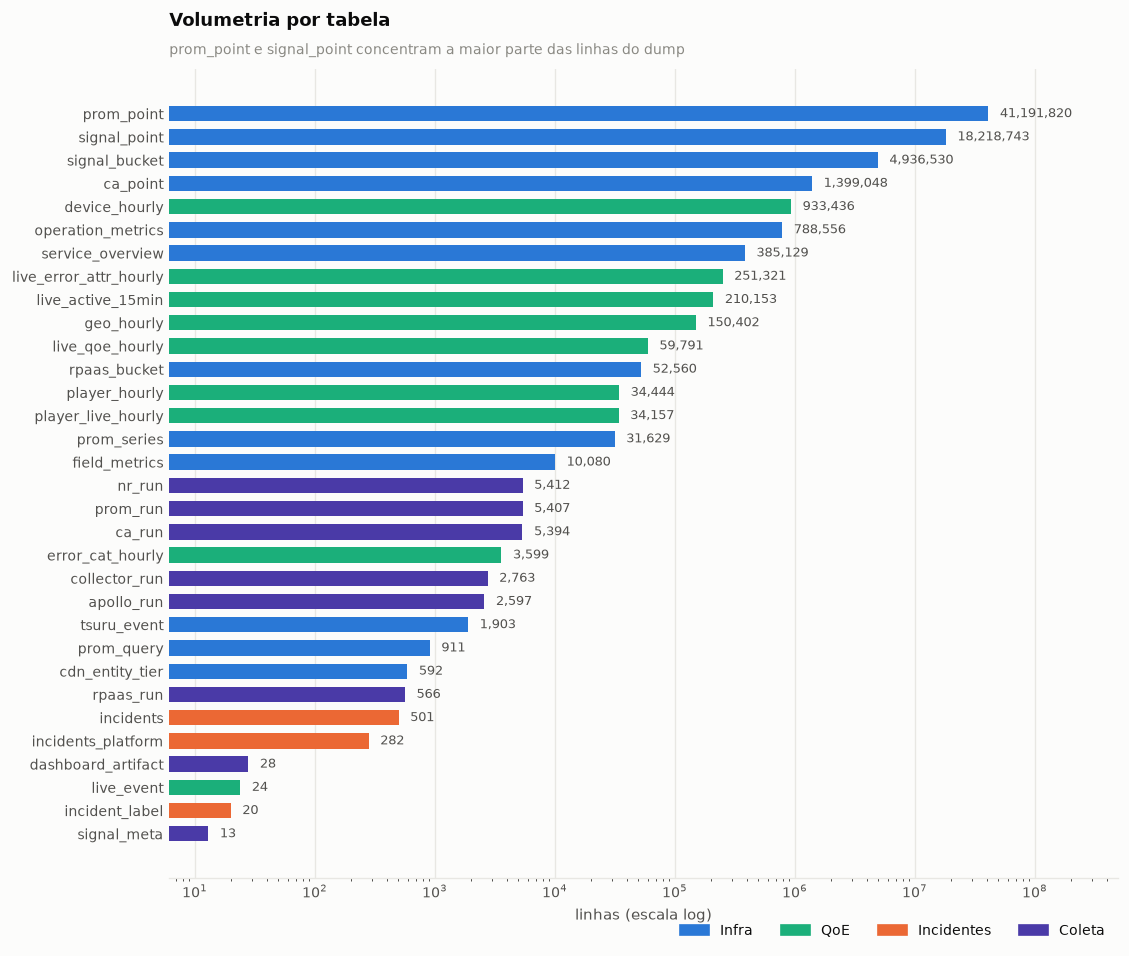

In [4]:
# A escala entre tabelas é de várias ordens de grandeza: eixo logarítmico, e o
# rótulo direto em cada barra dispensa a leitura do eixo.
d = inv[inv.linhas > 0]
f, ax = fig(9.5, 8.0)
cores = {"Infra": CAT[0], "QoE": CAT[2], "Incidentes": CAT[1], "Coleta": CAT[6]}
y = np.arange(len(d))
ax.barh(y, d.linhas, color=[cores[x] for x in d.dominio], height=0.66)
ax.set_yticks(y, d.tabela)
ax.set_xscale("log")
ax.invert_yaxis()
sem_grade(ax)
ax.grid(True, axis="x")
ax.set_axisbelow(True)
for yi, v in zip(y, d.linhas):
    ax.text(v * 1.25, yi, f"{v:,.0f}", va="center", fontsize=8, color=INK2)
ax.set_xlim(right=d.linhas.max() * 12)
ax.spines["left"].set_visible(False)
ax.set_xlabel("linhas (escala log)")
handles = [mpl.patches.Patch(color=c, label=k) for k, c in cores.items()]
ax.legend(handles=handles, ncol=4, loc="lower right", bbox_to_anchor=(1, -0.09))
titulo(ax, "Volumetria por tabela",
       "prom_point e signal_point concentram a maior parte das linhas do dump")
plt.tight_layout()
plt.show()

Duas tabelas de séries temporais concentram quase todo o volume. Isso importa
para o desenho da solução: o custo de armazenamento e de varredura é dominado
pela telemetria bruta, enquanto as tabelas que carregam **significado de
negócio** — incidentes, rótulos, eventos ao vivo — são pequenas o bastante para
caber em memória. Um sistema de correlação pode manter o lado semântico quente e
tratar a telemetria sob demanda.

## 1.2. Cobertura temporal

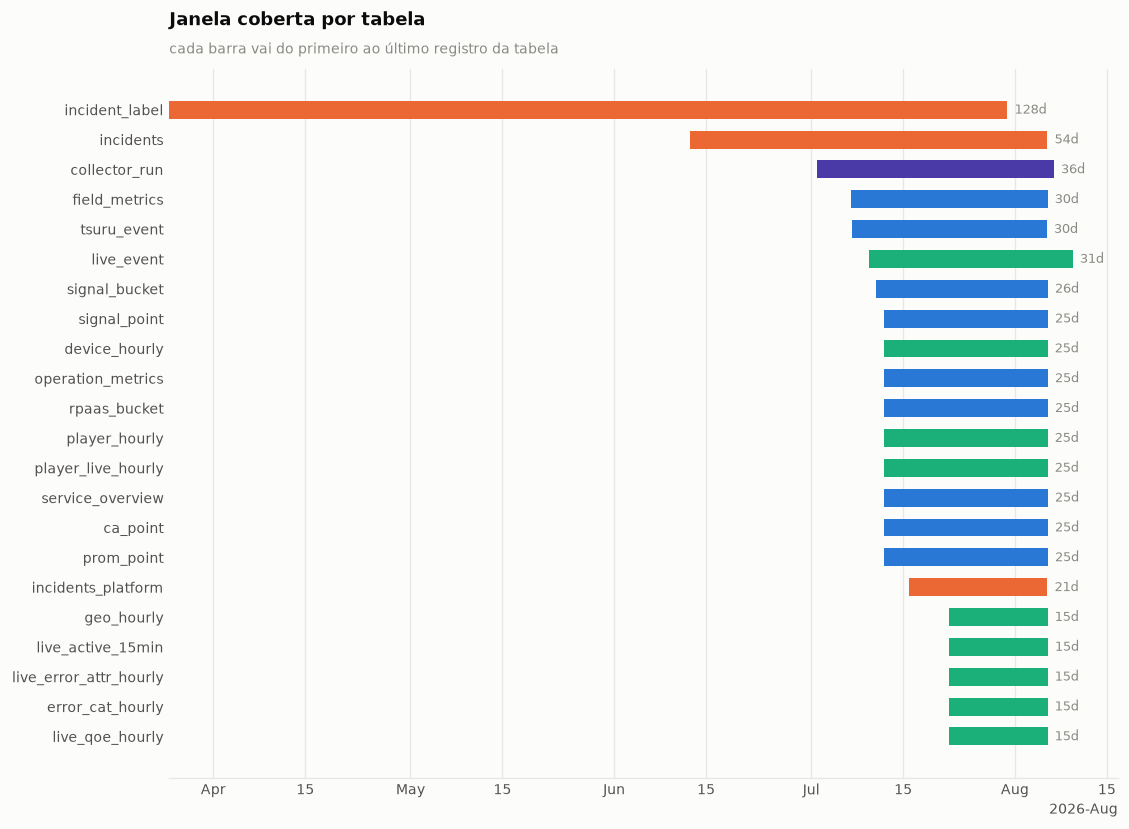

janela comum às tabelas com >1k linhas: 2026-07-22 a 2026-08-05


In [5]:
d = inv.dropna(subset=["inicio"]).sort_values("inicio")
f, ax = fig(9.5, 7.0)
y = np.arange(len(d))
ini = mpl.dates.date2num(pd.to_datetime(d.inicio))
fim = mpl.dates.date2num(pd.to_datetime(d.fim))
ax.barh(y, fim - ini, left=ini, height=0.6,
        color=[cores[x] for x in d.dominio])
ax.set_yticks(y, d.tabela)
ax.invert_yaxis()
ax.xaxis_date()
sem_grade(ax)
ax.grid(True, axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
for yi, a, b in zip(y, ini, fim):
    ax.text(b + (fim.max() - ini.min()) * 0.008, yi,
            f"{b - a:.0f}d", va="center", fontsize=8, color=INK3)
titulo(ax, "Janela coberta por tabela",
       "cada barra vai do primeiro ao último registro da tabela")
plt.tight_layout()
plt.show()

nucleo = d[d.linhas > 1000]
print(f"janela comum às tabelas com >1k linhas: "
      f"{nucleo.inicio.max():%Y-%m-%d} a {nucleo.fim.min():%Y-%m-%d}")

As janelas **não coincidem**. Qualquer cruzamento entre camadas precisa ser
recortado pela interseção, sob pena de ler como "queda" o que é apenas ausência
de coleta. A janela comum impressa acima é a régua usada na seção 7.

## 1.3. Granularidade temporal

In [6]:
# Passos "canônicos" de coleta em segundos — a grade real de cada fonte é
# aproximada pelo canônico mais próximo do intervalo mediano observado.
CANONICOS = [1, 5, 10, 15, 30, 60, 120, 300, 600, 900, 1800, 3600, 86400]


def formata_passo(seg: float) -> str:
    if seg < 60:
        return f"{seg:,.0f} s"
    if seg < 3600:
        return f"{seg / 60:,.0f} min"
    if seg < 86400:
        return f"{seg / 3600:,.1f} h"
    return f"{seg / 86400:,.1f} d"


EVENTOS = {"tsuru_event", "incidents", "incidents_platform", "live_event",
           "incident_label", "collector_run"}

linhas = []
for t, c in COL_TEMPO.items():
    if t not in TABLES or inv.loc[inv.tabela == t, "linhas"].iloc[0] < 10:
        continue
    r = q(f"""
        WITH d AS (SELECT DISTINCT {c} v FROM {t}),
             g AS (SELECT v, v - lag(v) OVER (ORDER BY v) delta FROM d)
        SELECT count(*) instantes, median(delta) mediana, max(delta) maior
        FROM g
    """).iloc[0]
    med_s = (r.mediana or 0) / 1000
    passo = min(CANONICOS, key=lambda k: abs(np.log(k / max(med_s, 1e-9))))
    # quanto dos instantes cai exatamente sobre a grade canônica?
    alin = q(f"""
        SELECT 100.0 * count(*) FILTER (WHERE {c} % {passo * 1000} = 0)
             / count(*) pct FROM (SELECT DISTINCT {c} FROM {t})
    """).pct.iloc[0]
    linhas.append({
        "tabela": t, "coluna": c, "instantes": int(r.instantes),
        "tipo": "evento" if t in EVENTOS else "série",
        "gap_mediano": formata_passo(med_s),
        "grade_estimada": formata_passo(passo) if t not in EVENTOS else "—",
        "alinhado_pct": round(alin, 1) if t not in EVENTOS else np.nan,
        "maior_gap": formata_passo((r.maior or 0) / 1000),
    })

gran = pd.DataFrame(linhas).sort_values(["tipo", "tabela"]).reset_index(drop=True)
gran

,tabela,coluna,instantes,tipo,gap_mediano,grade_estimada,alinhado_pct,maior_gap
0,collector_run,started_at,2499,evento,15 min,—,NaN,11.9 h
1,incident_label,ts_start,20,evento,5.0 d,—,NaN,25.5 d
2,incidents,opened_at,501,evento,52 min,—,NaN,21.2 h
3,incidents_platform,opened_at,282,evento,44 min,—,NaN,14.9 h
4,live_event,start_ts,12,evento,3.2 d,—,NaN,5.0 d
5,tsuru_event,start_time_ms,1903,evento,2 s,—,NaN,15.0 h
6,ca_point,ts_ms,139920,série,2 s,1 s,100,2 min
7,device_hourly,hour_ts,600,série,1.0 h,1.0 h,100,1.0 h
8,error_cat_hourly,hour_ts,360,série,1.0 h,1.0 h,100,1.0 h
9,field_metrics,start_ts,720,série,1.0 h,1.0 h,100,1.0 h


Duas leituras importam aqui.

**As grades são heterogêneas.** As fontes agregadas (`*_hourly`, `rpaas_bucket`,
`signal_bucket`) vivem em grades limpas de 15 minutos ou 1 hora, com 100% dos
instantes alinhados. Já a telemetria bruta (`signal_point`, `prom_point`,
`ca_point`, `service_overview`) tem **quase nenhum instante alinhado** a uma
grade: os timestamps carregam o jitter do momento em que o coletor rodou.

**Consequência prática:** essas fontes não podem ser unidas por igualdade de
timestamp. Qualquer cruzamento entre elas exige reamostragem para uma grade
comum — e a mais grossa entre todas as fontes é a de 1 hora, que é a régua usada
na seção 7. Um `JOIN ... USING (timestamp)` ingênuo entre `signal_point` e
`prom_point` retornaria quase nada, apesar de ambas cobrirem o mesmo período.

---
# 2. Qualidade dos dados

Um dado de observabilidade herda os defeitos do caminho que percorreu: coletor
que falhou, série que sumiu, campo que o fornecedor parou de preencher. Esta
seção mede quatro coisas — preenchimento, cardinalidade, integridade e
continuidade — porque cada uma invalida um tipo diferente de conclusão adiante.

## 2.1. Preenchimento das colunas

In [7]:
nulos = []
for t in TABLES:
    n = inv.loc[inv.tabela == t, "linhas"].iloc[0]
    if n == 0:
        continue
    cols = q(f"SELECT * FROM {t} LIMIT 0").columns
    expr = ", ".join(f'count("{c}") AS "{c}"' for c in cols)
    preenchidos = q(f"SELECT {expr} FROM {t}").iloc[0]
    for c in cols:
        nulos.append({"tabela": t, "coluna": c, "linhas": n,
                      "pct_nulo": 100 * (1 - preenchidos[c] / n)})

nulos = pd.DataFrame(nulos)
vazias = nulos[nulos.pct_nulo == 100]
print(f"{len(nulos)} colunas analisadas em {nulos.tabela.nunique()} tabelas")
print(f"{len(vazias)} colunas 100% nulas | "
      f"{len(nulos[nulos.pct_nulo.between(0.001, 100, inclusive='left')])} parcialmente nulas")
vazias[["tabela", "coluna"]].reset_index(drop=True)

312 colunas analisadas em 32 tabelas
29 colunas 100% nulas | 58 parcialmente nulas


,tabela,coluna
0,ca_run,notes
1,incidents,short_description
2,incidents,subcategory
3,incidents,cause
4,incidents,caused_by
5,incidents,u_what_s_the_root_cause
6,incidents,close_notes
7,incidents,scr_vendor
8,incidents,scr_vendor_point_of_contact
9,incidents,scr_vendor_ticket


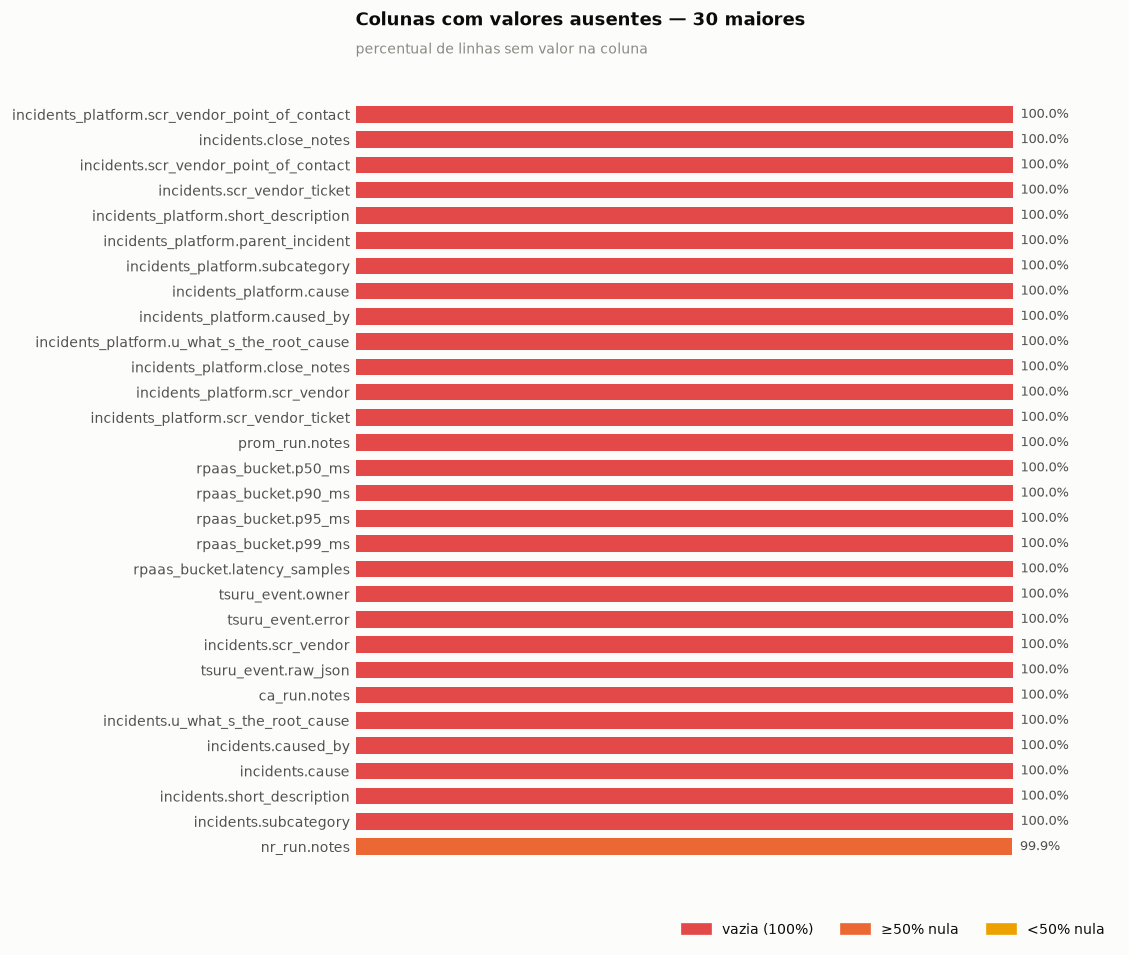

In [8]:
# Só as colunas que de fato têm nulos entram no gráfico — listar as completas
# não informa nada.
d = nulos[nulos.pct_nulo > 0].sort_values("pct_nulo", ascending=False).head(30)
f, ax = fig(9.5, 8.0)
rot = [f"{r.tabela}.{r.coluna}" for r in d.itertuples()]
cor = [STATUS["critical"] if v == 100 else
       STATUS["serious"] if v >= 50 else STATUS["warning"]
       for v in d.pct_nulo]
y = np.arange(len(d))
ax.barh(y, d.pct_nulo, color=cor, height=0.66)
ax.set_yticks(y, rot)
ax.invert_yaxis()
sem_grade(ax)
ax.set_xticks([])
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
for yi, v in zip(y, d.pct_nulo):
    ax.text(v + 1.2, yi, f"{v:.1f}%", va="center", fontsize=8, color=INK2)
ax.set_xlim(0, 116)
handles = [mpl.patches.Patch(color=STATUS[k], label=lab) for k, lab in
           [("critical", "vazia (100%)"), ("serious", "≥50% nula"),
            ("warning", "<50% nula")]]
ax.legend(handles=handles, ncol=3, loc="lower right", bbox_to_anchor=(1, -0.07))
titulo(ax, "Colunas com valores ausentes — 30 maiores",
       "percentual de linhas sem valor na coluna")
plt.tight_layout()
plt.show()

## 2.2. Cardinalidade e colunas constantes

In [9]:
# Coluna constante não separa nada: ou o campo foi zerado na sanitização, ou o
# recorte cedido tem um valor só. Em ambos os casos ela não serve de dimensão.
card = []
for t in TABLES:
    n = inv.loc[inv.tabela == t, "linhas"].iloc[0]
    if n == 0:
        continue
    cols = q(f"SELECT * FROM {t} LIMIT 0").columns
    expr = ", ".join(f'count(DISTINCT "{c}") AS "{c}"' for c in cols)
    distintos = q(f"SELECT {expr} FROM {t}").iloc[0]
    for c in cols:
        card.append({"tabela": t, "coluna": c, "distintos": int(distintos[c]),
                     "linhas": n, "razao": distintos[c] / n})

card = pd.DataFrame(card)
const = card[(card.distintos <= 1) & (card.linhas > 100)]
print(f"{len(const)} colunas constantes ou vazias em tabelas com >100 linhas:")
const.merge(nulos.drop(columns="linhas"), on=["tabela", "coluna"])[
    ["tabela", "coluna", "distintos", "pct_nulo", "linhas"]
].reset_index(drop=True)

48 colunas constantes ou vazias em tabelas com >100 linhas:


,tabela,coluna,distintos,pct_nulo,linhas
0,apollo_run,kind,1,0,2597
1,ca_run,notes,0,100,5394
2,field_metrics,error_count,1,0,10080
3,incidents,short_description,0,100,501
4,incidents,u_this_incident_caused_external_impacts,1,0,501
5,incidents,subcategory,0,100,501
6,incidents,cause,0,100,501
7,incidents,caused_by,0,100,501
8,incidents,u_what_s_the_root_cause,0,100,501
9,incidents,impact_component,1,15.17,501


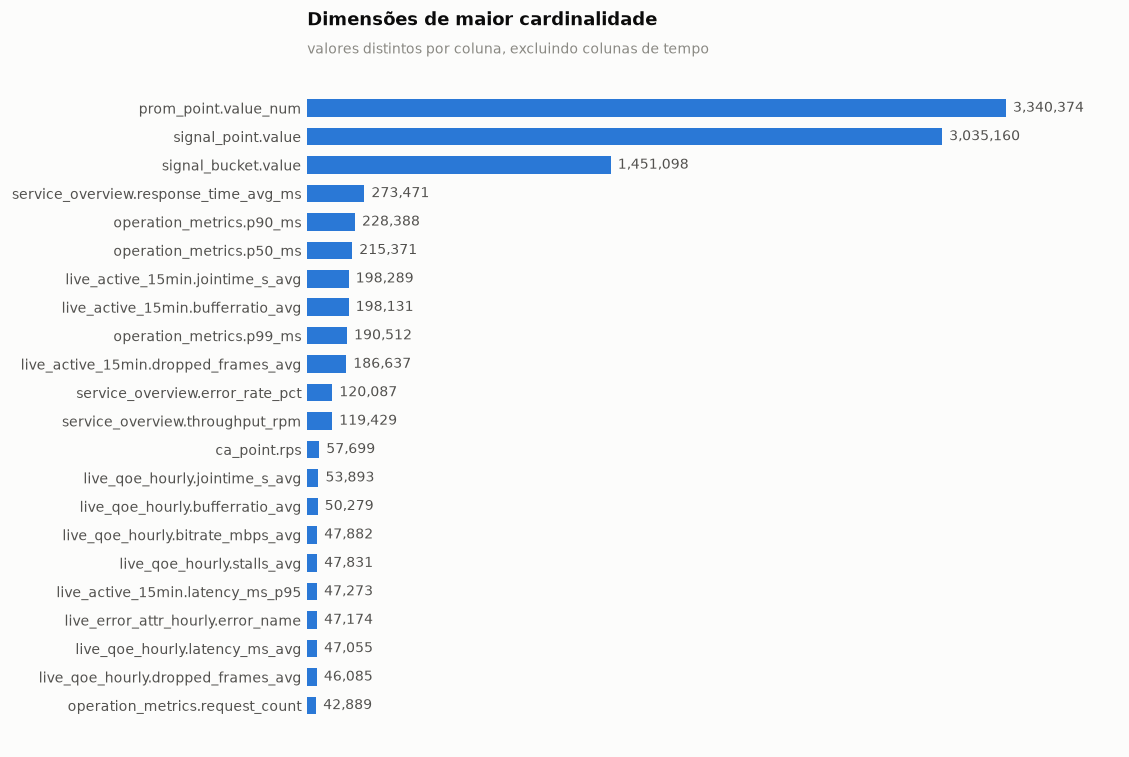

In [10]:
# Dimensões de alta cardinalidade são as candidatas naturais a recorte de
# investigação — e as que mais pesam no custo de uma suíte comercial cobrada
# por cardinalidade.
d = card[(card.distintos > 1) & (~card.coluna.isin(COL_TEMPO.values()))]
d = d.sort_values("distintos", ascending=False).head(22)
f, ax = fig(9.5, 6.4)
barras_h(ax, [f"{r.tabela}.{r.coluna}" for r in d.itertuples()],
         d.distintos.values, color=CAT[0])
titulo(ax, "Dimensões de maior cardinalidade",
       "valores distintos por coluna, excluindo colunas de tempo")
plt.tight_layout()
plt.show()

## 2.3. Integridade: chaves e referências

In [11]:
# Chaves primárias declaradas no DDL. Duplicata aqui indicaria falha do dump.
PK = {
    "signal_point": ["ts", "source", "entity", "metric"],
    "signal_bucket": ["source", "entity", "metric", "bts"],
    "prom_point": ["epoch_ms", "series_id"],
    "rpaas_bucket": ["bucket_ts_ms", "region", "vhost"],
    "ca_point": ["ts_ms", "app", "blocked"],
    "service_overview": ["timestamp", "app_name"],
    "operation_metrics": ["start_ts", "operation_name"],
    "field_metrics": ["start_ts", "coordinate"],
    "tsuru_event": ["start_time_ms", "uniqueid"],
    "player_hourly": ["hour_ts", "player"],
    "device_hourly": ["hour_ts", "device"],
    "geo_hourly": ["hour_ts", "state_province", "isp"],
    "live_qoe_hourly": ["hour_ts", "sinal"],
    "player_live_hourly": ["hour_ts", "player"],
    "live_active_15min": ["bucket_ts", "sinal"],
    "live_error_attr_hourly": ["hour_ts", "sinal", "cdn", "tier",
                               "http_code", "error_name"],
    "error_cat_hourly": ["hour_ts", "kind", "category"],
    "incidents": ["opened_at", "sys_id"],
    "incidents_platform": ["opened_at", "sys_id"],
    "incident_label": ["id"],
    "live_event": ["tid", "start_ts"],
    "prom_series": ["series_id"], "prom_query": ["query_id"],
}

res = []
for t, k in PK.items():
    if t not in TABLES:
        continue
    cols = ", ".join(k)
    r = q(f"SELECT count(*) n, count(DISTINCT ({cols})) d FROM {t}").iloc[0]
    res.append({"tabela": t, "pk": " + ".join(k), "linhas": int(r.n),
                "pk_distintas": int(r.d), "duplicatas": int(r.n - r.d)})

pk = pd.DataFrame(res)
print("PKs com duplicata:", (pk.duplicatas > 0).sum(), "de", len(pk))
pk.sort_values("duplicatas", ascending=False).reset_index(drop=True)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

PKs com duplicata: 0 de 23


,tabela,pk,linhas,pk_distintas,duplicatas
0,signal_point,ts + source + entity + metric,18218743,18218743,0
1,live_qoe_hourly,hour_ts + sinal,59791,59791,0
2,prom_series,series_id,31629,31629,0
3,live_event,tid + start_ts,24,24,0
4,incident_label,id,20,20,0
5,incidents_platform,opened_at + sys_id,282,282,0
6,incidents,opened_at + sys_id,501,501,0
7,error_cat_hourly,hour_ts + kind + category,3599,3599,0
8,live_error_attr_hourly,hour_ts + sinal + cdn + tier + http_code + err...,251321,251321,0
9,live_active_15min,bucket_ts + sinal,210153,210153,0


In [12]:
# Integridade referencial do subsistema Prometheus, o único com FK declarada:
# prom_point -> prom_series -> prom_query.
print(q("""
    SELECT 'pontos sem série'  AS verificacao,
           count(*)            AS violacoes
    FROM prom_point p LEFT JOIN prom_series s USING (series_id)
    WHERE s.series_id IS NULL
    UNION ALL
    SELECT 'séries sem query',  count(*)
    FROM prom_series s LEFT JOIN prom_query qy USING (query_id)
    WHERE qy.query_id IS NULL
    UNION ALL
    SELECT 'séries sem ponto',  count(*)
    FROM prom_series s LEFT JOIN (SELECT DISTINCT series_id FROM prom_point) p
      USING (series_id)
    WHERE p.series_id IS NULL
    UNION ALL
    SELECT 'queries sem série', count(*)
    FROM prom_query qy LEFT JOIN (SELECT DISTINCT query_id FROM prom_series) s
      USING (query_id)
    WHERE s.query_id IS NULL
""").to_string(index=False))

# signal_bucket deveria ser a reamostragem de signal_point: as chaves batem?
print()
print(q("""
    SELECT count(*) FILTER (WHERE p.source IS NULL) AS so_em_bucket,
           count(*) FILTER (WHERE b.source IS NULL) AS so_em_point,
           count(*) FILTER (WHERE p.source IS NOT NULL
                              AND b.source IS NOT NULL) AS em_ambos
    FROM (SELECT DISTINCT source, metric FROM signal_bucket) b
    FULL OUTER JOIN (SELECT DISTINCT source, metric FROM signal_point) p
      USING (source, metric)
""").to_string(index=False))

      verificacao  violacoes
 pontos sem série          0
 séries sem query          0
 séries sem ponto      23252
queries sem série        532



 so_em_bucket  so_em_point  em_ambos
            0            2        73


## 2.4. Continuidade das séries temporais

In [13]:
# Um buraco na série é indistinguível de "métrica zerada" para quem lê o
# gráfico. Como os timestamps brutos têm jitter (seção 1.3), a continuidade é
# medida por ocupação da grade horária: toda hora do intervalo coberto pela
# tabela deveria ter ao menos uma linha.
res = []
for t, c in COL_TEMPO.items():
    if t not in TABLES or t in EVENTOS:
        continue
    n = inv.loc[inv.tabela == t, "linhas"].iloc[0]
    if n < 1000:
        continue
    r = q(f"""
        WITH h AS (
            SELECT ({c} // 3600000) * 3600000 AS hora, count(*) linhas
            FROM {t} GROUP BY 1
        )
        SELECT count(*) horas_obs, min(hora) a, max(hora) b,
               median(linhas) linhas_medianas,
               count(*) FILTER (WHERE linhas < 0.5 * (SELECT median(linhas) FROM h))
                   AS horas_rarefeitas
        FROM h
    """).iloc[0]
    esperadas = int((r.b - r.a) / 3600000) + 1
    res.append({"tabela": t, "horas_obs": int(r.horas_obs),
                "horas_esp": esperadas,
                "cobertura_pct": 100 * r.horas_obs / esperadas,
                "horas_vazias": esperadas - int(r.horas_obs),
                "linhas_por_hora": int(r.linhas_medianas),
                "horas_rarefeitas": int(r.horas_rarefeitas)})

cont = pd.DataFrame(res).sort_values("cobertura_pct").reset_index(drop=True)
cont

,tabela,horas_obs,horas_esp,cobertura_pct,horas_vazias,linhas_por_hora,horas_rarefeitas
0,signal_point,600,600,100,0,24847,0
1,signal_bucket,630,630,100,0,6178,1
2,service_overview,600,600,100,0,616,46
3,operation_metrics,600,600,100,0,485,0
4,field_metrics,720,720,100,0,14,0
5,prom_point,600,600,100,0,69160,0
6,rpaas_bucket,600,600,100,0,87,0
7,ca_point,600,600,100,0,2200,5
8,player_hourly,600,600,100,0,57,0
9,device_hourly,600,600,100,0,1639,24


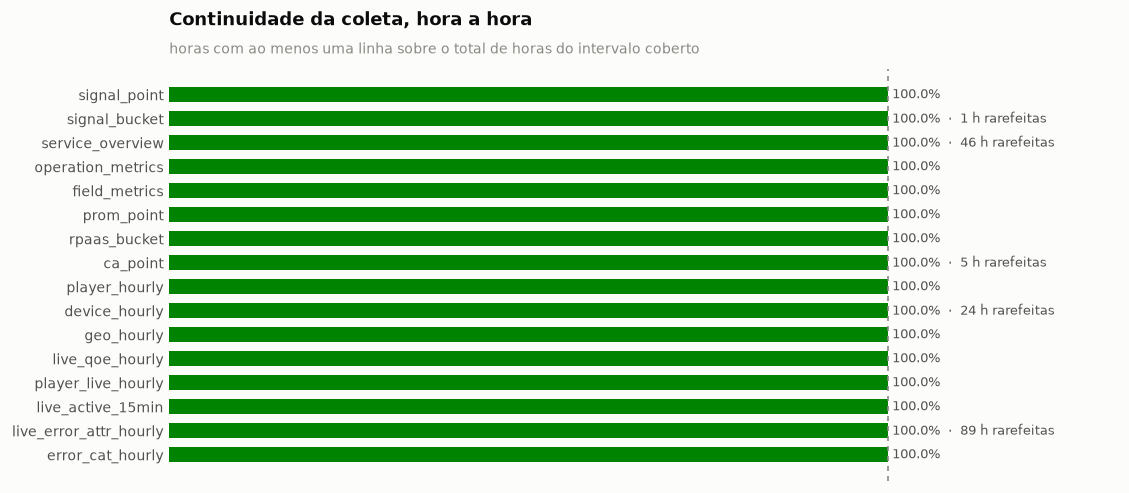

In [14]:
d = cont.sort_values("cobertura_pct")
f, ax = fig(9.5, 4.2)
y = np.arange(len(d))
cor = [STATUS["good"] if v >= 99 else STATUS["warning"] if v >= 90
       else STATUS["critical"] for v in d.cobertura_pct]
ax.barh(y, d.cobertura_pct, color=cor, height=0.62)
ax.set_yticks(y, d.tabela)
ax.invert_yaxis()
ax.axvline(100, color=INK3, lw=1, ls=(0, (3, 3)))
sem_grade(ax)
ax.set_xticks([])
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
for yi, v, fal, rar in zip(y, d.cobertura_pct, d.horas_vazias, d.horas_rarefeitas):
    partes = [f"{v:.1f}%"]
    if fal:
        partes.append(f"{fal:,} h sem dado")
    if rar:
        partes.append(f"{rar:,} h rarefeitas")
    ax.text(v + 0.6, yi, "  ·  ".join(partes), va="center", fontsize=8, color=INK2)
ax.set_xlim(0, 132)
titulo(ax, "Continuidade da coleta, hora a hora",
       "horas com ao menos uma linha sobre o total de horas do intervalo coberto")
plt.tight_layout()
plt.show()

"Horas rarefeitas" são horas presentes na base, mas com menos da metade do
volume mediano de linhas — degradação parcial da coleta, que não aparece como
buraco e por isso é o modo de falha mais traiçoeiro: a série continua desenhando,
só que sobre menos amostras.

## 2.5. Valores fora do domínio esperado

In [15]:
# Regras de sanidade derivadas do significado de cada campo: contagem não é
# negativa, percentual vive em [0,100], Apdex em [0,1], percentis são monótonos.
checagens = [
    ("signal_bucket", "taxa de erro % fora de [0,100]",
     "metric LIKE '%rate_pct' AND (value < 0 OR value > 100)"),
    ("service_overview", "apdex fora de [0,1]",
     "apdex_score < 0 OR apdex_score > 1"),
    ("service_overview", "error_rate_pct fora de [0,100]",
     "error_rate_pct < 0 OR error_rate_pct > 100"),
    ("service_overview", "throughput negativo", "throughput_rpm < 0"),
    ("service_overview", "tempo de resposta negativo", "response_time_avg_ms < 0"),
    ("operation_metrics", "erros > requisições", "error_count > request_count"),
    ("operation_metrics", "percentis não monótonos (p50>p90 ou p90>p99)",
     "p50_ms > p90_ms OR p90_ms > p99_ms"),
    ("field_metrics", "erros > requisições", "error_count > request_count"),
    ("rpaas_bucket", "soma de status ≠ total",
     "requests_2xx + requests_3xx + requests_4xx + requests_5xx <> requests_total"),
    ("rpaas_bucket", "percentis não monótonos",
     "p50_ms > p90_ms OR p90_ms > p95_ms OR p95_ms > p99_ms"),
    ("rpaas_bucket", "contagem negativa", "requests_total < 0"),
    ("ca_point", "rps negativo", "rps < 0"),
    ("player_hourly", "erros > sessões", "errors > sessions"),
    ("device_hourly", "erros > sessões", "errors > sessions"),
    ("geo_hourly", "erros > sessões", "errors > sessions"),
    ("live_qoe_hourly", "erros > sessões", "errors > sessions"),
    ("live_qoe_hourly", "erros de startup > erros", "startup_errors > errors"),
    ("live_qoe_hourly", "bufferratio fora de [0,100]",
     "bufferratio_avg < 0 OR bufferratio_avg > 100"),
    ("live_qoe_hourly", "latência p50 > p95", "latency_ms_p50 > latency_ms_p95"),
    ("player_live_hourly", "erros > sessões", "errors > sessions"),
    ("live_active_15min", "sessões com erro > ativas",
     "active_with_error > active_sessions"),
    ("live_active_15min", "latência p50 > p95", "latency_ms_p50 > latency_ms_p95"),
    ("incidents", "resolvido antes de aberto", "resolved_at < opened_at"),
    ("incidents", "fechado antes de resolvido", "closed_at < resolved_at"),
    ("incidents_platform", "resolvido antes de aberto", "resolved_at < opened_at"),
    ("live_event", "fim antes do início", "end_ts < start_ts"),
    ("tsuru_event", "duração negativa", "duration_ms < 0"),
    ("incident_label", "fim antes do início", "ts_end < ts_start"),
]

res = []
for t, nome, cond in checagens:
    if t not in TABLES:
        continue
    n = q(f"SELECT count(*) n FROM {t} WHERE {cond}").n.iloc[0]
    tot = inv.loc[inv.tabela == t, "linhas"].iloc[0]
    res.append({"tabela": t, "regra": nome, "violacoes": int(n),
                "pct": 100 * n / tot if tot else 0})

san = pd.DataFrame(res)
print(f"{(san.violacoes > 0).sum()} de {len(san)} regras violadas")
san[san.violacoes > 0].sort_values("violacoes", ascending=False).reset_index(drop=True)

3 de 28 regras violadas


,tabela,regra,violacoes,pct
0,rpaas_bucket,soma de status ≠ total,17,0.03234
1,live_qoe_hourly,erros > sessões,12,0.02007
2,tsuru_event,duração negativa,2,0.1051


In [16]:
ok = san[san.violacoes == 0]
print(f"regras sem nenhuma violação ({len(ok)}):")
for r in ok.itertuples():
    print(f"  ✓ {r.tabela:<22} {r.regra}")

regras sem nenhuma violação (25):
  ✓ signal_bucket          taxa de erro % fora de [0,100]
  ✓ service_overview       apdex fora de [0,1]
  ✓ service_overview       error_rate_pct fora de [0,100]
  ✓ service_overview       throughput negativo
  ✓ service_overview       tempo de resposta negativo
  ✓ operation_metrics      erros > requisições
  ✓ operation_metrics      percentis não monótonos (p50>p90 ou p90>p99)
  ✓ field_metrics          erros > requisições
  ✓ rpaas_bucket           percentis não monótonos
  ✓ rpaas_bucket           contagem negativa
  ✓ ca_point               rps negativo
  ✓ player_hourly          erros > sessões
  ✓ device_hourly          erros > sessões
  ✓ geo_hourly             erros > sessões
  ✓ live_qoe_hourly        erros de startup > erros
  ✓ live_qoe_hourly        bufferratio fora de [0,100]
  ✓ live_qoe_hourly        latência p50 > p95
  ✓ player_live_hourly     erros > sessões
  ✓ live_active_15min      sessões com erro > ativas
  ✓ live_active_15min 

---
# 3. Telemetria de infraestrutura

Sete fontes distintas descrevem a mesma cadeia de entrega por ângulos
diferentes: borda (RPaaS), proteção (Cloud Armor), plataforma (Prometheus,
Tsuru), aplicação (New Relic) e API (Apollo/GraphQL). O interesse aqui é duplo —
entender o que cada fonte mede e verificar se elas contam a mesma história sobre
os mesmos instantes.

## 3.1. Sinais normalizados: `signal_point` e `signal_bucket`

`signal_point` é o barramento normalizado do Argus: toda fonte deságua nele com
o mesmo formato `(ts, source, entity, metric, value, tags)`. `signal_bucket` é a
reamostragem desse barramento em janelas fixas. É a estrutura mais próxima do
"vocabulário comum" que o projeto propõe, e por isso vale entender sua forma.

In [17]:
sp = q("""
    SELECT source,
           count(*)                 linhas,
           count(DISTINCT entity)   entidades,
           count(DISTINCT metric)   metricas,
           count(DISTINCT ts)       instantes,
           to_timestamp(min(ts)/1000) inicio,
           to_timestamp(max(ts)/1000) fim,
           100.0 * count(tags) / count(*) pct_com_tags
    FROM signal_point GROUP BY 1 ORDER BY 2 DESC
""")
sp

,source,linhas,entidades,metricas,instantes,inicio,fim,pct_com_tags
0,apollo,5522986,633,7,2121,2026-07-12 00:00:00+00:00,2026-08-05 23:52:00+00:00,100
1,prometheus,3435357,185,29,14305,2026-07-12 00:02:09.976000+00:00,2026-08-05 23:56:09.161000+00:00,100
2,redis,3050066,23,10,14236,2026-07-12 00:02:09.976000+00:00,2026-08-05 23:56:09.161000+00:00,100
3,youbora_device,1606772,4666,2,600,2026-07-12 00:00:00+00:00,2026-08-05 23:00:00+00:00,0
4,newrelic,1441830,30,4,14178,2026-07-12 00:00:05+00:00,2026-08-05 23:45:29+00:00,0
5,cloudarmor,1399048,5,2,139920,2026-07-12 00:00:13+00:00,2026-08-05 23:59:28+00:00,100
6,cdn_live_errors,668634,114,1,14190,2026-07-12 00:02:09.976000+00:00,2026-08-05 23:56:09.161000+00:00,0
7,origin_live_errors,528310,112,1,12031,2026-07-12 00:02:09.976000+00:00,2026-08-05 23:56:09.161000+00:00,0
8,youbora_player_live,179790,61,8,600,2026-07-12 00:00:00+00:00,2026-08-05 23:00:00+00:00,100
9,cdn_vod_errors,125291,9,1,13961,2026-07-12 00:02:09.976000+00:00,2026-08-05 23:56:09.161000+00:00,0


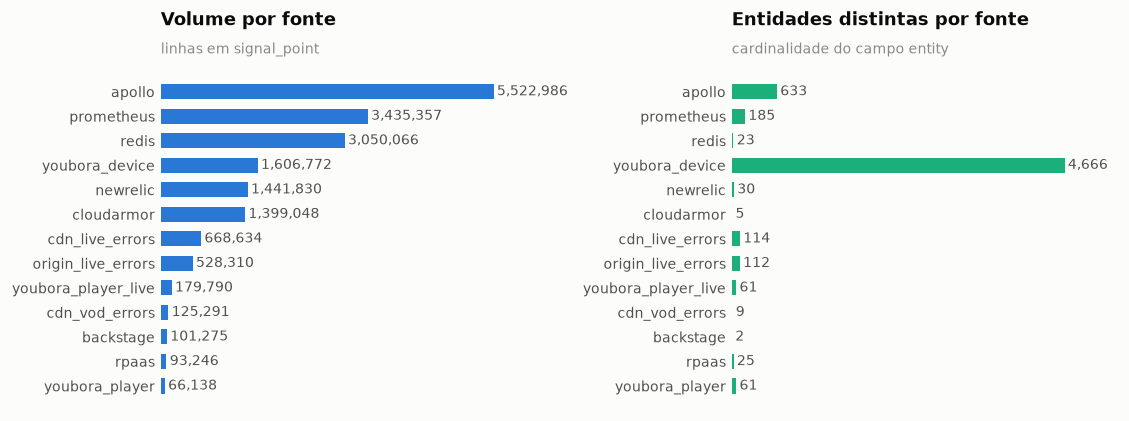

In [18]:
f, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.6))
barras_h(a1, sp.source, sp.linhas.values, color=CAT[0])
titulo(a1, "Volume por fonte", "linhas em signal_point")
barras_h(a2, sp.source, sp.entidades.values, color=CAT[2])
titulo(a2, "Entidades distintas por fonte", "cardinalidade do campo entity")
plt.tight_layout()
plt.show()

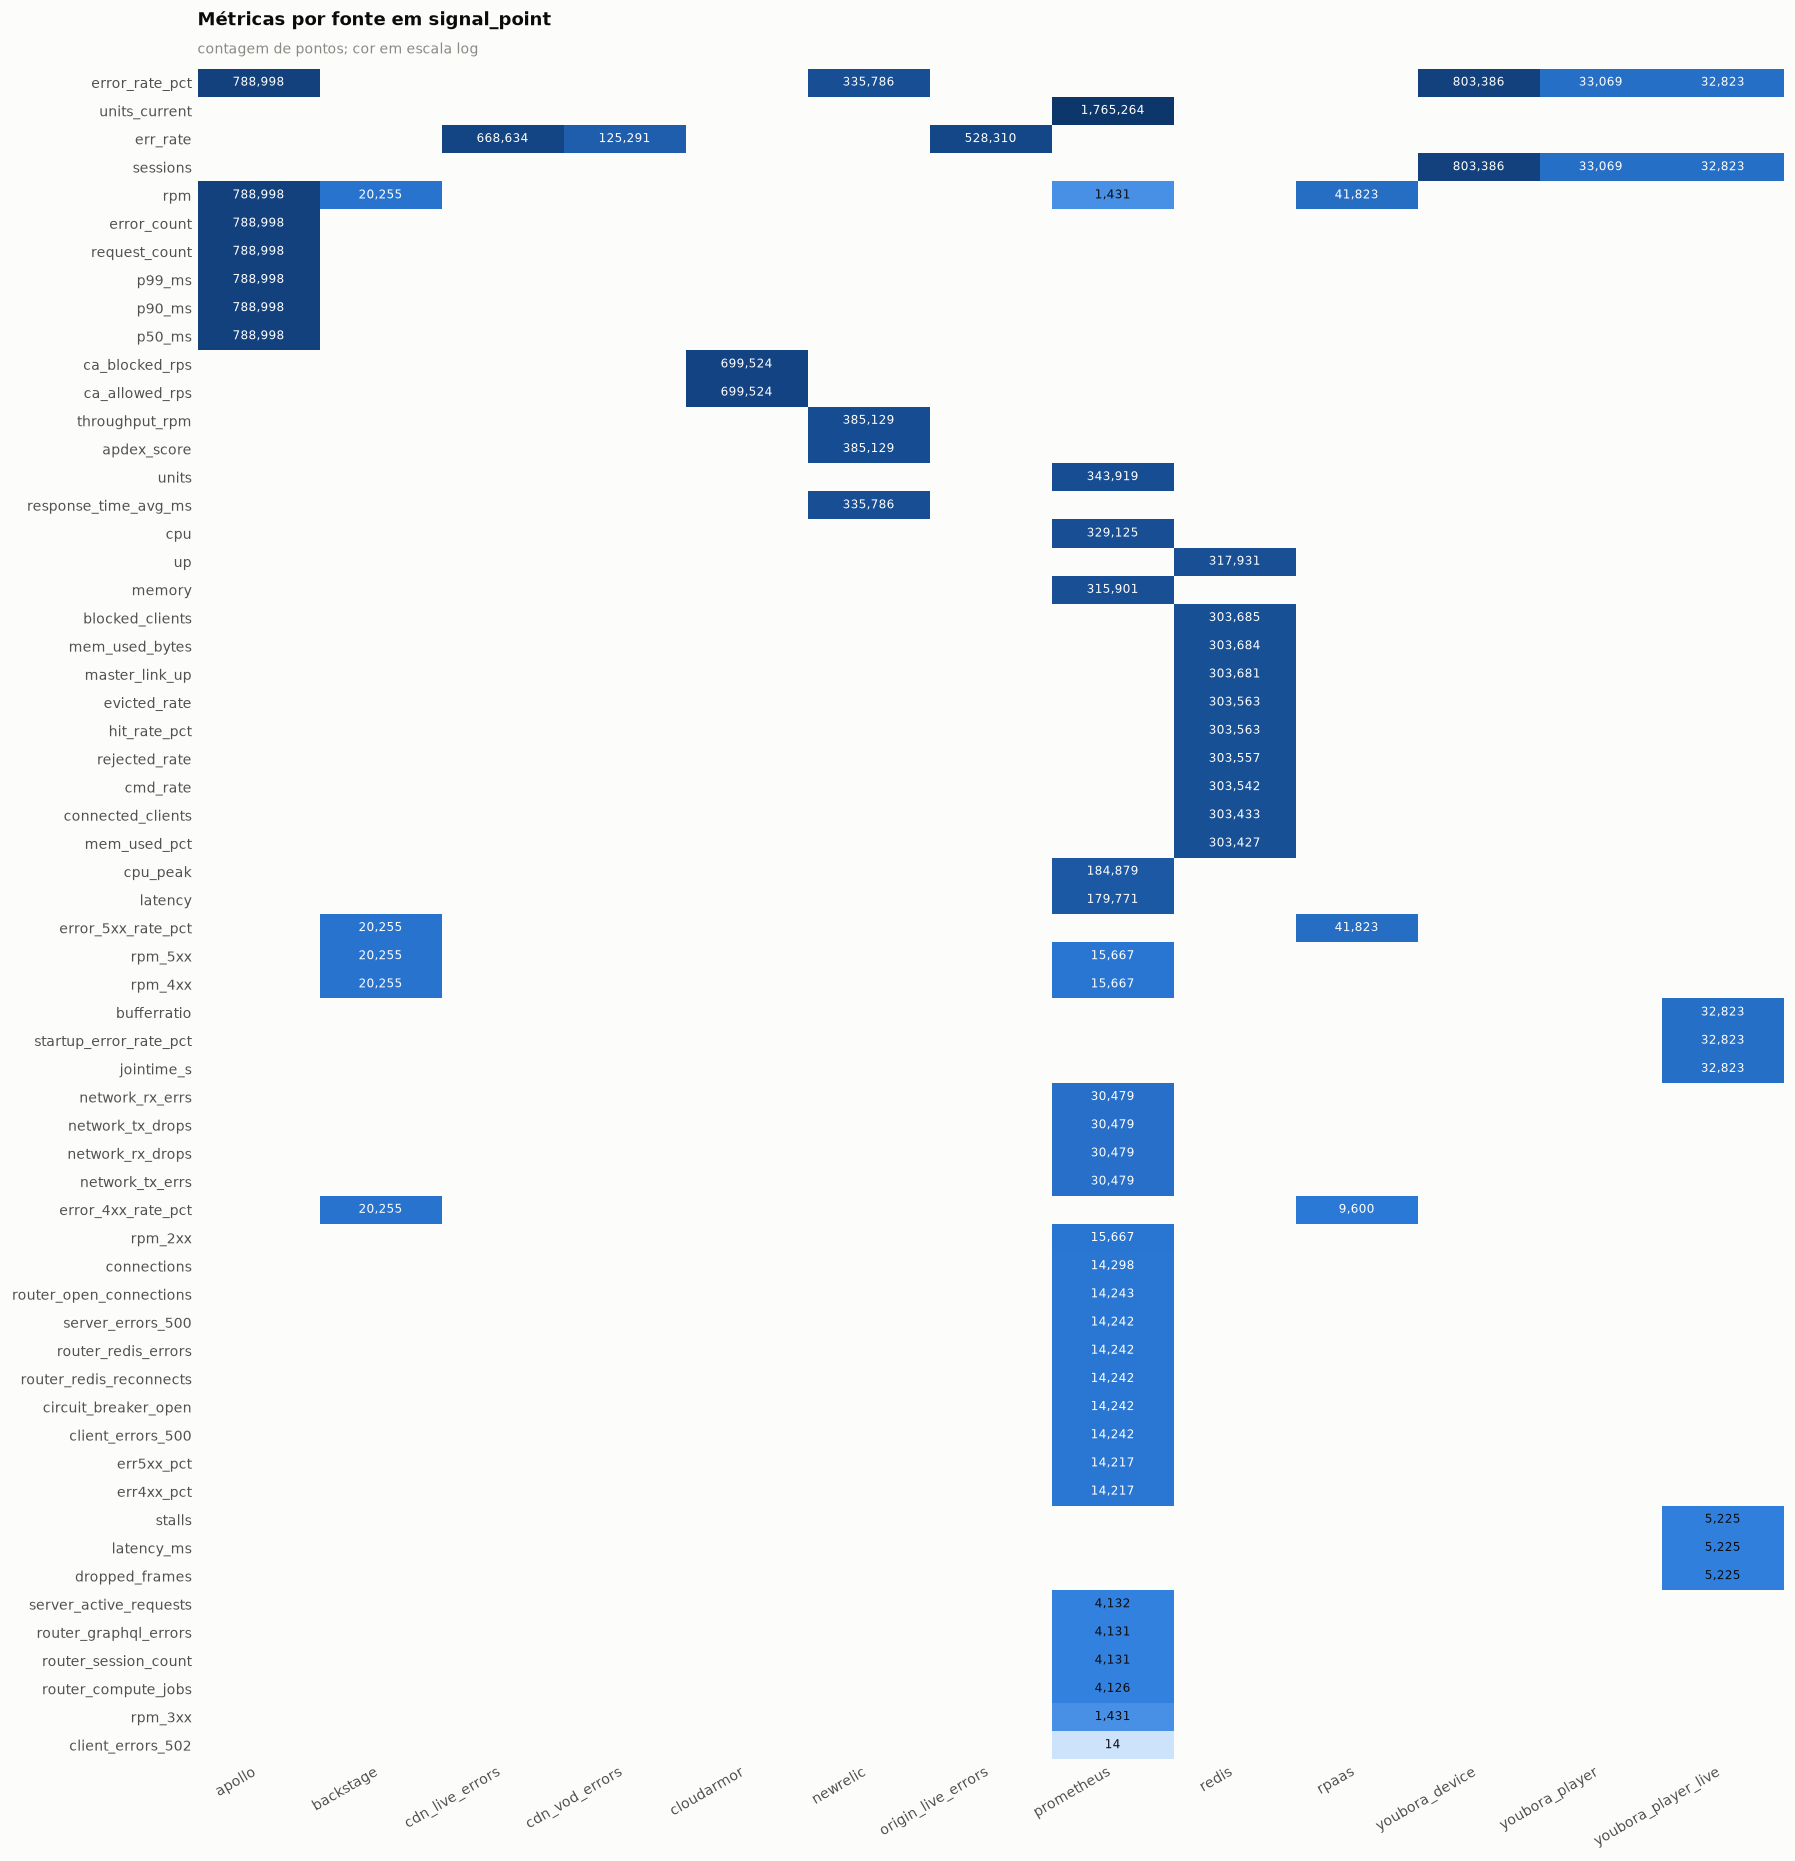

In [19]:
# Matriz fonte × métrica: mostra o vocabulário real de cada coletor e onde há
# sobreposição semântica entre fontes.
m = q("""
    SELECT source, metric, count(*) n FROM signal_point GROUP BY 1, 2
""").pivot(index="metric", columns="source", values="n").fillna(0)
m = m.loc[m.sum(axis=1).sort_values(ascending=False).index]

f, ax = fig(max(6.5, 0.85 * len(m.columns) + 4), max(3.5, 0.26 * len(m)))
# ausência de par fonte×métrica é vazio, não "valor baixo": células zeradas
# recebem a cor da superfície em vez do passo mais claro da rampa.
dados = np.ma.masked_where(m.values == 0, np.log10(m.values + 1))
cmap = SEQ_CMAP.copy()
cmap.set_bad(SURFACE)
im = ax.imshow(dados, cmap=cmap, aspect="auto")
ax.set_xticks(range(len(m.columns)), m.columns, rotation=30, ha="right")
ax.set_yticks(range(len(m)), m.index)
sem_grade(ax)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(m)):
    for j in range(len(m.columns)):
        v = m.values[i, j]
        if v:
            ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=7,
                    color="#ffffff" if dados[i, j] > dados.max() * 0.6 else INK)
titulo(ax, "Métricas por fonte em signal_point",
       "contagem de pontos; cor em escala log")
plt.tight_layout()
plt.show()

In [20]:
# signal_bucket cobre mais fontes que signal_point — vale ver as duas lado a lado.
sb = q("""
    SELECT source, count(*) linhas, count(DISTINCT entity) entidades,
           count(DISTINCT metric) metricas, count(DISTINCT bts) instantes,
           to_timestamp(min(bts)/1000) inicio, to_timestamp(max(bts)/1000) fim
    FROM signal_bucket GROUP BY 1 ORDER BY 2 DESC
""")
sb

,source,linhas,entidades,metricas,instantes,inicio,fim
0,apollo,2933700,633,7,897,2026-07-10 19:00:00+00:00,2026-08-05 23:45:00+00:00
1,prometheus,517136,185,29,2517,2026-07-10 18:45:00+00:00,2026-08-05 23:45:00+00:00
2,redis,347087,23,8,2517,2026-07-10 18:45:00+00:00,2026-08-05 23:45:00+00:00
3,youbora_device,340762,2897,2,629,2026-07-10 19:00:00+00:00,2026-08-05 23:00:00+00:00
4,newrelic,204975,30,4,2517,2026-07-10 18:45:00+00:00,2026-08-05 23:45:00+00:00
5,youbora_player_live,152580,61,8,629,2026-07-10 19:00:00+00:00,2026-08-05 23:00:00+00:00
6,cdn_live_errors,122004,114,1,2515,2026-07-10 18:45:00+00:00,2026-08-05 23:45:00+00:00
7,origin_live_errors,100948,112,1,2217,2026-07-10 18:45:00+00:00,2026-08-05 23:45:00+00:00
8,rpaas,97862,25,3,2517,2026-07-10 18:45:00+00:00,2026-08-05 23:45:00+00:00
9,youbora_player,60348,61,2,629,2026-07-10 19:00:00+00:00,2026-08-05 23:00:00+00:00


In [21]:
d = q("""
    SELECT source, metric, count(*) n, avg(value) media, median(value) mediana,
           min(value) minimo, max(value) maximo, stddev(value) desvio
    FROM signal_bucket GROUP BY 1, 2 HAVING count(*) > 200
    ORDER BY n DESC LIMIT 25
""")
d

,source,metric,n,media,mediana,minimo,maximo,desvio
0,apollo,p90_ms,419100,149.3,84.25,1.042,"2,952",193.5
1,apollo,error_rate_pct,419100,0.588,0,0,100,5.991
2,apollo,p50_ms,419100,44.76,18.22,0.9269,"2,487",86.04
3,apollo,rpm,419100,282.7,13.28,0.01667,8.058e+04,"1,151"
4,apollo,request_count,419100,"7,536",327,1,1.472e+06,3.363e+04
5,apollo,error_count,419100,33.71,0,0,1.549e+05,755
6,apollo,p99_ms,419100,367.2,289.6,1.05,"5,716",320.8
7,prometheus,units_current,312109,4.808,2,1,477,13.94
8,youbora_device,error_rate_pct,170381,1.842,0.5371,0,100,4.664
9,youbora_device,sessions,170381,"6,952",186,1,1.701e+06,4.931e+04


## 3.2. Borda: `rpaas_bucket`

O RPaaS é o proxy reverso na frente das APIs. Cada linha agrega, por região e
por vhost, o volume por classe de status HTTP e — em tese — os percentis de
latência. É o ponto da cadeia onde um erro de backend vira erro visível para o
cliente.

In [22]:
# Antes de usar a tabela, verificar quais colunas de fato chegaram preenchidas.
q("""
    SELECT count(*) linhas,
           count(requests_total) tem_total, count(requests_5xx) tem_5xx,
           count(p50_ms) tem_p50, count(p90_ms) tem_p90,
           count(p95_ms) tem_p95, count(p99_ms) tem_p99,
           count(latency_samples) tem_amostras
    FROM rpaas_bucket
""")

,linhas,tem_total,tem_5xx,tem_p50,tem_p90,tem_p95,tem_p99,tem_amostras
0,52560,52560,52560,0,0,0,0,0


> **Toda a dimensão de latência da borda está ausente.** As quatro colunas de
> percentil e o campo `latency_samples` são integralmente nulos nas 52.560
> linhas. O que sobra de `rpaas_bucket` é contagem por classe de status HTTP.
>
> Isso remove da análise justamente o sinal que distinguiria "a borda está
> lenta" de "a borda está falhando" — e lentidão sem erro é o modo de
> degradação que o projeto se propõe a detectar. Os gráficos de latência desta
> subseção estão, por isso, omitidos, e a correlação da seção 7.2 não inclui
> percentis de borda.

In [23]:
r = q("""
    SELECT count(*) linhas, count(DISTINCT vhost) vhosts,
           count(DISTINCT region) regioes, count(DISTINCT bucket_ts_ms) instantes,
           to_timestamp(min(bucket_ts_ms)/1000) inicio,
           to_timestamp(max(bucket_ts_ms)/1000) fim,
           sum(requests_total) requisicoes,
           100.0 * sum(requests_5xx) / nullif(sum(requests_total), 0) pct_5xx,
           100.0 * sum(requests_4xx) / nullif(sum(requests_total), 0) pct_4xx
    FROM rpaas_bucket
""").iloc[0]
for k, v in r.items():
    print(f"  {k:<14} {v:,.4g}" if isinstance(v, (int, float)) else f"  {k:<14} {v}")

q("""
    SELECT region, count(DISTINCT vhost) vhosts, sum(requests_total) requisicoes,
           100.0*sum(requests_2xx)/nullif(sum(requests_total),0) pct_2xx,
           100.0*sum(requests_3xx)/nullif(sum(requests_total),0) pct_3xx,
           100.0*sum(requests_4xx)/nullif(sum(requests_total),0) pct_4xx,
           100.0*sum(requests_5xx)/nullif(sum(requests_total),0) pct_5xx
    FROM rpaas_bucket GROUP BY 1 ORDER BY requisicoes DESC
""")

  linhas         52560
  vhosts         25
  regioes        1
  instantes      2400
  inicio         2026-07-12 00:00:00+00:00
  fim            2026-08-05 23:45:00+00:00
  requisicoes    5.032e+10
  pct_5xx        0.02098
  pct_4xx        4.031


,region,vhosts,requisicoes,pct_2xx,pct_3xx,pct_4xx,pct_5xx
0,br1,25,5.032e+10,95.59,0.355,4.031,0.02098


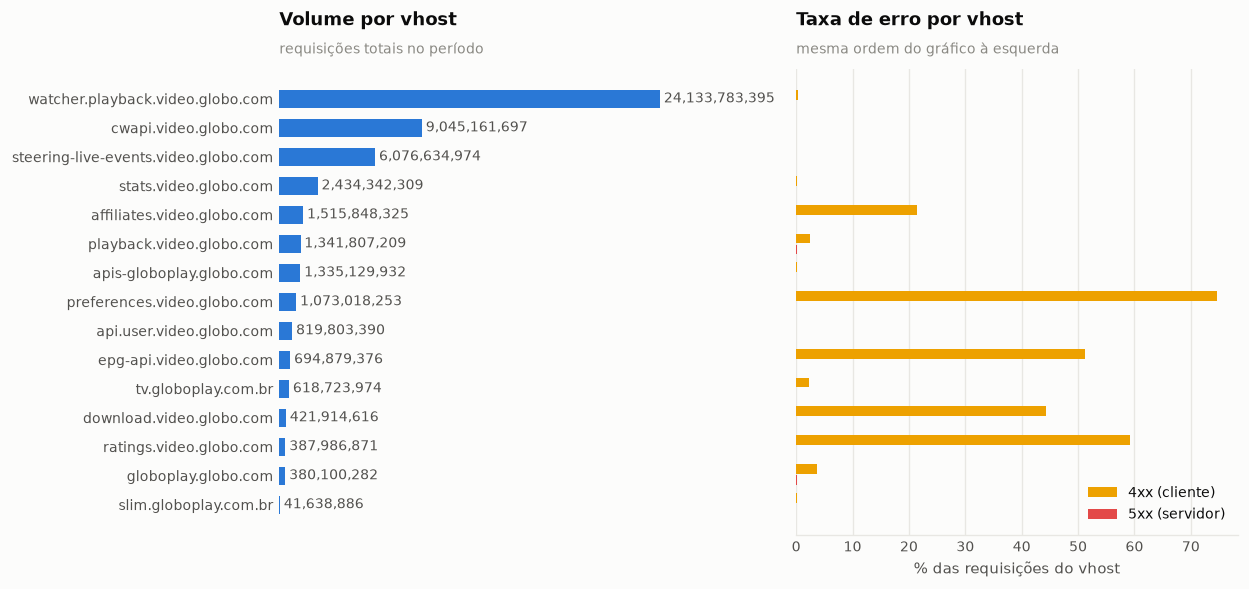

In [24]:
d = q("""
    SELECT vhost, sum(requests_total) req,
           100.0*sum(requests_4xx)/nullif(sum(requests_total),0) pct_4xx,
           100.0*sum(requests_5xx)/nullif(sum(requests_total),0) pct_5xx
    FROM rpaas_bucket GROUP BY 1 ORDER BY req DESC LIMIT 15
""")

f, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 5.0))
barras_h(a1, d.vhost, d.req.values, color=CAT[0], fmt="{:,.0f}")
titulo(a1, "Volume por vhost", "requisições totais no período")

# taxa de erro: 4xx e 5xx são categorias diferentes, não uma pilha de magnitude
y = np.arange(len(d))
a2.barh(y - 0.19, d.pct_4xx, height=0.34, color=CAT[3], label="4xx (cliente)")
a2.barh(y + 0.19, d.pct_5xx, height=0.34, color=CAT[7], label="5xx (servidor)")
a2.set_yticks(y, ["" for _ in y])
a2.invert_yaxis()
sem_grade(a2)
a2.grid(True, axis="x")
a2.set_axisbelow(True)
a2.spines["left"].set_visible(False)
a2.set_xlabel("% das requisições do vhost")
a2.legend(ncol=1, loc="lower right")
titulo(a2, "Taxa de erro por vhost", "mesma ordem do gráfico à esquerda")
plt.tight_layout()
plt.show()

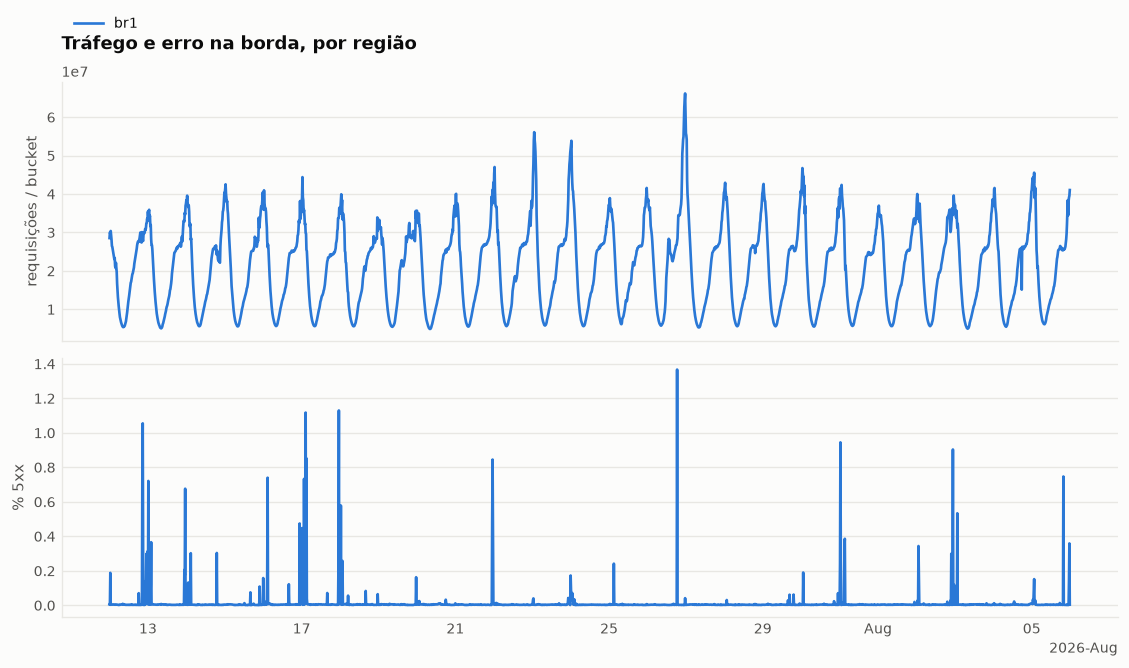

In [25]:
# Série temporal do tráfego e do erro na borda. Duas grandezas de escala
# diferente pedem dois painéis, nunca dois eixos y no mesmo painel.
d = q("""
    SELECT to_timestamp(bucket_ts_ms/1000) t, region,
           sum(requests_total) req,
           100.0*sum(requests_5xx)/nullif(sum(requests_total),0) pct_5xx
    FROM rpaas_bucket GROUP BY 1, 2 ORDER BY 1
""")

f, (a1, a2) = plt.subplots(2, 1, figsize=(9.5, 5.6), sharex=True)
for i, (reg, g) in enumerate(d.groupby("region")):
    a1.plot(g.t, g.req, color=CAT[i % len(CAT)], label=reg, lw=1.6)
    a2.plot(g.t, g.pct_5xx, color=CAT[i % len(CAT)], lw=1.6)
a1.legend(ncol=6, loc="upper left", bbox_to_anchor=(0, 1.30))
a1.set_ylabel("requisições / bucket")
a2.set_ylabel("% 5xx")
titulo(a1, "Tráfego e erro na borda, por região")
titulo(a2, "")
plt.tight_layout()
plt.show()

In [26]:
# Vhosts em que o 4xx deixa de ser exceção e vira o comportamento dominante.
q("""
    SELECT vhost, sum(requests_total) req,
           100.0*sum(requests_4xx)/nullif(sum(requests_total),0) pct_4xx,
           100.0*sum(requests_5xx)/nullif(sum(requests_total),0) pct_5xx
    FROM rpaas_bucket GROUP BY 1
    HAVING sum(requests_total) > 1e6 AND pct_4xx > 10
    ORDER BY pct_4xx DESC
""")

,vhost,req,pct_4xx,pct_5xx
0,preferences.video.globo.com,1.073e+09,74.6,0.0009215
1,ratings.video.globo.com,3.88e+08,59.26,0.00025
2,epg-api.video.globo.com,6.949e+08,51.27,0.02104
3,download.video.globo.com,4.219e+08,44.24,0.002958
4,affiliates.video.globo.com,1.516e+09,21.51,6.597e-07


Vários vhosts operam com **taxa de 4xx na casa das dezenas de por cento** —
`preferences`, `ratings`, `epg-api`, `download`, `affiliates`. Um 4xx é erro de
cliente, não de servidor, e por isso costuma ser filtrado dos alarmes; a
operação olha 5xx. Mas uma taxa dessa magnitude quase nunca significa "os
clientes estão errando": significa contrato de API mal ajustado, autenticação
expirando, ou o app pedindo recurso que não existe.

Para este projeto isso importa por dois motivos. Primeiro, é ruído de fundo
altíssimo — qualquer detector que use 4xx como sinal precisa de uma linha de
base **por vhost**, nunca de um limiar global. Segundo, parte desse volume pode
ser degradação real de experiência que hoje ninguém investiga porque não é 5xx.

## 3.3. Prometheus: `prom_query`, `prom_series`, `prom_point`

In [27]:
print(q("""
    SELECT (SELECT count(*) FROM prom_query)  AS queries,
           (SELECT count(*) FROM prom_series) AS series,
           (SELECT count(*) FROM prom_point)  AS pontos,
           (SELECT count(DISTINCT epoch_ms) FROM prom_point) AS instantes,
           (SELECT count(DISTINCT service_label) FROM prom_series) AS servicos,
           (SELECT count(DISTINCT panel_title) FROM prom_query) AS paineis
""").to_string(index=False))

q("""
    SELECT qy.section, count(DISTINCT qy.query_id) queries,
           count(DISTINCT s.series_id) series,
           sum(qy.enabled) queries_ativas
    FROM prom_query qy LEFT JOIN prom_series s USING (query_id)
    GROUP BY 1 ORDER BY series DESC NULLS LAST LIMIT 20
""")

 queries  series   pontos  instantes  servicos  paineis
     911   31629 41191820      14305       154      187


,section,queries,series,queries_ativas
0,RPAASV2 MEMORY,108,17468,1.753e+04
1,RPAASV2 CPU,81,9389,"9,393"
2,CDN LIVE HTTP_ERRORS,3,1815,"1,815"
3,ORIGIN LIVE HTTP_ERRORS,3,594,594
4,APPS UNITS_CURRENT,1,249,249
5,REDIS DBAAS,10,221,221
6,NODE NETWORK_RX_ERRS,1,218,218
7,NODE NETWORK_TX_ERRS,1,218,218
8,NODE NETWORK_RX_DROPS,1,218,218
9,NODE NETWORK_TX_DROPS,1,218,218


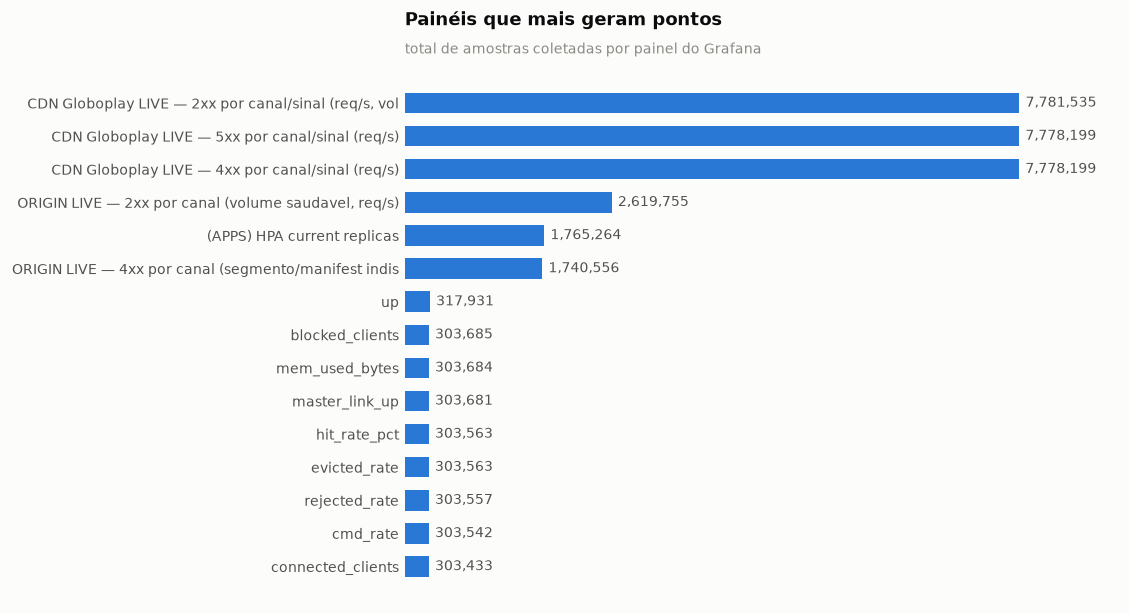

,series,minimo,mediana,p90,maximo
0,8377,1,344,1.419e+04,14298


In [28]:
# Quantas séries cada query gera é a medida direta da cardinalidade que o
# Prometheus impõe — e do custo que ela representaria numa suíte cobrada por série.
d = q("""
    SELECT qy.panel_title, qy.query_id, count(s.series_id) series,
           count(p.epoch_ms) pontos
    FROM prom_query qy
    LEFT JOIN prom_series s USING (query_id)
    LEFT JOIN prom_point p ON p.series_id = s.series_id
    GROUP BY 1, 2 ORDER BY pontos DESC LIMIT 15
""")
f, ax = fig(9.5, 5.2)
rot = [f"{(t or '(sem título)')[:52]}" for t in d.panel_title]
barras_h(ax, rot, d.pontos.values, color=CAT[0])
titulo(ax, "Painéis que mais geram pontos",
       "total de amostras coletadas por painel do Grafana")
plt.tight_layout()
plt.show()

q("""
    SELECT count(*) series,
           min(cnt) minimo, median(cnt) mediana,
           quantile_cont(cnt, 0.9) p90, max(cnt) maximo
    FROM (SELECT series_id, count(*) cnt FROM prom_point GROUP BY 1)
""")

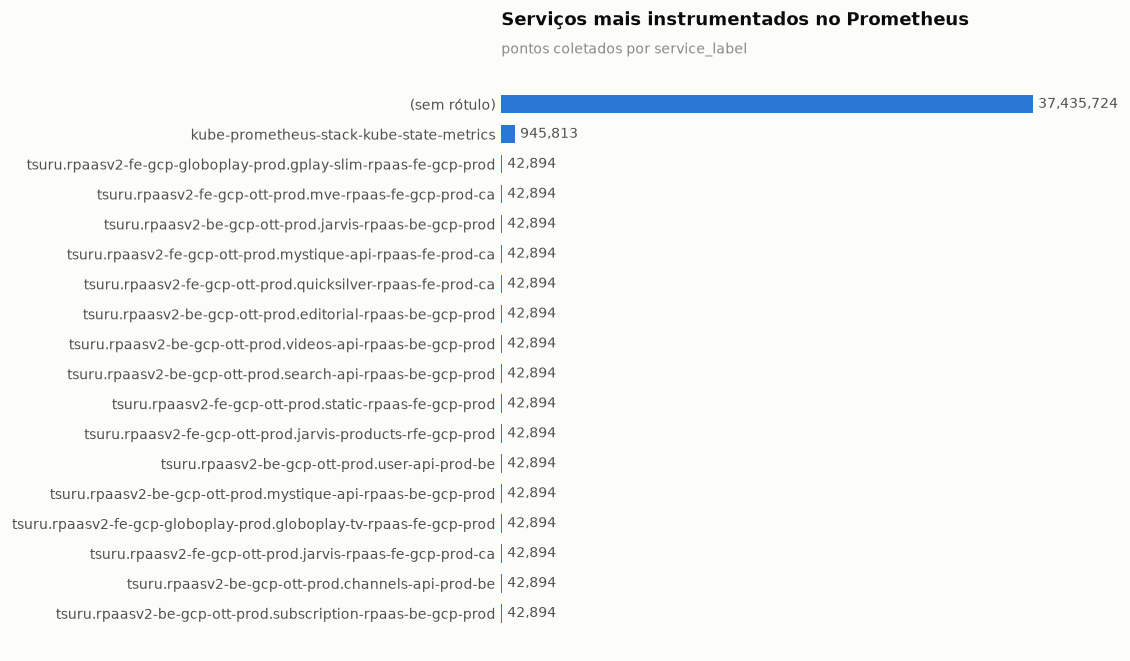

In [29]:
d = q("""
    SELECT coalesce(nullif(s.service_label, ''), '(sem rótulo)') servico,
           count(DISTINCT s.series_id) series, count(p.epoch_ms) pontos
    FROM prom_series s LEFT JOIN prom_point p USING (series_id)
    GROUP BY 1 ORDER BY pontos DESC LIMIT 18
""")
f, ax = fig(9.5, 5.6)
barras_h(ax, d.servico, d.pontos.values, color=CAT[0])
titulo(ax, "Serviços mais instrumentados no Prometheus",
       "pontos coletados por service_label")
plt.tight_layout()
plt.show()

## 3.4. APM de aplicação: `service_overview`

In [30]:
d = q("""
    SELECT app_name,
           count(*) amostras,
           avg(response_time_avg_ms) tempo_ms,
           avg(throughput_rpm) rpm,
           avg(error_rate_pct) erro_pct,
           max(error_rate_pct) erro_max_pct,
           avg(apdex_score) apdex,
           min(apdex_score) apdex_min
    FROM service_overview GROUP BY 1 ORDER BY rpm DESC
""")
print(f"{len(d)} aplicações monitoradas | "
      f"{q('SELECT count(*) n FROM service_overview').n.iloc[0]:,} amostras")
d

30 aplicações monitoradas | 385,129 amostras


,app_name,amostras,tempo_ms,rpm,erro_pct,erro_max_pct,apdex,apdex_min
0,Globoplay ADS API GCP Prod,14178,49.02,"5,588",0.009365,0.1159,0.9691,0.93
1,Globoplay Jarvis Gateway PROD GCP,14178,78.89,"5,464",0.004562,0.08764,0.9874,0.97
2,Globoplay Quicksilver GCP PROD,14178,663.8,"4,096",0.7171,32.02,0.7161,0.44
3,Globoplay Jarvis Service API GCP PROD,14178,87.25,"2,375",0,0,0.9824,0.96
4,Globoplay Videos API GCP Prod,14178,75.45,"1,837",0.1895,0.6257,0.9892,0.98
5,QRCode Generator API GCP Prod,14178,131.9,"1,727",0.0002157,0.01767,1,1
6,Globoplay User API GCP Prod,14178,49.28,"1,208",0.1152,1.452,0.9984,0.99
7,Globoplay Channels API GCP Prod,14178,68.38,"1,073",0.0985,0.2168,0.9928,0.99
8,Globoplay Recommendation API GCP Prod,14178,31.1,594.6,0.3608,7.644,1,0.99
9,Globoplay Editorial API GCP Prod,14178,50.67,580.4,0.1011,18.79,0.9999,0.99


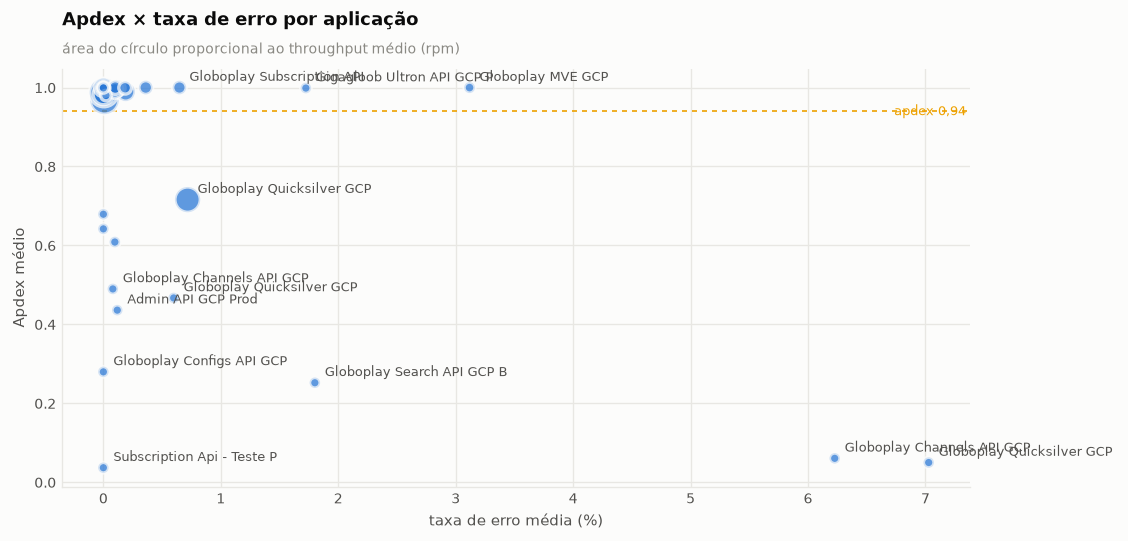

In [31]:
# Apdex resume a satisfação do usuário; taxa de erro resume a falha dura. Um
# scatter mostra que as duas não são redundantes.
f, ax = fig(9.5, 4.6)
sem_grade(ax)
ax.grid(True, axis="both")
ax.set_axisbelow(True)
tam = 40 + 260 * (d.rpm / d.rpm.max())
ax.scatter(d.erro_pct, d.apdex, s=tam, color=CAT[0], alpha=0.75,
           edgecolor=SURFACE, linewidth=2, zorder=3)
for r in d.itertuples():
    if r.erro_pct > d.erro_pct.quantile(0.75) or r.apdex < d.apdex.quantile(0.25):
        ax.annotate(r.app_name[:26], (r.erro_pct, r.apdex), fontsize=7.5,
                    color=INK2, xytext=(6, 4), textcoords="offset points")
ax.axhline(0.94, color=STATUS["warning"], lw=1, ls=(0, (3, 3)))
ax.text(ax.get_xlim()[1], 0.94, " apdex 0,94 ", fontsize=7.5,
        color=STATUS["warning"], va="center", ha="right")
ax.set_xlabel("taxa de erro média (%)")
ax.set_ylabel("Apdex médio")
titulo(ax, "Apdex × taxa de erro por aplicação",
       "área do círculo proporcional ao throughput médio (rpm)")
plt.tight_layout()
plt.show()

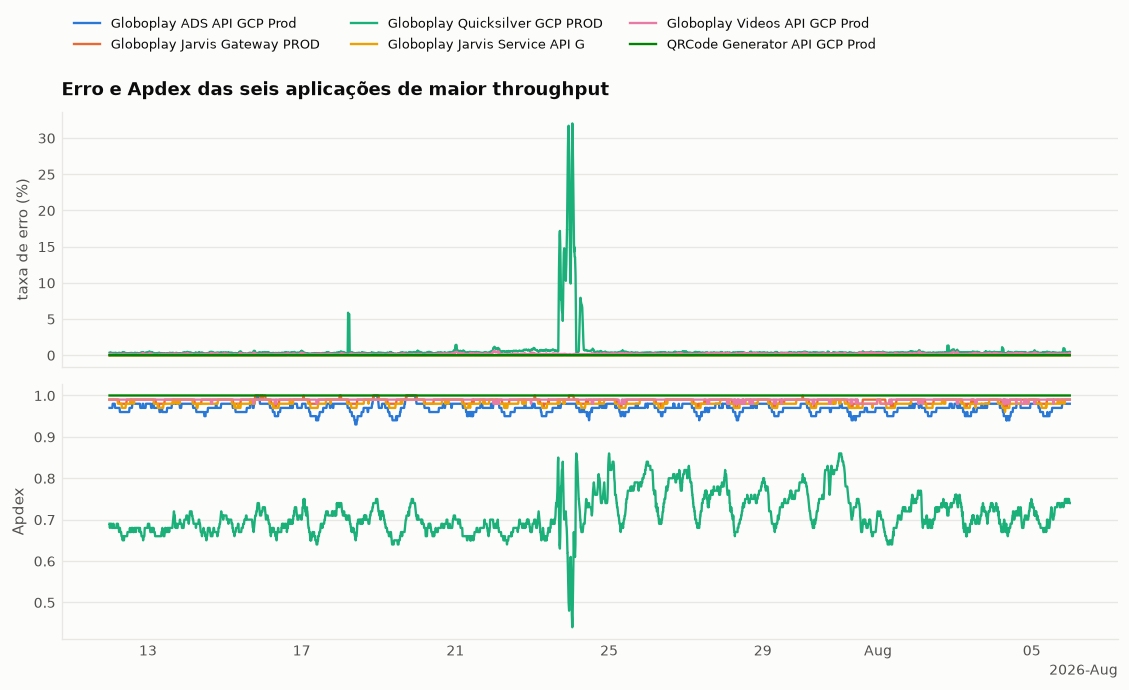

In [32]:
# Série temporal das aplicações de maior volume.
top = d.nlargest(6, "rpm").app_name.tolist()
lista = ", ".join(f"'{a}'" for a in top)
s = q(f"""
    SELECT to_timestamp(timestamp/1000) t, app_name, error_rate_pct, apdex_score
    FROM service_overview WHERE app_name IN ({lista}) ORDER BY 1
""")
f, (a1, a2) = plt.subplots(2, 1, figsize=(9.5, 5.8), sharex=True)
for i, app in enumerate(top):
    g = s[s.app_name == app]
    a1.plot(g.t, g.error_rate_pct, color=CAT[i], label=app[:30], lw=1.4)
    a2.plot(g.t, g.apdex_score, color=CAT[i], lw=1.4)
a1.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, 1.42), fontsize=8)
a1.set_ylabel("taxa de erro (%)")
a2.set_ylabel("Apdex")
titulo(a1, "Erro e Apdex das seis aplicações de maior throughput")
plt.tight_layout()
plt.show()

## 3.5. GraphQL: `operation_metrics` e `field_metrics`

In [33]:
print(q("""
    SELECT count(*) linhas, count(DISTINCT operation_name) operacoes,
           to_timestamp(min(start_ts)/1000) inicio,
           to_timestamp(max(start_ts)/1000) fim,
           sum(request_count) requisicoes, sum(error_count) erros,
           100.0*sum(error_count)/nullif(sum(request_count),0) pct_erro
    FROM operation_metrics
""").to_string(index=False))

d = q("""
    SELECT operation_name, sum(request_count) req, sum(error_count) err,
           100.0*sum(error_count)/nullif(sum(request_count),0) pct_erro,
           median(p50_ms) p50, median(p90_ms) p90, median(p99_ms) p99
    FROM operation_metrics GROUP BY 1 ORDER BY req DESC LIMIT 20
""")
d

 linhas  operacoes                    inicio                       fim  requisicoes     erros  pct_erro
 788556        633 2026-07-12 00:00:00+00:00 2026-08-05 23:52:00+00:00    3.071e+09 1.389e+07    0.4523


,operation_name,req,err,pct_erro,p50,p90,p99
0,LastWatchedVideos,2.393e+08,1.553e+06,0.6489,54.33,247.5,667.6
1,MySubscriptionsInfoAndTrialEligibility,1.409e+08,3.82e+06,2.711,46.42,93.65,286.5
2,Broadcast,1.358e+08,"8,605",0.006335,10.61,25.14,208.7
3,BroadcastEpgData,1.304e+08,"4,636",0.003556,3.973,7.609,87.34
4,OfferTitle,1.148e+08,5.847e+04,0.05094,25.43,109.7,323.6
5,Offer,1.111e+08,3.429e+04,0.03085,23.86,107.7,336.5
6,Broadcasts,7.031e+07,3.966e+04,0.05641,25.77,124.8,518.9
7,GetContinueWatchingOffer,6.209e+07,2.729e+06,4.396,78.2,267.5,661.9
8,PageRecommended,6.107e+07,"1,084",0.001775,56.07,134.7,372.1
9,getVideoView,5.177e+07,1.514e+05,0.2925,233.1,440.9,940.2


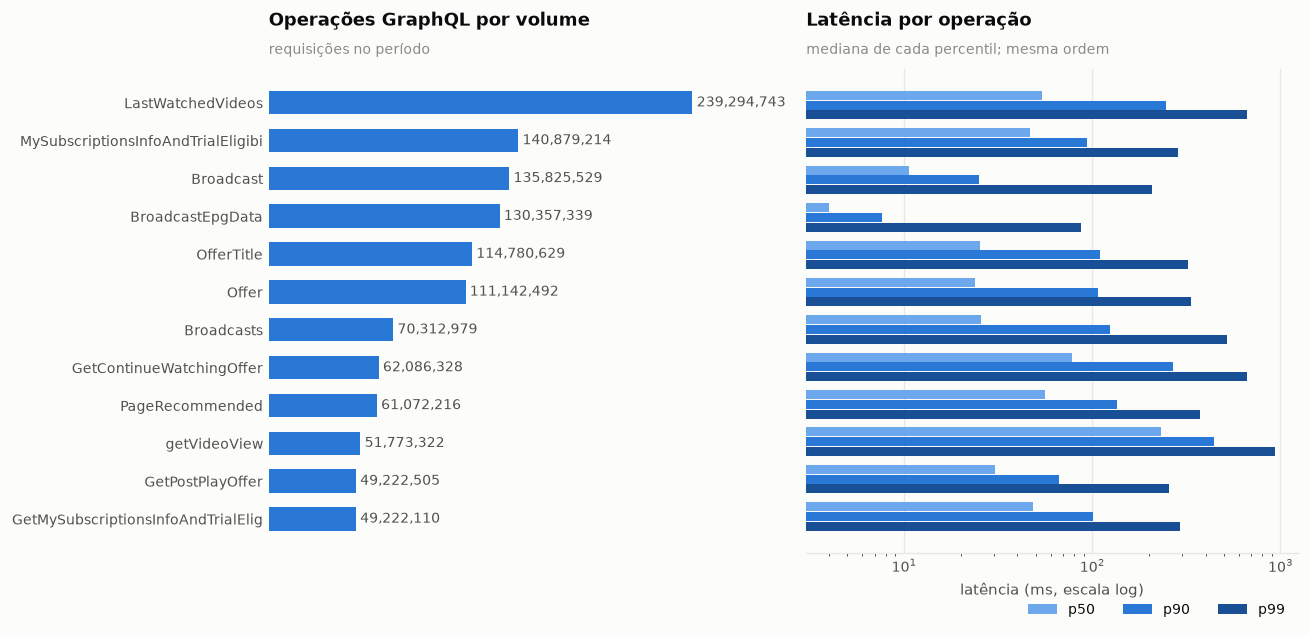

In [34]:
f, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 5.4))
top = d.head(12)
barras_h(a1, [o[:34] for o in top.operation_name], top.req.values, color=CAT[0])
titulo(a1, "Operações GraphQL por volume", "requisições no período")

# Percentis são um perfil ordenado da mesma grandeza: escala sequencial de um tom.
y = np.arange(len(top))
for j, (col, cor, lab) in enumerate([("p50", SEQ[2], "p50"), ("p90", SEQ[4], "p90"),
                                     ("p99", SEQ[6], "p99")]):
    a2.barh(y + (j - 1) * 0.26, top[col], height=0.24, color=cor, label=lab)
a2.set_yticks(y, ["" for _ in y])
a2.invert_yaxis()
sem_grade(a2)
a2.grid(True, axis="x")
a2.set_axisbelow(True)
a2.set_xscale("log")
a2.spines["left"].set_visible(False)
a2.set_xlabel("latência (ms, escala log)")
a2.legend(ncol=3, loc="lower right", bbox_to_anchor=(1, -0.16))
titulo(a2, "Latência por operação", "mediana de cada percentil; mesma ordem")
plt.tight_layout()
plt.show()

In [35]:
print(q("""
    SELECT count(*) linhas, count(DISTINCT coordinate) coordenadas,
           sum(request_count) req, sum(error_count) err,
           sum(observed_exec) execucoes
    FROM field_metrics
""").to_string(index=False))

q("""
    SELECT coordinate, sum(request_count) req, sum(error_count) err,
           100.0*sum(error_count)/nullif(sum(request_count),0) pct_erro,
           sum(observed_exec) execucoes
    FROM field_metrics GROUP BY 1 ORDER BY req DESC LIMIT 15
""")

 linhas  coordenadas       req  err  execucoes
  10080           14 1.148e+09    0  1.905e+07


,coordinate,req,err,pct_erro,execucoes
0,SalesProduct.name,3.126e+08,0,0,2.521e+06
1,SalesProduct.sku,2.215e+08,0,0,9.264e+05
2,SalesProduct.productId,1.836e+08,0,0,2.429e+06
3,SalesPaymentInfo.price,1.187e+08,0,0,2.521e+06
4,SalesProduct.priceSlug,8.44e+07,0,0,9.222e+05
5,SubscriptionService.payTVService,8.076e+07,0,0,3.311e+06
6,SalesProductCover.x16_9,3.002e+07,0,0,1.955e+06
7,SalesPaymentInfo.fullPrice,2.75e+07,0,0,8.464e+05
8,SalesProduct.benefits,2.736e+07,0,0,7.886e+05
9,SalesProduct.legalText,2.727e+07,0,0,7.805e+05


## 3.6. Proteção de borda: `ca_point`

In [36]:
print(q("""
    SELECT count(*) linhas, count(DISTINCT app) apps,
           count(DISTINCT backend_target) alvos,
           to_timestamp(min(ts_ms)/1000) inicio, to_timestamp(max(ts_ms)/1000) fim,
           sum(rps) FILTER (WHERE blocked = 1) rps_bloqueado,
           sum(rps) FILTER (WHERE blocked = 0) rps_permitido
    FROM ca_point
""").to_string(index=False))

d = q("""
    SELECT app,
           sum(rps) FILTER (WHERE blocked = 0) permitido,
           sum(rps) FILTER (WHERE blocked = 1) bloqueado,
           100.0 * sum(rps) FILTER (WHERE blocked = 1)
                 / nullif(sum(rps), 0) pct_bloqueado
    FROM ca_point GROUP BY 1 ORDER BY permitido DESC NULLS LAST LIMIT 15
""")
d

 linhas  apps  alvos                    inicio                       fim  rps_bloqueado  rps_permitido
1399048     5      5 2026-07-12 00:00:13+00:00 2026-08-05 23:59:28+00:00      1.657e+06      2.521e+08


,app,permitido,bloqueado,pct_bloqueado
0,jarvis-rpaas-fe-gcp-prod,1.411e+08,3.197e+05,0.226
1,mve-rpaas-fe-gcp-prod,8.583e+07,1.732e+04,0.02017
2,quicksilver-rpaas-fe-prod,2.504e+07,1.32e+06,5.006
3,affiliates-rpaas-fe-prod,2.142e+04,198.4,0.9175
4,gplay-slim-rpaas-fe-prod,2.136e+04,148.8,0.6921


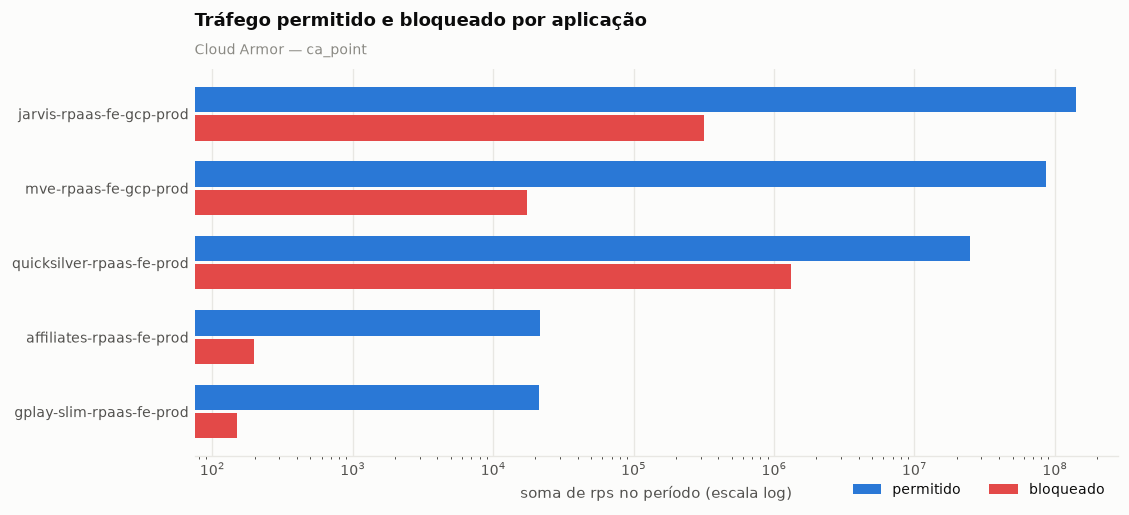

In [37]:
ativos = d.dropna(subset=["permitido"]).head(10)
f, ax = fig(9.5, 4.4)
y = np.arange(len(ativos))
ax.barh(y - 0.19, ativos.permitido, height=0.34, color=CAT[0], label="permitido")
ax.barh(y + 0.19, ativos.bloqueado.fillna(0), height=0.34, color=CAT[7],
        label="bloqueado")
ax.set_yticks(y, [a[:34] for a in ativos.app])
ax.invert_yaxis()
ax.set_xscale("log")
sem_grade(ax)
ax.grid(True, axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.set_xlabel("soma de rps no período (escala log)")
ax.legend(ncol=2, loc="lower right", bbox_to_anchor=(1, -0.14))
titulo(ax, "Tráfego permitido e bloqueado por aplicação",
       "Cloud Armor — ca_point")
plt.tight_layout()
plt.show()

## 3.7. Mudanças na plataforma: `tsuru_event`

Deploys e alterações de escala são a hipótese de causa mais frequente em
incidentes de plataforma. O campo `kind` diz o que aconteceu; `error`, se deu
errado.

In [38]:
print(q("""
    SELECT count(*) eventos, count(DISTINCT target_value) alvos,
           count(DISTINCT kind) tipos,
           to_timestamp(min(start_time_ms)/1000) inicio,
           to_timestamp(max(start_time_ms)/1000) fim,
           count(*) FILTER (WHERE error IS NOT NULL AND error <> '') com_erro,
           median(duration_ms)/1000 duracao_mediana_s
    FROM tsuru_event
""").to_string(index=False))

d = q("""
    SELECT kind, count(*) n,
           count(*) FILTER (WHERE error IS NOT NULL AND error <> '') erros,
           100.0*count(*) FILTER (WHERE error IS NOT NULL AND error <> '')
               / count(*) pct_erro,
           median(duration_ms)/1000 dur_mediana_s,
           quantile_cont(duration_ms, 0.95)/1000 dur_p95_s
    FROM tsuru_event GROUP BY 1 ORDER BY n DESC LIMIT 20
""")
d

 eventos  alvos  tipos                           inicio                              fim  com_erro  duracao_mediana_s
    1903     32     12 2026-07-07 03:03:40.714000+00:00 2026-08-05 19:56:18.979000+00:00         0              0.088


,kind,n,erros,pct_erro,dur_mediana_s,dur_p95_s
0,app.update.unit.autoscale.add,1633,0,0,0.085,0.116
1,app.deploy,93,0,0,112.7,278.8
2,app.run.shell,79,0,0,129.3,3.557e+04
3,app.update.unit.kill,27,0,0,0.131,0.1533
4,app.update.grant,22,0,0,0.014,0.016
5,app.update.env.set,19,0,0,40.17,128.4
6,app.update,19,0,0,0.099,13.23
7,app.update.env.unset,5,0,0,29.97,85.36
8,app.update.router.add,3,0,0,0.227,0.2315
9,app.admin.quota,1,0,0,0.019,0.019


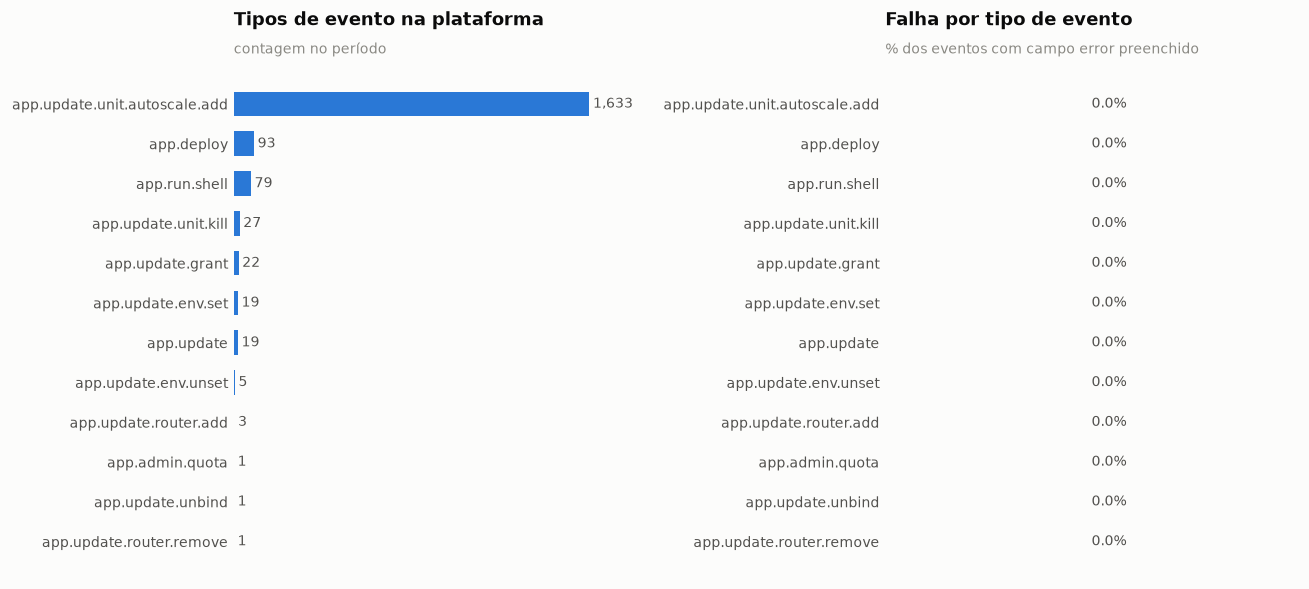

In [39]:
f, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 5.0))
top = d.head(12)
barras_h(a1, [k[:36] for k in top.kind], top.n.values, color=CAT[0])
titulo(a1, "Tipos de evento na plataforma", "contagem no período")
barras_h(a2, [k[:36] for k in top.kind], top.pct_erro.values,
         color=CAT[7], fmt="{:.1f}%")
titulo(a2, "Falha por tipo de evento", "% dos eventos com campo error preenchido")
plt.tight_layout()
plt.show()

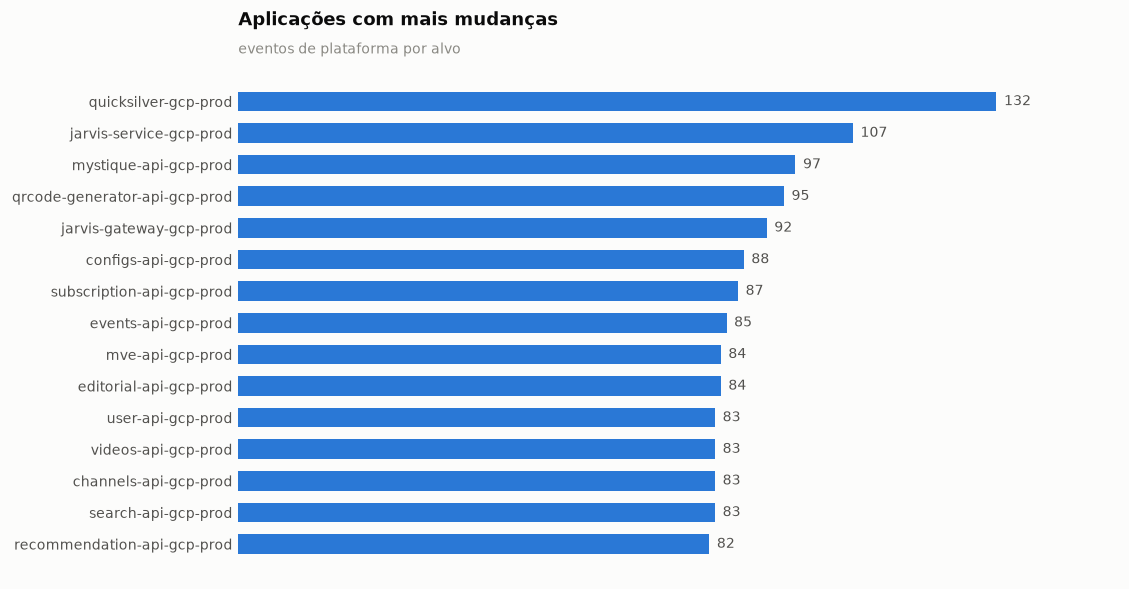

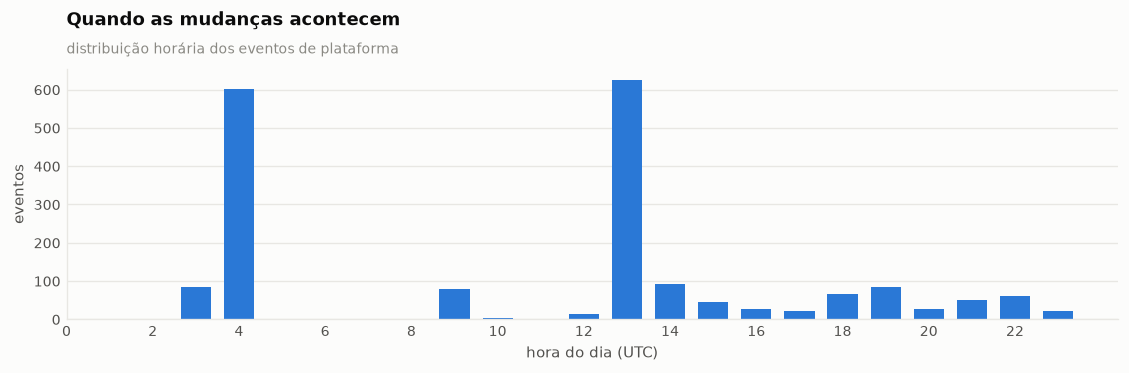

In [40]:
d = q("""
    SELECT target_value app, count(*) eventos,
           count(*) FILTER (WHERE kind LIKE '%deploy%') deploys,
           count(*) FILTER (WHERE error IS NOT NULL AND error <> '') com_erro
    FROM tsuru_event GROUP BY 1 ORDER BY eventos DESC LIMIT 15
""")
f, ax = fig(9.5, 5.0)
barras_h(ax, [a[:40] for a in d.app], d.eventos.values, color=CAT[0])
titulo(ax, "Aplicações com mais mudanças", "eventos de plataforma por alvo")
plt.tight_layout()
plt.show()

# distribuição temporal — mudanças se concentram em horário comercial?
h = q("""
    SELECT extract('hour' FROM to_timestamp(start_time_ms/1000)) hora, count(*) n
    FROM tsuru_event GROUP BY 1 ORDER BY 1
""")
f, ax = fig(9.5, 3.2)
ax.bar(h.hora, h.n, color=CAT[0], width=0.7)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hora do dia (UTC)")
ax.set_ylabel("eventos")
titulo(ax, "Quando as mudanças acontecem",
       "distribuição horária dos eventos de plataforma")
plt.tight_layout()
plt.show()

---
# 4. Qualidade de experiência (QoE)

Esta é a camada que enxerga o assinante. Enquanto a seção 3 mede se a
infraestrutura respondeu, aqui se mede se o vídeo **tocou** — e com que
qualidade. É a distinção que o caso de negócio chama de "degradação que não gera
erro": buffer alto e tempo de início ruim não acendem nenhum alarme de 5xx.

## 4.1. Sessões e erros por player

In [41]:
d = q("""
    SELECT nullif(player, '') player, sum(sessions) sessoes, sum(errors) erros,
           100.0 * sum(errors) / nullif(sum(sessions), 0) pct_erro
    FROM player_hourly GROUP BY 1 ORDER BY sessoes DESC
""")
print(f"{len(d)} players distintos | {d.sessoes.sum():,.0f} sessões | "
      f"taxa de erro global {100 * d.erros.sum() / d.sessoes.sum():.2f}%")
d.head(20)

61 players distintos | 2,019,611,925 sessões | taxa de erro global 1.47%


,player,sessoes,erros,pct_erro
0,clappr-web,2.695e+08,8.354e+06,3.1
1,clappr-web-tvs,2.642e+08,2.555e+06,0.9671
2,Media3,2.116e+08,2.794e+06,1.32
3,android,1.414e+08,5.854e+05,0.4141
4,androidtv,1.257e+08,4.515e+05,0.359
5,web-tizen_4k_hdr,1.096e+08,4.016e+05,0.3665
6,web-desktop,1.065e+08,4.196e+05,0.3941
7,ios,9.362e+07,6.807e+05,0.7271
8,web-android,9.353e+07,8.094e+04,0.08654
9,NaN,8.901e+07,1.051e+07,11.81


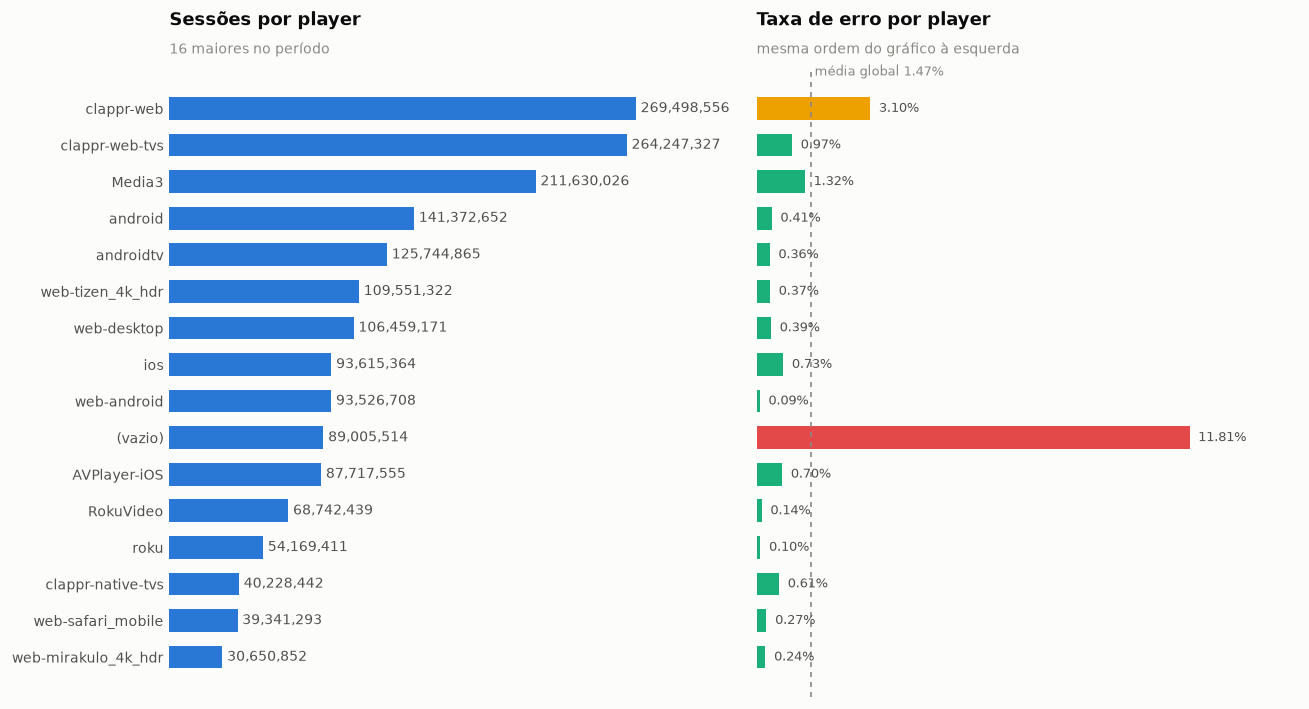

In [42]:
# Volume e taxa de erro respondem perguntas diferentes: o player que mais falha
# raramente é o que mais roda. Dois painéis, mesma ordem de linhas.
top = d.head(16).copy()
top["rotulo"] = top.player.fillna("(vazio)")
f, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 6.0))
barras_h(a1, top.rotulo, top.sessoes.values, color=CAT[0])
titulo(a1, "Sessões por player", "16 maiores no período")

media = 100 * d.erros.sum() / d.sessoes.sum()
cor = [STATUS["critical"] if v >= 3 * media else
       STATUS["warning"] if v >= media else CAT[2] for v in top.pct_erro]
y = np.arange(len(top))
a2.barh(y, top.pct_erro, color=cor, height=0.62)
a2.set_yticks(y, ["" for _ in y])
a2.invert_yaxis()
a2.axvline(media, color=INK3, lw=1, ls=(0, (3, 3)))
a2.text(media, -0.9, f" média global {media:.2f}%", fontsize=7.5, color=INK3)
sem_grade(a2)
a2.set_xticks([])
a2.spines["left"].set_visible(False)
a2.spines["bottom"].set_visible(False)
for yi, v in zip(y, top.pct_erro):
    a2.text(v + top.pct_erro.max() * 0.02, yi, f"{v:.2f}%", va="center",
            fontsize=8, color=INK2)
a2.set_xlim(0, top.pct_erro.max() * 1.25)
titulo(a2, "Taxa de erro por player", "mesma ordem do gráfico à esquerda")
plt.tight_layout()
plt.show()

Existe um player com identificador **vazio** concentrando um volume de sessões
comparável ao dos maiores players nomeados, e com taxa de erro uma ordem de
grandeza acima da média. Não é um player: é o balde onde caem as sessões cuja
origem não foi identificada. Como sua taxa de erro é atípica, ele não pode ser
descartado como ruído — enquanto essas sessões não forem atribuídas, uma fatia
relevante do erro do produto fica sem dono.

## 4.2. Concentração por dispositivo

4,758 modelos de dispositivo distintos


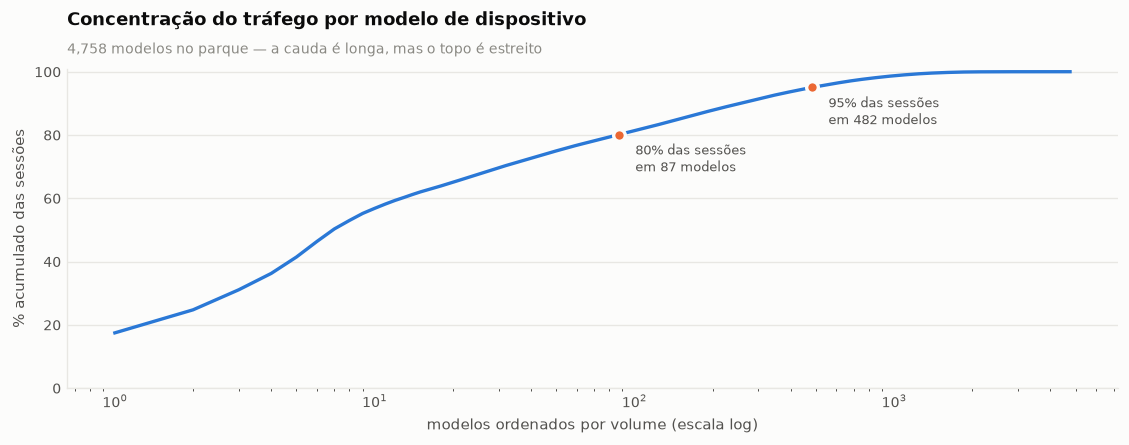

,device,sessoes,erros,pct_erro
0,Android,3.485e+08,1.162e+06,0.3335
1,Samsung - Tizen,1.454e+08,8.082e+05,0.556
2,iPhone,1.266e+08,6.624e+05,0.5232
3,?|Generic Android Mobile,1.032e+08,1.807e+06,1.751
4,Microsoft|?,1.032e+08,1.731e+06,1.677
5,PC( Windows ),9.855e+07,3.682e+05,0.3736
6,LG,7.884e+07,2.614e+05,0.3315
7,Apple|iPhone,5.35e+07,1.778e+06,3.323
8,Roku,4.445e+07,4.744e+04,0.1067
9,TCL|Smart TV,3.176e+07,1.988e+06,6.258


In [43]:
d = q("""
    SELECT device, sum(sessions) sessoes, sum(errors) erros,
           100.0*sum(errors)/nullif(sum(sessions),0) pct_erro
    FROM device_hourly GROUP BY 1 ORDER BY sessoes DESC
""")
print(f"{len(d):,} modelos de dispositivo distintos")

# Curva de Pareto: quanto do tráfego mora na cauda longa?
acum = d.sessoes.cumsum() / d.sessoes.sum() * 100
n80 = int((acum <= 80).sum()) + 1
n95 = int((acum <= 95).sum()) + 1
f, ax = fig(9.5, 3.8)
ax.plot(np.arange(1, len(d) + 1), acum, color=CAT[0], lw=2)
ax.set_xscale("log")
ax.set_ylim(0, 101)
for n, lab in [(n80, "80%"), (n95, "95%")]:
    ax.plot([n], [acum.iloc[n - 1]], "o", color=CAT[1], ms=7,
            markeredgecolor=SURFACE, markeredgewidth=2, zorder=3)
    ax.annotate(f"{lab} das sessões\nem {n:,} modelos", (n, acum.iloc[n - 1]),
                xytext=(10, -22), textcoords="offset points",
                fontsize=8, color=INK2)
ax.set_xlabel("modelos ordenados por volume (escala log)")
ax.set_ylabel("% acumulado das sessões")
titulo(ax, "Concentração do tráfego por modelo de dispositivo",
       f"{len(d):,} modelos no parque — a cauda é longa, mas o topo é estreito")
plt.tight_layout()
plt.show()

d.head(15)

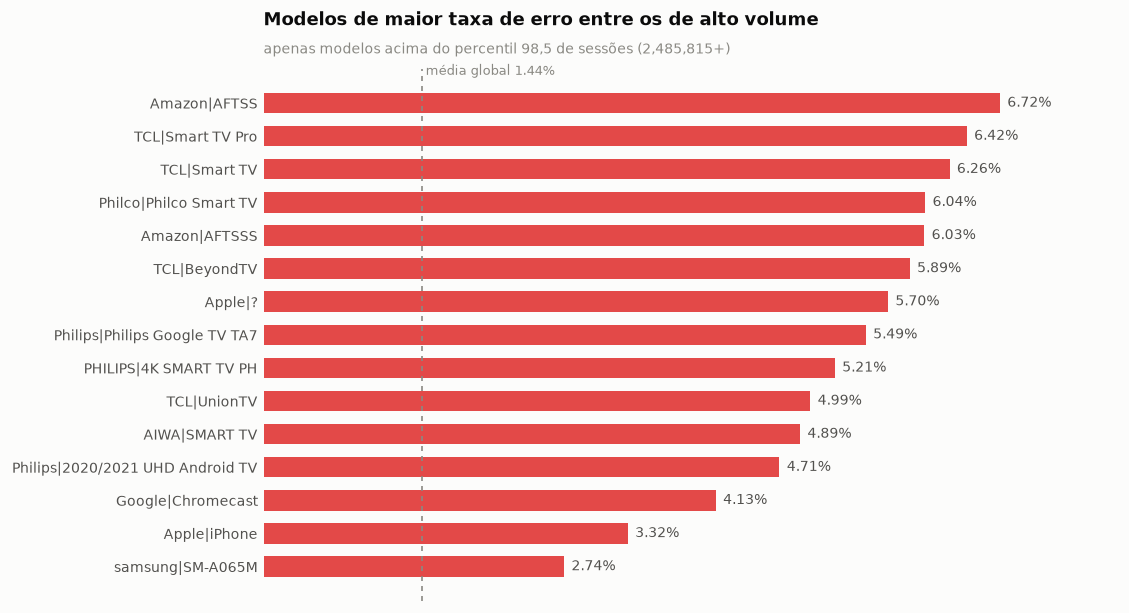

In [44]:
# Onde a falha se concentra: modelos com volume relevante e erro muito acima da
# média são exatamente o recorte que a média nacional esconde.
media = 100 * d.erros.sum() / d.sessoes.sum()
corte = d.sessoes.quantile(0.985)
risco = d[d.sessoes >= corte].nlargest(15, "pct_erro")
f, ax = fig(9.5, 5.2)
barras_h(ax, [x[:44] for x in risco.device], risco.pct_erro.values,
         color=STATUS["critical"], fmt="{:.2f}%")
ax.axvline(media, color=INK3, lw=1, ls=(0, (3, 3)))
ax.text(media, -0.85, f" média global {media:.2f}%", fontsize=7.5, color=INK3)
titulo(ax, "Modelos de maior taxa de erro entre os de alto volume",
       f"apenas modelos acima do percentil 98,5 de sessões ({corte:,.0f}+)")
plt.tight_layout()
plt.show()

## 4.3. Geografia e operadora

In [45]:
# A tabela promete o cruzamento UF × operadora. Vale verificar se ele existe.
cruz = q("""
    SELECT CASE WHEN state_province = '?' THEN 'UF ausente'
                ELSE 'UF preenchida' END AS uf,
           CASE WHEN isp = '?' THEN 'ISP ausente'
                ELSE 'ISP preenchido' END AS isp,
           count(*) linhas, sum(sessions) sessoes
    FROM geo_hourly GROUP BY 1, 2 ORDER BY linhas DESC
""")
cruz

,uf,isp,linhas,sessoes
0,UF ausente,ISP preenchido,140682,4.025e+08
1,UF preenchida,ISP ausente,9720,5.713e+08


> **Achado crítico.** As duas dimensões são **mutuamente exclusivas**: não existe
> uma única linha com UF e operadora preenchidas ao mesmo tempo. A tabela é, na
> prática, a união de dois recortes marginais — sessões por UF (com operadora
> anonimizada) e sessões por operadora (com UF anonimizada).
>
> Isso tem consequência direta para o projeto. O caso de negócio sustenta que o
> diferencial da solução está em enxergar "a combinação de plataforma, modelo,
> versão, UF e operadora" — e é justamente essa combinação que a sanitização
> removeu. Uma falha que atinja *uma operadora em um estado* é indetectável
> neste dataset. O protótipo pode demonstrar o recorte por UF **ou** por
> operadora, nunca o cruzamento; qualquer requisito que dependa dele precisa ser
> negociado com o parceiro ou movido para dados de produção.

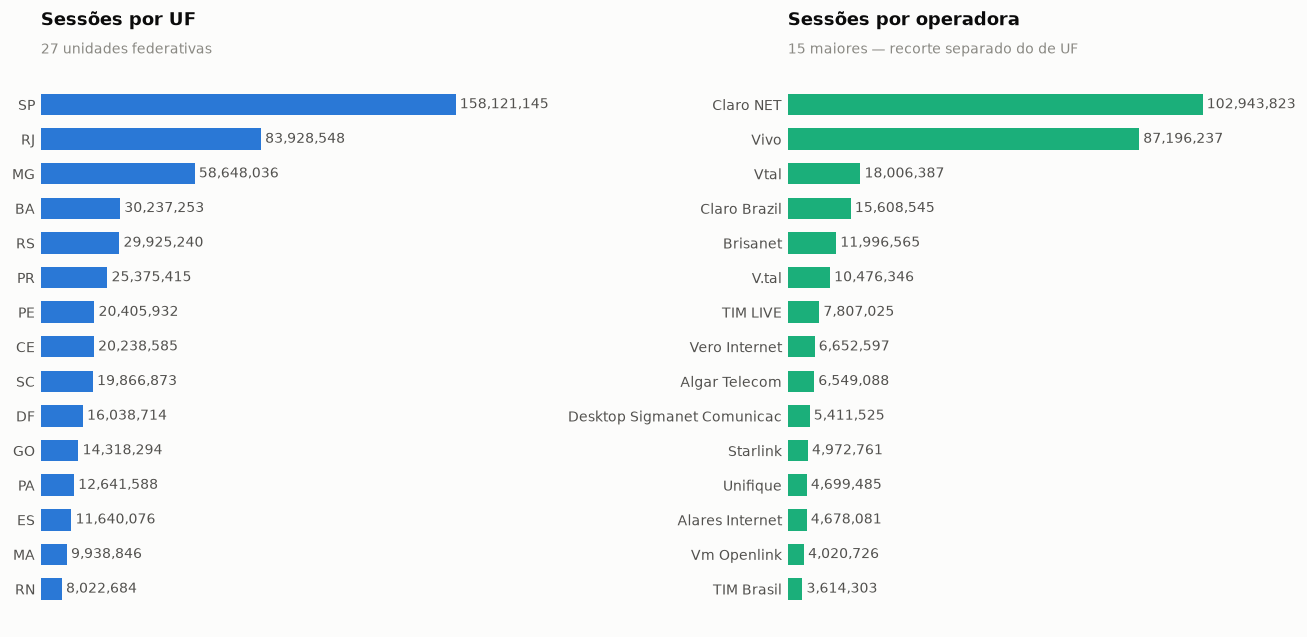

In [46]:
uf = q("""
    SELECT state_province uf, sum(sessions) sessoes, sum(errors) erros,
           100.0*sum(errors)/nullif(sum(sessions),0) pct_erro
    FROM geo_hourly WHERE state_province <> '?'
    GROUP BY 1 ORDER BY sessoes DESC
""")
isp = q("""
    SELECT isp, sum(sessions) sessoes, sum(errors) erros,
           100.0*sum(errors)/nullif(sum(sessions),0) pct_erro
    FROM geo_hourly WHERE isp <> '?'
    GROUP BY 1 ORDER BY sessoes DESC LIMIT 15
""")

f, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 5.4))
barras_h(a1, uf.head(15).uf, uf.head(15).sessoes.values, color=CAT[0])
titulo(a1, "Sessões por UF", f"{len(uf)} unidades federativas")
barras_h(a2, [i[:26] for i in isp.isp], isp.sessoes.values, color=CAT[2])
titulo(a2, "Sessões por operadora", "15 maiores — recorte separado do de UF")
plt.tight_layout()
plt.show()

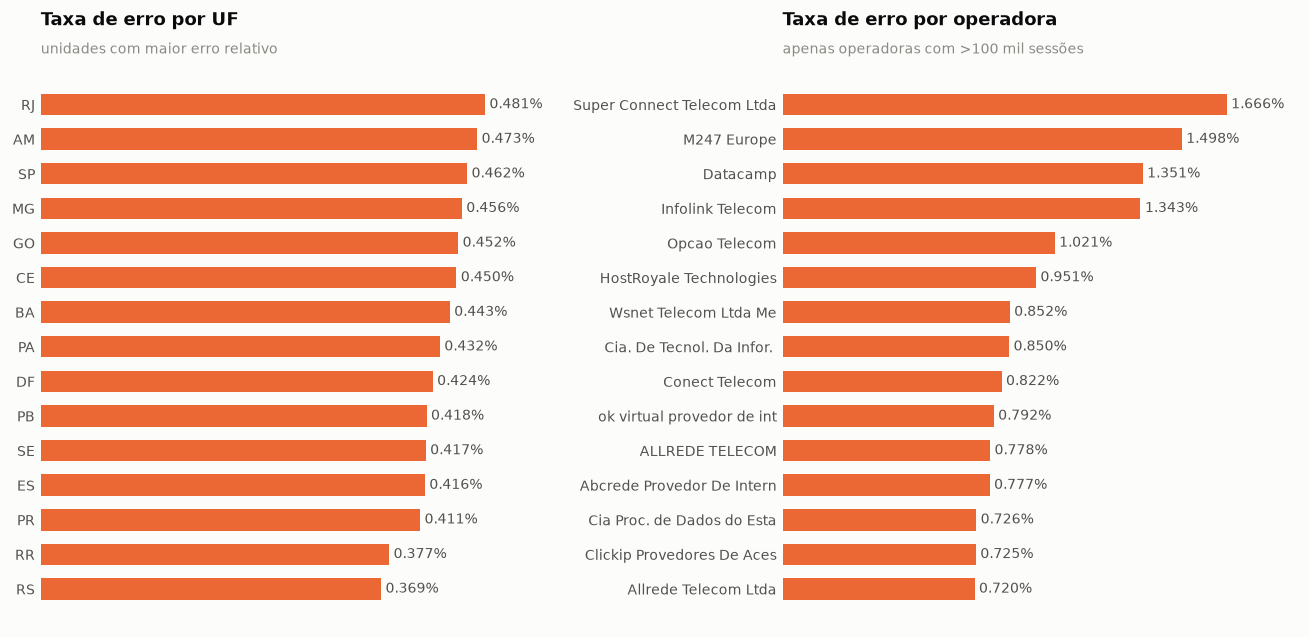

In [47]:
# Erro por UF e por operadora, ordenados pela taxa e não pelo volume.
f, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 5.4))
a = uf.nlargest(15, "pct_erro")
barras_h(a1, a.uf, a.pct_erro.values, color=STATUS["serious"], fmt="{:.3f}%")
titulo(a1, "Taxa de erro por UF", "unidades com maior erro relativo")
b = q("""
    SELECT isp, sum(sessions) sessoes,
           100.0*sum(errors)/nullif(sum(sessions),0) pct_erro
    FROM geo_hourly WHERE isp <> '?' GROUP BY 1
    HAVING sum(sessions) > 100000 ORDER BY pct_erro DESC LIMIT 15
""")
barras_h(a2, [i[:26] for i in b.isp], b.pct_erro.values,
         color=STATUS["serious"], fmt="{:.3f}%")
titulo(a2, "Taxa de erro por operadora", "apenas operadoras com >100 mil sessões")
plt.tight_layout()
plt.show()

## 4.4. QoE do ao vivo por sinal

In [48]:
d = q("""
    SELECT sinal, sum(sessions) sessoes, sum(errors) erros,
           100.0*sum(errors)/nullif(sum(sessions),0) pct_erro,
           100.0*sum(startup_errors)/nullif(sum(errors),0) pct_startup,
           avg(bufferratio_avg) buffer_pct, avg(jointime_s_avg) jointime_s,
           avg(latency_ms_avg) latencia_ms, avg(stalls_avg) travamentos,
           avg(bitrate_mbps_avg) bitrate_mbps, avg(dropped_frames_avg) frames_perdidos
    FROM live_qoe_hourly GROUP BY 1 ORDER BY sessoes DESC
""")
print(f"{len(d)} sinais ao vivo | {d.sessoes.sum():,.0f} sessões")
d.head(20)

283 sinais ao vivo | 176,452,423 sessões


,sinal,sessoes,erros,pct_erro,pct_startup,buffer_pct,jointime_s,latencia_ms,travamentos,bitrate_mbps,frames_perdidos
0,globo-sp1,1.67e+07,1.843e+05,1.104,52.43,0.62,5.62,1.239e+04,0.00486,5.546,22.4
1,globo-rj,1.567e+07,1.893e+05,1.208,49.06,0.8648,6.145,1.154e+04,0.005729,5.518,26.27
2,?,5.62e+06,2.963e+05,5.273,99.61,0.08242,0.6429,0,0.0003266,4.447,0
3,pfc1,5.488e+06,2.993e+05,5.454,18.34,0.8855,4.77,"3,714",0.01465,4.814,45.63
4,spo124ha,5.192e+06,1.648e+05,3.175,18.22,1.324,5.076,"6,504",0.009535,5.143,28.83
5,gehd,4.844e+06,1.476e+04,0.3047,90.35,0.8879,2.989,7.736,0.00732,2.069,0.004391
6,globo-rs1,4.627e+06,3.379e+04,0.7304,61.66,0.5912,5.861,1.15e+04,0.004556,3.451,33.86
7,globo-bh,4.621e+06,5.465e+04,1.183,47.66,0.6317,5.819,1.224e+04,0.004864,5.539,24.29
8,spo224ha,4.134e+06,1.798e+04,0.4349,64.47,0.8383,4.561,"9,660",0.0074,3.403,7.255
9,globo-sal,3.845e+06,5.106e+04,1.328,66.49,0.7436,6.151,1.457e+04,0.004927,3.349,32.5


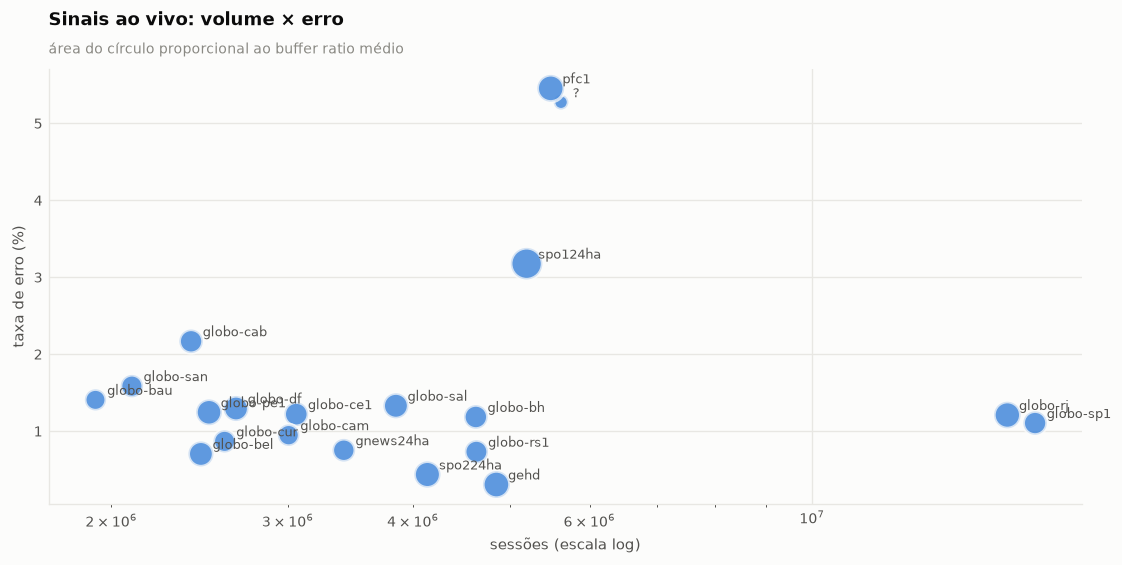

In [49]:
# Volume x erro para os sinais principais; sinais de alto volume e alto erro são
# o alvo prioritário.
top = d.head(20)
f, ax = fig(9.5, 4.8)
sem_grade(ax)
ax.grid(True)
ax.set_axisbelow(True)
ax.scatter(top.sessoes, top.pct_erro, s=60 + 300 * top.buffer_pct / top.buffer_pct.max(),
           color=CAT[0], alpha=0.75, edgecolor=SURFACE, linewidth=2, zorder=3)
for r in top.itertuples():
    ax.annotate(r.sinal, (r.sessoes, r.pct_erro), fontsize=7.5, color=INK2,
                xytext=(7, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("sessões (escala log)")
ax.set_ylabel("taxa de erro (%)")
titulo(ax, "Sinais ao vivo: volume × erro",
       "área do círculo proporcional ao buffer ratio médio")
plt.tight_layout()
plt.show()

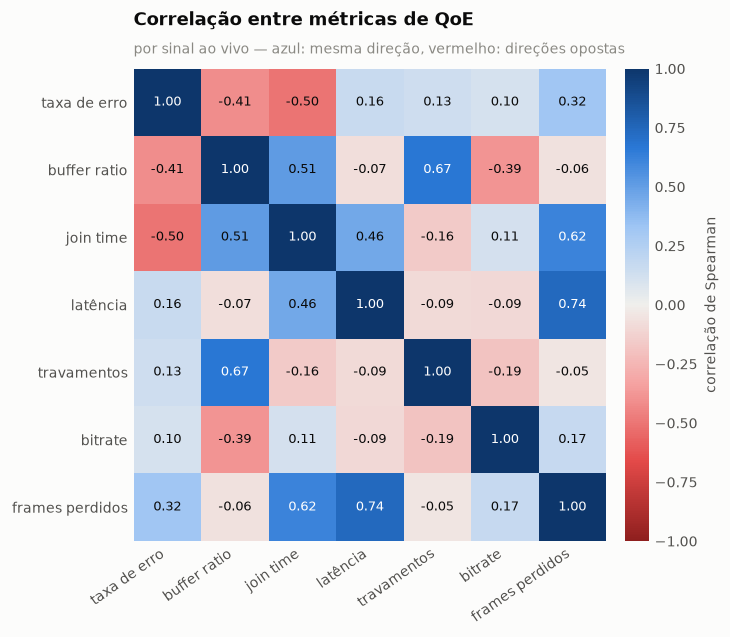

In [50]:
# As métricas de QoE medem coisas diferentes ou são redundantes? A matriz de
# correlação responde — e escala divergente é a forma certa para polaridade.
cols = ["pct_erro", "buffer_pct", "jointime_s", "latencia_ms", "travamentos",
        "bitrate_mbps", "frames_perdidos"]
rot = ["taxa de erro", "buffer ratio", "join time", "latência",
       "travamentos", "bitrate", "frames perdidos"]
corr = d[cols].corr(method="spearman")

f, ax = fig(6.6, 5.4)
im = ax.imshow(corr.values, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(rot)), rot, rotation=35, ha="right")
ax.set_yticks(range(len(rot)), rot)
sem_grade(ax)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(rot)):
    for j in range(len(rot)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if abs(v) > 0.55 else INK)
cb = f.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
cb.outline.set_visible(False)
cb.set_label("correlação de Spearman", color=INK2, fontsize=8.5)
titulo(ax, "Correlação entre métricas de QoE",
       "por sinal ao vivo — azul: mesma direção, vermelho: direções opostas")
plt.tight_layout()
plt.show()

## 4.5. Sessões ativas em janela de 15 minutos

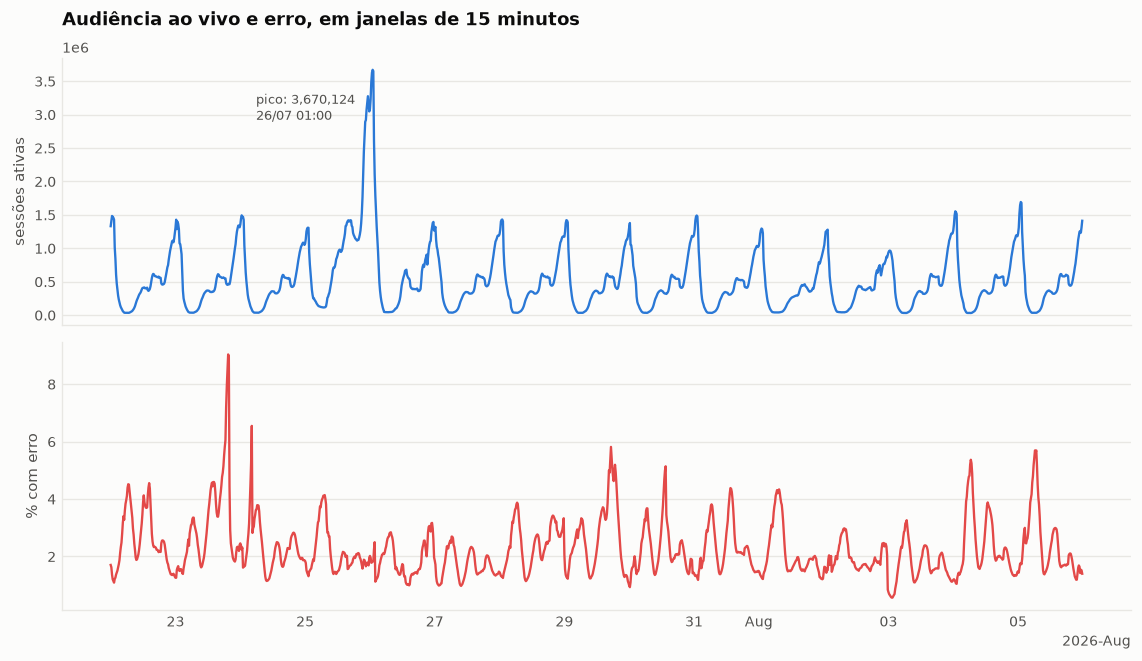

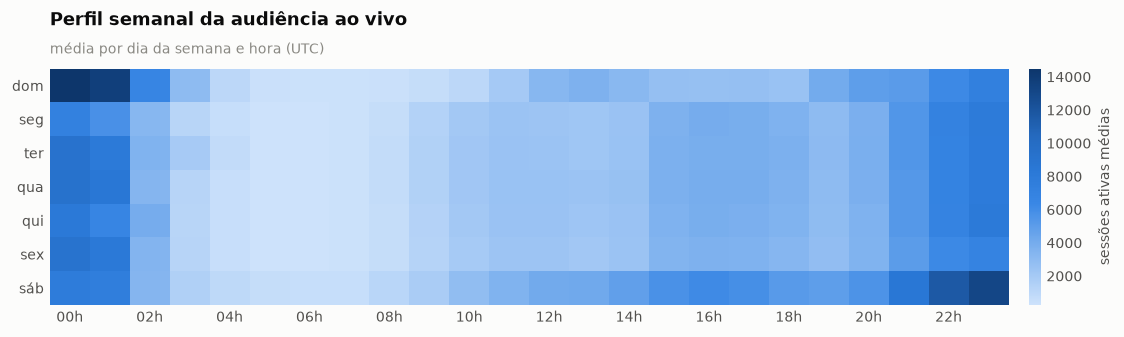

In [51]:
s = q("""
    SELECT to_timestamp(bucket_ts/1000) t, sum(active_sessions) ativas,
           sum(active_with_error) com_erro, sum(joins_in_bucket) entradas
    FROM live_active_15min GROUP BY 1 ORDER BY 1
""")
f, (a1, a2) = plt.subplots(2, 1, figsize=(9.5, 5.6), sharex=True)
a1.plot(s.t, s.ativas, color=CAT[0], lw=1.4)
a1.set_ylabel("sessões ativas")
a2.plot(s.t, 100 * s.com_erro / s.ativas.replace(0, np.nan), color=CAT[7], lw=1.4)
a2.set_ylabel("% com erro")
titulo(a1, "Audiência ao vivo e erro, em janelas de 15 minutos")
pico = s.loc[s.ativas.idxmax()]
a1.annotate(f"pico: {pico.ativas:,.0f}\n{pico.t:%d/%m %H:%M}",
            (pico.t, pico.ativas), xytext=(-70, -30),
            textcoords="offset points", fontsize=8, color=INK2)
plt.tight_layout()
plt.show()

# Perfil semanal: a operação precisa saber quando o risco é maior.
h = q("""
    SELECT extract('dow' FROM to_timestamp(bucket_ts/1000)) dow,
           extract('hour' FROM to_timestamp(bucket_ts/1000)) hora,
           avg(active_sessions) ativas
    FROM live_active_15min GROUP BY 1, 2
""").pivot(index="dow", columns="hora", values="ativas")
dias = ["dom", "seg", "ter", "qua", "qui", "sex", "sáb"]
f, ax = fig(9.5, 2.9)
im = ax.imshow(h.values, cmap=SEQ_CMAP, aspect="auto")
ax.set_yticks(range(len(h)), [dias[int(i)] for i in h.index])
ax.set_xticks(range(0, 24, 2), [f"{i:02d}h" for i in range(0, 24, 2)])
sem_grade(ax)
for sp in ax.spines.values():
    sp.set_visible(False)
cb = f.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.outline.set_visible(False)
cb.set_label("sessões ativas médias", color=INK2, fontsize=8.5)
titulo(ax, "Perfil semanal da audiência ao vivo", "média por dia da semana e hora (UTC)")
plt.tight_layout()
plt.show()

## 4.6. Atribuição dos erros: CDN, camada e código HTTP

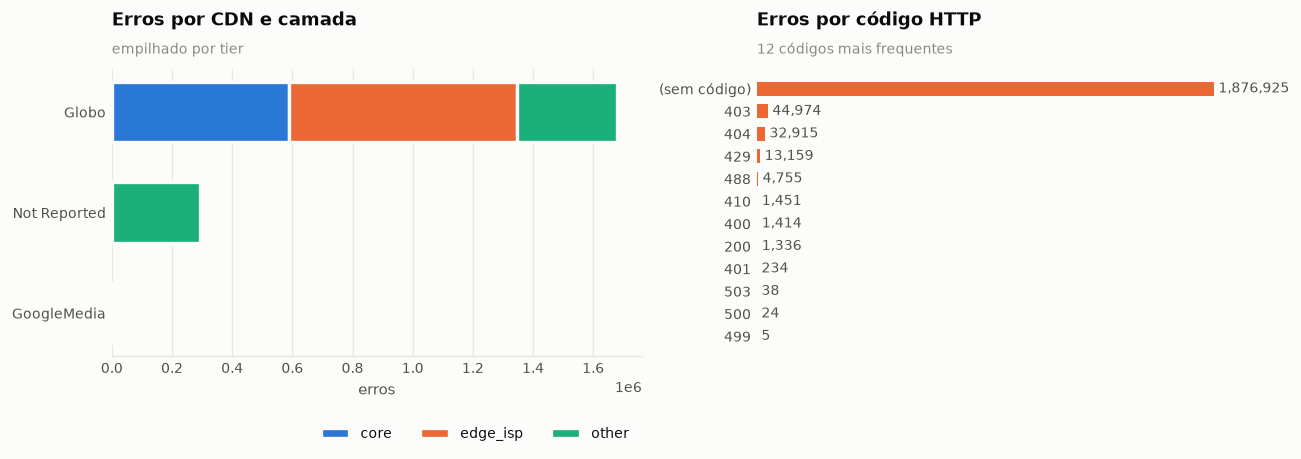

,error_name,erros,sinais,cdns,pct_sem_http
0,hls:networkError_manifestLoadError,3.029e+05,201,3,100
1,hls:networkError_manifestParsingError,2.2e+05,33,2,100
2,resource-load-error,1.389e+05,141,3,100
3,321,1.09e+05,134,2,100
4,geo-fencing,8.079e+04,43,3,100
5,drm-not-supported,7.971e+04,2,2,100
6,user-not-authorized,6.539e+04,24,3,100
7,globoplay-sdk-playback:fetch-error,5.981e+04,129,3,97.74
8,hls:networkError_levelLoadError,5.71e+04,82,3,100
9,url-error-resource-unavailable,5.694e+04,95,2,100


In [52]:
d = q("""
    SELECT cdn, tier, sum(errors) erros FROM live_error_attr_hourly
    GROUP BY 1, 2 ORDER BY erros DESC
""")
m = d.pivot(index="cdn", columns="tier", values="erros").fillna(0)
m = m.loc[m.sum(axis=1).sort_values(ascending=False).index]

f, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 4.2))
esq = np.zeros(len(m))
for i, col in enumerate(m.columns):
    a1.barh(np.arange(len(m)), m[col], left=esq, height=0.6,
            color=CAT[i % len(CAT)], label=col, edgecolor=SURFACE, linewidth=2)
    esq += m[col].values
a1.set_yticks(range(len(m)), m.index)
a1.invert_yaxis()
sem_grade(a1)
a1.grid(True, axis="x")
a1.set_axisbelow(True)
a1.spines["left"].set_visible(False)
a1.set_xlabel("erros")
a1.legend(ncol=3, loc="lower right", bbox_to_anchor=(1, -0.34))
titulo(a1, "Erros por CDN e camada", "empilhado por tier")

cod = q("""
    SELECT CASE WHEN http_code = '' THEN '(sem código)' ELSE http_code END AS codigo,
           sum(errors) erros
    FROM live_error_attr_hourly GROUP BY 1 ORDER BY erros DESC LIMIT 12
""")
barras_h(a2, cod.codigo, cod.erros.values, color=CAT[1])
titulo(a2, "Erros por código HTTP", "12 códigos mais frequentes")
plt.tight_layout()
plt.show()

q("""
    SELECT error_name, sum(errors) erros, count(DISTINCT sinal) sinais,
           count(DISTINCT cdn) cdns,
           100.0*sum(errors) FILTER (WHERE http_code = '')
               / nullif(sum(errors), 0) pct_sem_http
    FROM live_error_attr_hourly GROUP BY 1 ORDER BY erros DESC LIMIT 15
""")

> **A grande maioria dos erros ao vivo não é um erro HTTP.** A categoria sem
> código concentra cerca de 95% do volume, e o que há dentro dela são falhas de
> player e de direito de acesso: `hls:networkError_manifestLoadError`,
> `resource-load-error`, `drm-not-supported`, `geo-fencing`,
> `user-not-authorized`.
>
> Esse é provavelmente o dado mais alinhado à tese do projeto em todo o dump.
> Um sistema que investigue incidentes olhando códigos de status na borda
> enxergaria 5% do problema. As falhas que realmente impedem o assinante de
> assistir acontecem **no cliente** — no parsing do manifesto, na negociação de
> DRM, na verificação de direito regional — e só aparecem em telemetria coletada
> no player. Justifica diretamente o requisito de uma API de ingestão que aceite
> eventos vindos da borda do parque de dispositivos.

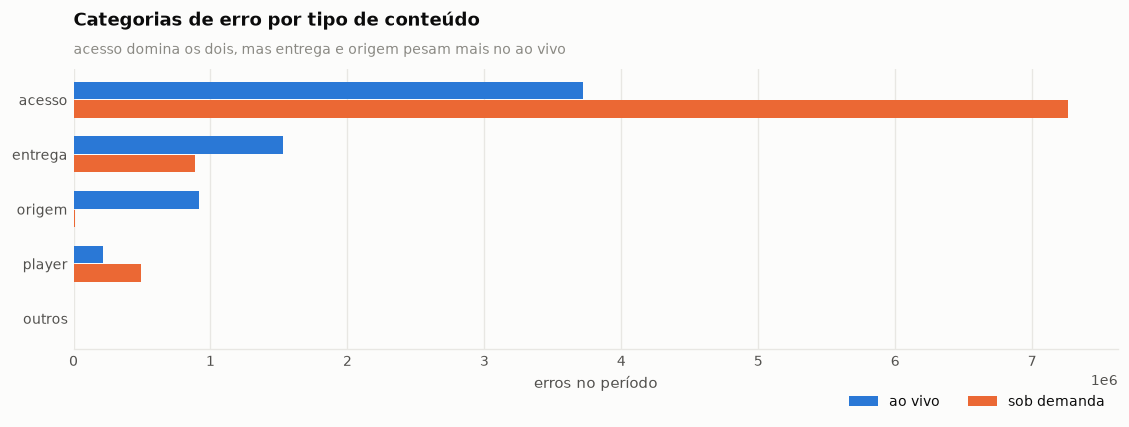

kind,live,vod
category,,
acesso,3.718e+06,7.262e+06
entrega,1.531e+06,8.875e+05
origem,9.189e+05,"8,007"
player,2.136e+05,4.904e+05
outros,"5,596","5,912"


In [53]:
# Categorias de erro separadas por tipo de conteúdo: ao vivo e sob demanda
# falham de formas diferentes, e isso muda a rota de investigação.
d = q("""
    SELECT kind, category, sum(errors) erros FROM error_cat_hourly
    GROUP BY 1, 2 ORDER BY erros DESC
""")
m = d.pivot(index="category", columns="kind", values="erros").fillna(0)
m = m.loc[m.sum(axis=1).sort_values(ascending=False).index]

f, ax = fig(9.5, 3.8)
y = np.arange(len(m))
for i, col in enumerate(m.columns):
    ax.barh(y + (i - 0.5) * 0.34, m[col], height=0.32, color=CAT[i],
            label={"live": "ao vivo", "vod": "sob demanda"}.get(col, col))
ax.set_yticks(y, m.index)
ax.invert_yaxis()
sem_grade(ax)
ax.grid(True, axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.set_xlabel("erros no período")
ax.legend(ncol=2, loc="lower right", bbox_to_anchor=(1, -0.26))
titulo(ax, "Categorias de erro por tipo de conteúdo",
       "acesso domina os dois, mas entrega e origem pesam mais no ao vivo")
plt.tight_layout()
plt.show()
m

## 4.7. Eventos ao vivo programados

In [54]:
q("""
    SELECT competition competicao, sport esporte, count(*) transmissoes,
           count(DISTINCT event_key) eventos,
           count(DISTINCT channel) canais,
           min(event_date) primeiro, max(event_date) ultimo,
           median((end_ts - start_ts)/60000.0) duracao_mediana_min
    FROM live_event GROUP BY 1, 2 ORDER BY transmissoes DESC
""")

,competicao,esporte,transmissoes,eventos,canais,primeiro,ultimo,duracao_mediana_min
0,Copa do Mundo da FIFA 2026™,Futebol,10,5,1,2026-07-09,2026-07-19,155
1,Brasileirão,Futebol,8,8,1,2026-07-22,2026-08-09,137.5
2,Copa do Brasil,Futebol,6,4,2,2026-08-01,2026-08-05,145


In [55]:
q("""
    SELECT event_date dia, event_key evento, team_home mandante,
           team_away visitante, competition competicao,
           to_timestamp(min(start_ts)/1000) inicio,
           round((max(end_ts) - min(start_ts))/60000.0, 1) duracao_min
    FROM live_event GROUP BY 1, 2, 3, 4, 5 ORDER BY inicio
""")

,dia,evento,mandante,visitante,competicao,inicio,duracao_min
0,2026-07-09,2026-07-09:franca|marrocos,França,Marrocos,Copa do Mundo da FIFA 2026™,2026-07-09 19:35:00+00:00,155
1,2026-07-10,2026-07-10:belgica|espanha,Espanha,Bélgica,Copa do Mundo da FIFA 2026™,2026-07-10 18:35:00+00:00,155
2,2026-07-15,2026-07-15:argentina|inglaterra,Inglaterra,Argentina,Copa do Mundo da FIFA 2026™,2026-07-15 18:30:00+00:00,160
3,2026-07-18,2026-07-18:franca|inglaterra,França,Inglaterra,Copa do Mundo da FIFA 2026™,2026-07-18 20:45:00+00:00,145
4,2026-07-19,2026-07-19:argentina|espanha,Espanha,Argentina,Copa do Mundo da FIFA 2026™,2026-07-19 19:00:00+00:00,185
5,2026-07-22,2026-07-22:chapecoense|flamengo,Chapecoense,Flamengo,Brasileirão,2026-07-23 00:20:00+00:00,130
6,2026-07-22,2026-07-22:athletico-pr|sao-paulo,São Paulo,Athlético PR,Brasileirão,2026-07-23 00:20:00+00:00,130
7,2026-07-26,2026-07-26:bahia|corinthians,Bahia,Corinthians,Brasileirão,2026-07-26 18:45:00+00:00,145
8,2026-07-26,2026-07-26:botafogo|cruzeiro,Cruzeiro,Botafogo,Brasileirão,2026-07-26 18:45:00+00:00,145
9,2026-07-29,2026-07-29:bahia|fluminense,Fluminense,Bahia,Brasileirão,2026-07-30 00:20:00+00:00,130


---
# 5. Incidentes e rótulos

Duas fontes descrevem "o que deu errado" com semânticas diferentes.
`incidents` / `incidents_platform` são chamados do ITSM — o registro
**burocrático**, aberto por gente, com prioridade e grupo responsável.
`incident_label` é o registro **analítico**: janelas rotuladas com veredito e
narrativa, usadas para treinar e avaliar um detector. É esta segunda tabela que
define o alvo de qualquer modelo de causa provável.

## 5.1. Volumetria e sobreposição das duas bases de chamados

In [56]:
print(q("""
    SELECT 'incidents' AS tabela, count(*) chamados,
           count(DISTINCT sys_id) ids, count(DISTINCT assignment_group) grupos,
           to_timestamp(min(opened_at)/1000) primeiro,
           to_timestamp(max(opened_at)/1000) ultimo
    FROM incidents
    UNION ALL
    SELECT 'incidents_platform', count(*), count(DISTINCT sys_id),
           count(DISTINCT assignment_group),
           to_timestamp(min(opened_at)/1000), to_timestamp(max(opened_at)/1000)
    FROM incidents_platform
""").to_string(index=False))

print()
print(q("""
    SELECT count(*) FILTER (WHERE p.sys_id IS NULL)  AS so_em_incidents,
           count(*) FILTER (WHERE i.sys_id IS NULL)  AS so_em_platform,
           count(*) FILTER (WHERE i.sys_id IS NOT NULL
                              AND p.sys_id IS NOT NULL) AS em_ambas
    FROM (SELECT DISTINCT sys_id FROM incidents) i
    FULL OUTER JOIN (SELECT DISTINCT sys_id FROM incidents_platform) p
      USING (sys_id)
""").to_string(index=False))

            tabela  chamados  ids  grupos                  primeiro                    ultimo
         incidents       501  501      47 2026-06-12 11:56:02+00:00 2026-08-05 22:19:17+00:00
incidents_platform       282  282      52 2026-07-15 22:27:44+00:00 2026-08-05 22:19:17+00:00

 so_em_incidents  so_em_platform  em_ambas
             301              82       200


`incidents_platform` é majoritariamente um **subconjunto** de `incidents` — o
recorte dos chamados atribuídos à plataforma. Somar as duas tabelas contaria os
mesmos chamados duas vezes; as análises abaixo usam `incidents` como base e
tratam `incidents_platform` como filtro.

## 5.2. Prioridade, estado e tempo de resolução

In [57]:
d = q("""
    SELECT priority prioridade, count(*) chamados,
           count(*) FILTER (WHERE resolved_at IS NOT NULL) resolvidos,
           median((resolved_at - opened_at)/60000.0) mttr_mediano_min,
           quantile_cont((resolved_at - opened_at)/60000.0, 0.9) mttr_p90_min,
           max((resolved_at - opened_at)/60000.0) mttr_max_min
    FROM incidents WHERE priority IS NOT NULL
    GROUP BY 1 ORDER BY 1
""")
d

,prioridade,chamados,resolvidos,mttr_mediano_min,mttr_p90_min,mttr_max_min
0,P1,3,3,11.13,15.33,16.38
1,P2,2,2,103.5,137.8,146.4
2,P3,6,4,635.9,"3,367","4,298"
3,P4,85,54,"1,129",1.231e+04,1.707e+04
4,P5,405,257,"1,323",1.289e+04,1.851e+04


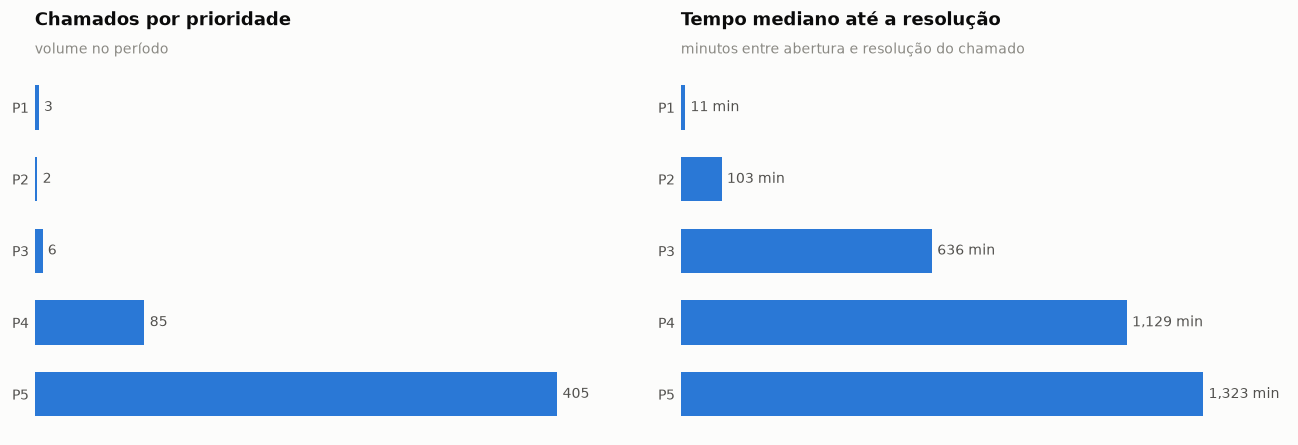

In [58]:
f, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 3.8))
barras_h(a1, d.prioridade, d.chamados.values, color=CAT[0])
titulo(a1, "Chamados por prioridade", "volume no período")

# MTTR: prioridade é ordinal, logo escala sequencial de um tom só.
cor = [SEQ[7 - min(i, 5)] for i in range(len(d))]
barras_h(a2, d.prioridade, d.mttr_mediano_min.values, color=CAT[0],
         fmt="{:,.0f} min")
titulo(a2, "Tempo mediano até a resolução",
       "minutos entre abertura e resolução do chamado")
plt.tight_layout()
plt.show()

A pirâmide de prioridade é fortemente concentrada na base (P4/P5), mas o tempo
de resolução **cresce** conforme a prioridade cai — o comportamento esperado de
uma fila que prioriza o crítico. O ponto relevante para o projeto está no
contraste de ordens de grandeza: o P1 resolve em minutos, o P5 leva quase um
dia. Um chamado de baixa prioridade que na verdade é o sintoma de uma
degradação ampla fica parado nessa fila — exatamente o custo que a correlação
automática pretende atacar.

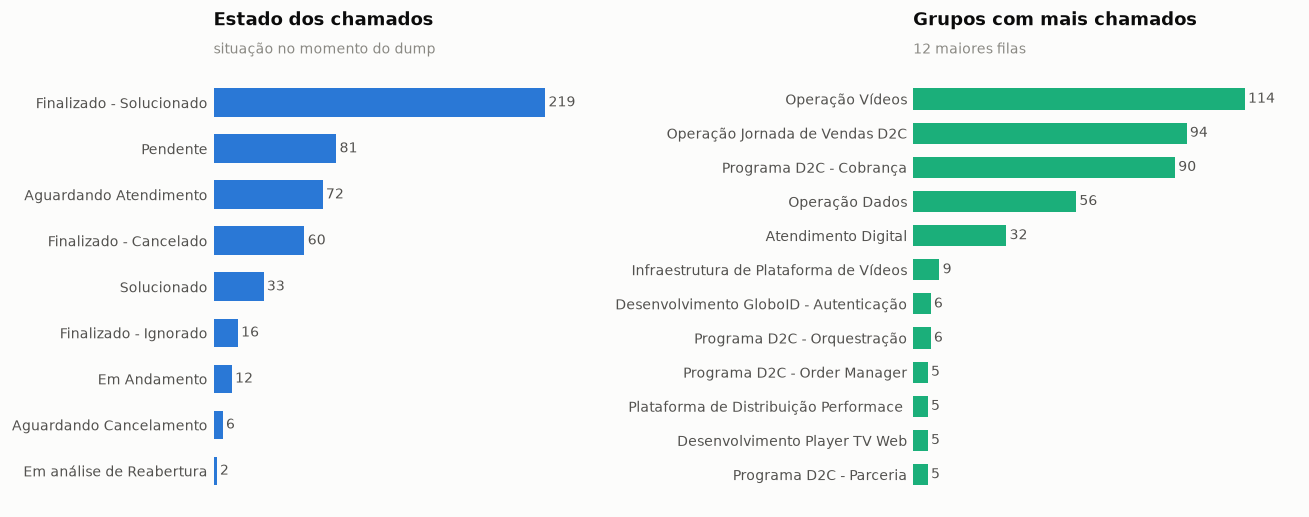

,grupo,chamados,mttr_min
0,Operação Vídeos,114,158.6
1,Operação Jornada de Vendas D2C,94,88.61
2,Programa D2C - Cobrança,90,"5,487"
3,Operação Dados,56,223.3
4,Atendimento Digital,32,"1,272"
5,Infraestrutura de Plataforma de Vídeos,9,"6,964"
6,Desenvolvimento GloboID - Autenticação com Ope...,6,"6,540"
7,Programa D2C - Orquestração,6,"8,461"
8,Programa D2C - Order Manager,5,"4,320"
9,Plataforma de Distribuição Performace & Teleme...,5,"9,713"


In [59]:
d = q("""
    SELECT state estado, count(*) n FROM incidents
    WHERE state IS NOT NULL GROUP BY 1 ORDER BY n DESC
""")
g = q("""
    SELECT assignment_group grupo, count(*) chamados,
           median((resolved_at - opened_at)/60000.0) mttr_min
    FROM incidents WHERE assignment_group IS NOT NULL
    GROUP BY 1 ORDER BY chamados DESC LIMIT 12
""")
f, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 4.4))
barras_h(a1, [e[:34] for e in d.estado], d.n.values, color=CAT[0])
titulo(a1, "Estado dos chamados", "situação no momento do dump")
barras_h(a2, [x[:38] for x in g.grupo], g.chamados.values, color=CAT[2])
titulo(a2, "Grupos com mais chamados", "12 maiores filas")
plt.tight_layout()
plt.show()
g

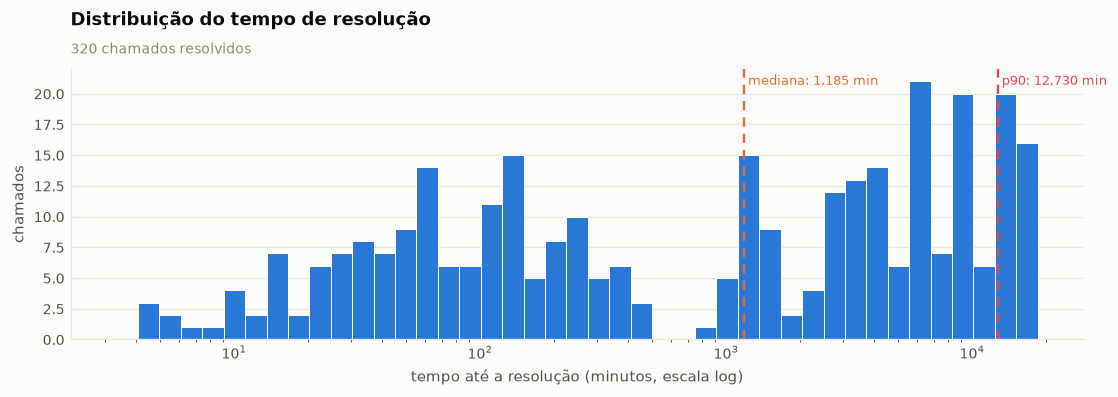

In [60]:
# Distribuição do tempo de resolução. Histograma em escala log, porque o MTTR
# se espalha por várias ordens de grandeza.
h = q("""
    SELECT (resolved_at - opened_at)/60000.0 AS minutos FROM incidents
    WHERE resolved_at IS NOT NULL AND resolved_at > opened_at
""").minutos.values
f, ax = fig(9.5, 3.4)
bins = np.logspace(np.log10(max(h.min(), 0.1)), np.log10(h.max()), 44)
ax.hist(h, bins=bins, color=CAT[0], edgecolor=SURFACE, linewidth=0.6)
ax.set_xscale("log")
ax.set_xlabel("tempo até a resolução (minutos, escala log)")
ax.set_ylabel("chamados")
for v, lab, cor in [(np.median(h), "mediana", CAT[1]),
                    (np.percentile(h, 90), "p90", CAT[7])]:
    ax.axvline(v, color=cor, lw=1.4, ls=(0, (4, 3)))
    ax.text(v, ax.get_ylim()[1] * 0.94, f" {lab}: {v:,.0f} min",
            fontsize=8, color=cor)
titulo(ax, "Distribuição do tempo de resolução",
       f"{len(h):,} chamados resolvidos")
plt.tight_layout()
plt.show()

In [61]:
# Campos de causa raiz: quanto do acervo é aproveitável para treinar correlação?
q("""
    SELECT
      count(*) chamados,
      100.0*count(short_description)/count(*) pct_com_descricao,
      100.0*count(cause)/count(*) pct_com_causa,
      100.0*count(u_what_s_the_root_cause)/count(*) pct_com_causa_raiz,
      100.0*count(close_notes)/count(*) pct_com_notas,
      100.0*count(category)/count(*) pct_com_categoria,
      100.0*count(business_service)/count(*) pct_com_servico,
      100.0*count(*) FILTER (
        WHERE u_this_incident_was_caused_by_a_change_or_deploy = 'true'
      )/count(*) pct_causado_por_deploy
    FROM incidents
""")

,chamados,pct_com_descricao,pct_com_causa,pct_com_causa_raiz,pct_com_notas,pct_com_categoria,pct_com_servico,pct_causado_por_deploy
0,501,0,0,0,0,84.83,100,0.5988


## 5.3. Rótulos analíticos: `incident_label`

In [62]:
q("""
    SELECT id, tier, kind AS tipo, severity AS severidade, verdict AS veredito,
           provenance AS procedencia,
           to_timestamp(ts_start/1000) inicio,
           round((ts_end - ts_start)/3600000.0, 2) duracao_h,
           services AS servicos
    FROM incident_label ORDER BY ts_start
""")

,id,tier,tipo,severidade,veredito,procedencia,inicio,duracao_h,servicos
0,2026-03-25-search-api-4h,2,incident,?,NaN,detector-derived,2026-03-25 07:00:00+00:00,4,"[""search-api""]"
1,2026-04-06-search-api-1h,2,incident,?,NaN,detector-derived,2026-04-06 00:00:00+00:00,1,"[""search-api""]"
2,2026-04-15-gigagloob-ultron,2,incident,?,NaN,detector-derived,2026-04-15 04:00:00+00:00,1,"[""gigagloob-ultron""]"
3,2026-04-16-videos-api-db-empty,1,incident,P1,NaN,rca-confirmed,2026-04-16 21:13:00+00:00,0.58,"[""videos-api"", ""channels-api"", ""quicksilver"", ..."
4,2026-04-29-load-test,2,load_test,NaN,NaN,team-confirmed,2026-04-29 21:00:00+00:00,6,"[""*""]"
5,2026-05-04-mystique-rpm-jarvis-products,2,incident,?,NaN,detector-derived,2026-05-04 13:00:00+00:00,2.5,"[""mystique-api-rpaas-be-gcp-prod"", ""jarvis-pro..."
6,2026-05-04-evening-cluster,2,incident,?,NaN,detector-derived,2026-05-04 17:00:00+00:00,2.5,"[""mystique-api-rpaas-be-gcp-prod"", ""jarvis-gra..."
7,2026-05-04-search-api-60pct,2,incident,?,NaN,detector-derived,2026-05-04 20:00:00+00:00,2.5,"[""search-api"", ""jarvis-gateway"", ""quicksilver""]"
8,2026-05-06-broadcast-soccer-spike,2,incident,?,NaN,team-confirmed,2026-05-06 20:00:00+00:00,1.5,"[""jarvis-graph/Broadcasts"", ""jarvis-graph/Deta..."
9,2026-05-07-morning-multi-source,2,incident,?,NaN,detector-derived,2026-05-07 05:00:00+00:00,5.25,"[""jarvis-graph/getOfferContinueWatchingItems"",..."


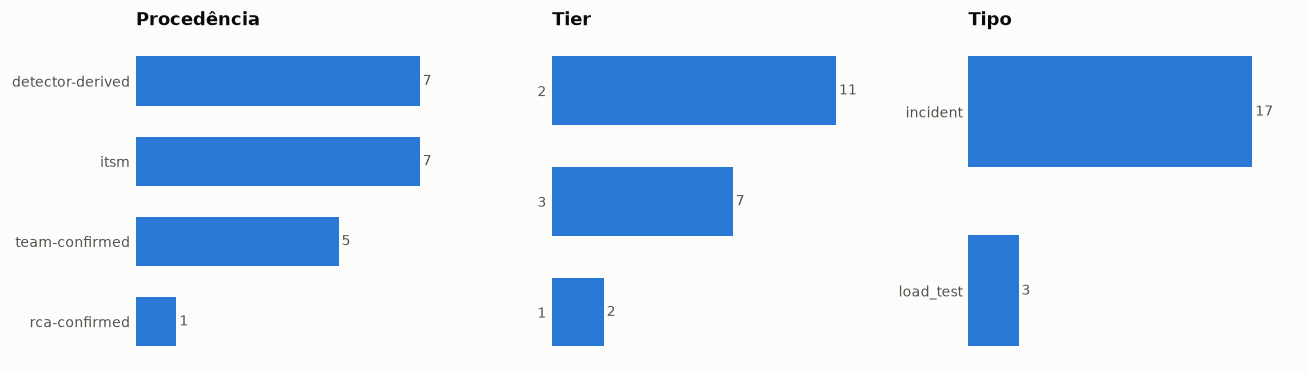

serviços citados nos rótulos:


,servico,rotulos
0,Globoplay,5
1,search-api,5
2,*,3
3,Consumo de vídeo ao vivo ou simulcast,3
4,quicksilver,2
5,Vídeo - Produtos Globoplay,2
6,jarvis-gateway,2
7,Encoding Factory (EF),2
8,mystique-api-rpaas-be-gcp-prod,2
9,cdn_live,1


In [63]:
f, axes = plt.subplots(1, 3, figsize=(11.0, 3.2))
for ax, col, tit in [(axes[0], "provenance", "Procedência"),
                     (axes[1], "tier", "Tier"),
                     (axes[2], "kind", "Tipo")]:
    d = q(f"SELECT {col} k, count(*) n FROM incident_label GROUP BY 1 ORDER BY n DESC")
    barras_h(ax, [str(x)[:24] for x in d.k], d.n.values, color=CAT[0])
    titulo(ax, tit)
plt.tight_layout()
plt.show()

print("serviços citados nos rótulos:")
q("""
    SELECT servico, count(*) rotulos FROM (
        SELECT trim(unnest(str_split(
                   replace(replace(replace(services, '[', ''), ']', ''), '"', ''),
                   ','))) AS servico
        FROM incident_label
    ) WHERE servico <> '' GROUP BY 1 ORDER BY rotulos DESC
""")

São **20 rótulos** — um acervo pequeno para treinar um classificador
supervisionado, mas suficiente como conjunto de avaliação de um detector. A
mistura de procedências é o dado mais informativo: rótulos `detector-derived`
foram gerados automaticamente e ainda não têm veredito humano, enquanto
`team-confirmed` e `rca-confirmed` carregam validação. Só estes últimos servem
como verdade de referência.

Vale notar que três rótulos são `load_test`: janelas de teste de carga que um
detector ingênuo classificaria como incidente. Elas são o contraexemplo mais
valioso do acervo, porque delimitam o que **não** deve gerar alerta.

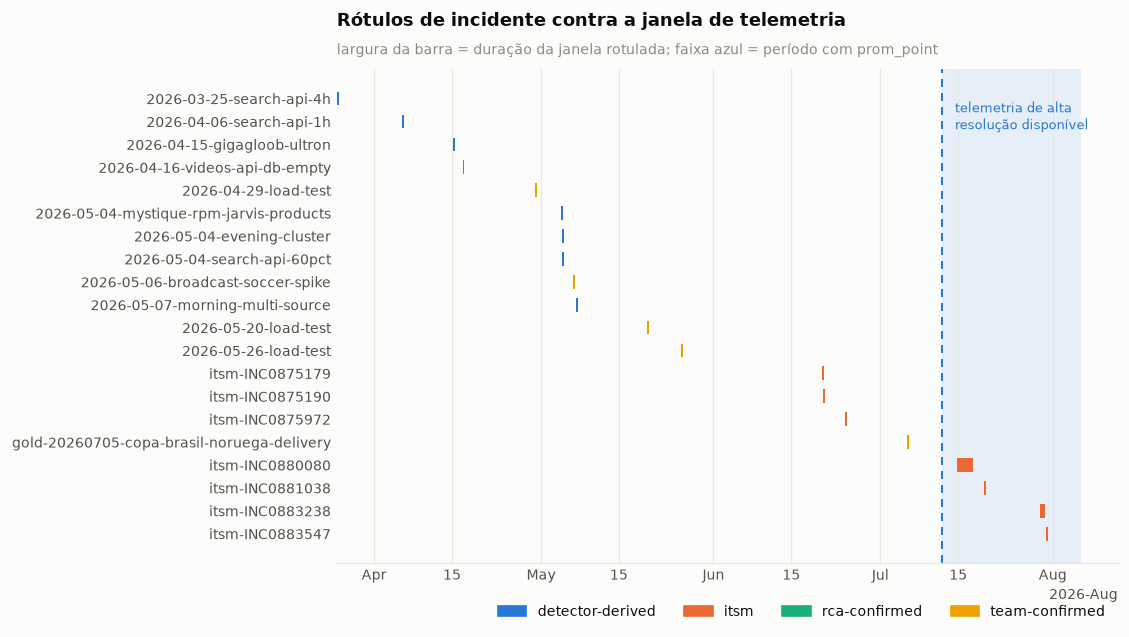

In [64]:
# Linha do tempo dos rótulos, para ver como se distribuem no período coberto.
d = q("""
    SELECT id, to_timestamp(ts_start/1000) ini,
           to_timestamp(coalesce(ts_end, ts_start + 3600000)/1000) fim,
           provenance, kind
    FROM incident_label ORDER BY ts_start
""")
# janela em que existe telemetria de alta resolução, para contraste
tel = q("""
    SELECT to_timestamp(min(epoch_ms)/1000) a, to_timestamp(max(epoch_ms)/1000) b
    FROM prom_point
""").iloc[0]

cores_prov = {p: CAT[i] for i, p in enumerate(sorted(d.provenance.unique()))}
f, ax = fig(9.5, 5.4)
y = np.arange(len(d))
ini = mpl.dates.date2num(d.ini)
fim = mpl.dates.date2num(d.fim)
ax.axvspan(mpl.dates.date2num(tel.a), mpl.dates.date2num(tel.b),
           color=CAT[0], alpha=0.10, lw=0, zorder=0)
ax.axvline(mpl.dates.date2num(tel.a), color=CAT[0], lw=1.2, ls=(0, (4, 3)),
           zorder=1)
ax.barh(y, np.maximum(fim - ini, 0.35), left=ini, height=0.6, zorder=2,
        color=[cores_prov[p] for p in d.provenance])
ax.set_yticks(y, [i[:42] for i in d.id])
ax.invert_yaxis()
ax.xaxis_date()
sem_grade(ax)
ax.grid(True, axis="x")
ax.spines["left"].set_visible(False)
ax.annotate("telemetria de alta\nresolução disponível",
            xy=(mpl.dates.date2num(tel.a), 0.8),
            xytext=(8, 0), textcoords="offset points",
            fontsize=8, color=CAT[0], va="center")
handles = [mpl.patches.Patch(color=c, label=k) for k, c in cores_prov.items()]
ax.legend(handles=handles, ncol=4, loc="lower right", bbox_to_anchor=(1, -0.14))
titulo(ax, "Rótulos de incidente contra a janela de telemetria",
       "largura da barra = duração da janela rotulada; faixa azul = período com prom_point")
plt.tight_layout()
plt.show()

Os rótulos cobrem de março a julho de 2026, mas a telemetria de alta resolução
(`prom_point`, `signal_point`) começa apenas em 12 de julho. **A maior parte dos
rótulos não tem telemetria correspondente no dump.** Isso restringe severamente
o que se pode validar: a seção 7 quantifica quantos rótulos sobrevivem ao
recorte.

---
# 6. Operação da coleta

As tabelas `*_run` são o log do próprio Argus: quanto tempo cada coletor levou,
quantas linhas trouxe e quanto custou. Elas respondem uma pergunta que o caso de
negócio levanta explicitamente — o custo de propriedade de uma plataforma
própria — com número em vez de estimativa.

In [65]:
d = q("""
    SELECT source fonte, count(*) execucoes,
           sum(rows_upserted) linhas, sum(cost_usd) custo_usd,
           median(duration_s) duracao_mediana_s,
           quantile_cont(duration_s, 0.95) duracao_p95_s,
           sum(bytes_scanned)/1e9 gb_varridos,
           to_timestamp(min(started_at)/1000) primeira,
           to_timestamp(max(started_at)/1000) ultima
    FROM collector_run GROUP BY 1 ORDER BY custo_usd DESC
""")
print(f"{d.execucoes.sum():,} execuções | US$ {d.custo_usd.sum():,.2f} no período | "
      f"{d.gb_varridos.sum():,.1f} GB varridos")
d

2,763 execuções | US$ 120.85 no período | 7,655.5 GB varridos


,fonte,execucoes,linhas,custo_usd,duracao_mediana_s,duracao_p95_s,gb_varridos,primeira,ultima
0,llm_investigate,252,"3,318",43.15,94.42,174,0.04167,2026-07-02 21:40:38.043000+00:00,2026-08-06 18:30:24.739000+00:00
1,llm_critic,277,"1,628",26.42,96.94,158.3,0.0173,2026-07-03 07:30:14.085000+00:00,2026-08-06 18:30:24.739000+00:00
2,long_tail,7,14,26.36,0,0,"5,272",2026-07-10 15:00:40.992000+00:00,2026-08-03 09:16:36.299000+00:00
3,llm_reinvestigate,60,595,9.331,106.7,162.2,0.009513,2026-07-06 12:00:16.235000+00:00,2026-08-06 16:45:17.805000+00:00
4,youbora_live,47,2.45e+05,4.1,2.262,5.912,819.9,2026-07-01 22:00:21.214000+00:00,2026-08-06 09:01:51.596000+00:00
5,llm_narrator,1765,"4,223",3.62,0.1155,10.82,0.05694,2026-07-02 21:51:49.724000+00:00,2026-08-06 21:49:09.001000+00:00
6,youbora_active,61,1.072e+06,2.405,1.157,1.842,481,2026-07-01 22:01:58.363000+00:00,2026-08-06 09:06:53.612000+00:00
7,youbora_player_live,47,2.035e+04,2.142,0.07775,0.09854,428.4,2026-07-01 22:01:03.101000+00:00,2026-08-06 09:02:14.435000+00:00
8,youbora_device,61,2.926e+06,1.252,1.5,2.224,250.4,2026-07-01 21:59:12.488000+00:00,2026-08-06 09:00:57.777000+00:00
9,youbora_player,47,2.044e+04,0.9399,0.0575,0.09328,188,2026-07-01 21:58:38.621000+00:00,2026-08-06 09:00:31.569000+00:00


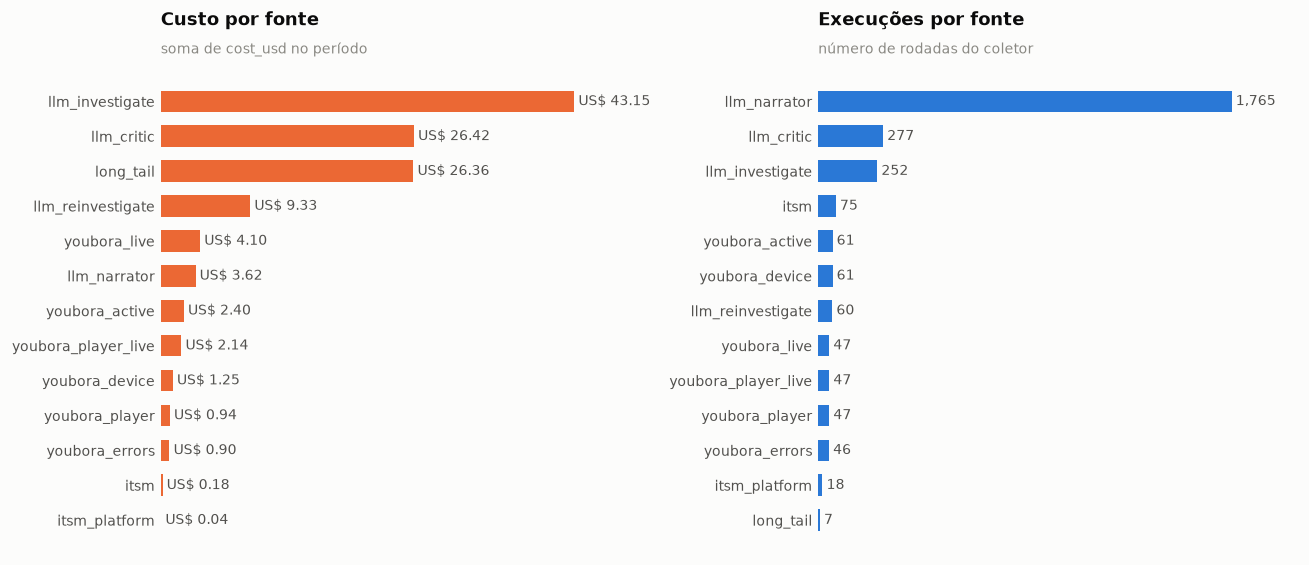

In [66]:
f, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 4.8))
top = d.nlargest(14, "custo_usd")
barras_h(a1, top.fonte, top.custo_usd.values, color=CAT[1], fmt="US$ {:,.2f}")
titulo(a1, "Custo por fonte", "soma de cost_usd no período")
top2 = d.nlargest(14, "execucoes")
barras_h(a2, top2.fonte, top2.execucoes.values, color=CAT[0])
titulo(a2, "Execuções por fonte", "número de rodadas do coletor")
plt.tight_layout()
plt.show()

O custo se concentra nas fontes `llm_*` — as etapas de investigação, crítica e
narrativa que usam modelo de linguagem — e não na ingestão de telemetria. É um
dado relevante para o dimensionamento da solução proposta: o gargalo econômico
da camada agêntica não é armazenar métrica, é **raciocinar sobre ela**. Qualquer
requisito não funcional de custo precisa mirar a frequência de invocação do
agente, não o volume de ingestão.

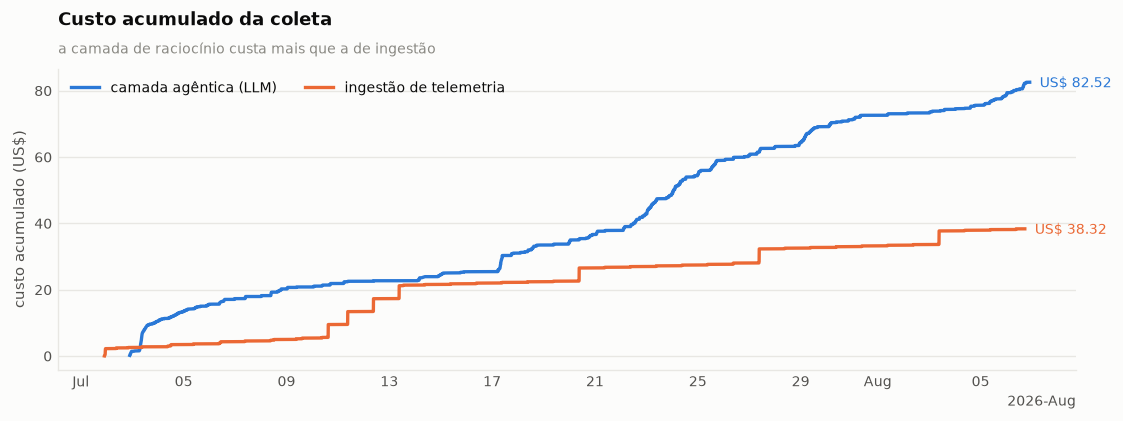

In [67]:
# Custo acumulado ao longo do tempo, separando as etapas de LLM das demais.
d = q("""
    SELECT to_timestamp(started_at/1000) t,
           CASE WHEN source LIKE 'llm%' THEN 'camada agêntica (LLM)'
                ELSE 'ingestão de telemetria' END AS classe,
           cost_usd
    FROM collector_run WHERE cost_usd IS NOT NULL ORDER BY 1
""")
f, ax = fig(9.5, 3.6)
for i, (k, g) in enumerate(d.groupby("classe")):
    ax.plot(g.t, g.cost_usd.cumsum(), color=CAT[i], lw=2, label=k)
    ax.annotate(f"US$ {g.cost_usd.sum():,.2f}",
                (g.t.iloc[-1], g.cost_usd.cumsum().iloc[-1]),
                xytext=(6, -3), textcoords="offset points",
                fontsize=8.5, color=CAT[i])
ax.legend(ncol=2, loc="upper left")
ax.set_ylabel("custo acumulado (US$)")
titulo(ax, "Custo acumulado da coleta",
       "a camada de raciocínio custa mais que a de ingestão")
plt.tight_layout()
plt.show()

In [68]:
# Saúde dos coletores especializados.
for t, nome in [("prom_run", "Prometheus"), ("nr_run", "New Relic"),
                ("apollo_run", "Apollo"), ("ca_run", "Cloud Armor"),
                ("rpaas_run", "RPaaS")]:
    cols = set(q(f"SELECT * FROM {t} LIMIT 0").columns)
    extra = []
    if "queries_ok" in cols:
        extra.append("sum(queries_err) erros_query")
    if "points_inserted" in cols:
        extra.append("sum(points_inserted) pontos")
    if "rows_inserted" in cols:
        extra.append("sum(rows_inserted) linhas")
    if "rows_seen" in cols:
        extra.append("sum(rows_seen) linhas_vistas")
    if "buckets_upd" in cols:
        extra.append("sum(buckets_upd) buckets")
    sel = ", ".join(["count(*) execucoes", "median(duration_s) dur_mediana_s",
                     "max(duration_s) dur_max_s"] + extra)
    print(f"--- {nome} ({t})")
    print(q(f"SELECT {sel} FROM {t}").to_string(index=False))
    print()

--- Prometheus (prom_run)
 execucoes  dur_mediana_s  dur_max_s  erros_query    pontos
      5407          123.7      3,251    5.219e+05 1.094e+08

--- New Relic (nr_run)
 execucoes  dur_mediana_s  dur_max_s    linhas  linhas_vistas
      5412           1.31      36.02 9.132e+05       3.49e+06

--- Apollo (apollo_run)
 execucoes  dur_mediana_s  dur_max_s    linhas
      2597          1.822      1,055 1.588e+06

--- Cloud Armor (ca_run)
 execucoes  dur_mediana_s  dur_max_s    pontos
      5394           5.25      44.75 3.521e+06

--- RPaaS (rpaas_run)
 execucoes  dur_mediana_s  dur_max_s  buckets
       566          80.82      318.3        0



In [69]:
# Frescor da ingestão por fonte, e quanto do histórico veio no dump.
ref = q("SELECT max(last_ingested_ts) m FROM signal_meta").m.iloc[0]
d = q(f"""
    SELECT source fonte, rows_total linhas_historico,
           to_timestamp(last_ingested_ts/1000) ultimo_dado,
           ({ref} - last_ingested_ts)/60000.0 atraso_min,
           rows_last_run linhas_ultima_rodada
    FROM signal_meta ORDER BY linhas_historico DESC
""")
d

,fonte,linhas_historico,ultimo_dado,atraso_min,linhas_ultima_rodada
0,prometheus,1867221524,2026-08-06 21:29:09.650000+00:00,0.9558,358110
1,apollo,20647425,2026-08-06 21:00:00+00:00,30.12,8609
2,redis,8608044,2026-08-06 21:29:09.650000+00:00,0.9558,1146
3,youbora_device,3960852,2026-08-06 21:00:00+00:00,30.12,190
4,cloudarmor,3520334,2026-08-06 21:28:29+00:00,1.633,1180
5,newrelic,3435702,2026-08-06 21:30:07+00:00,0,212
6,rpaas,2069021,2026-08-06 21:30:00+00:00,0.1167,910
7,cdn_live_errors,1692559,2026-08-06 21:29:09.650000+00:00,0.9558,395
8,origin_live_errors,1596241,2026-08-06 21:29:09.650000+00:00,0.9558,492
9,youbora_player_live,1569790,2026-08-06 21:00:00+00:00,30.12,397


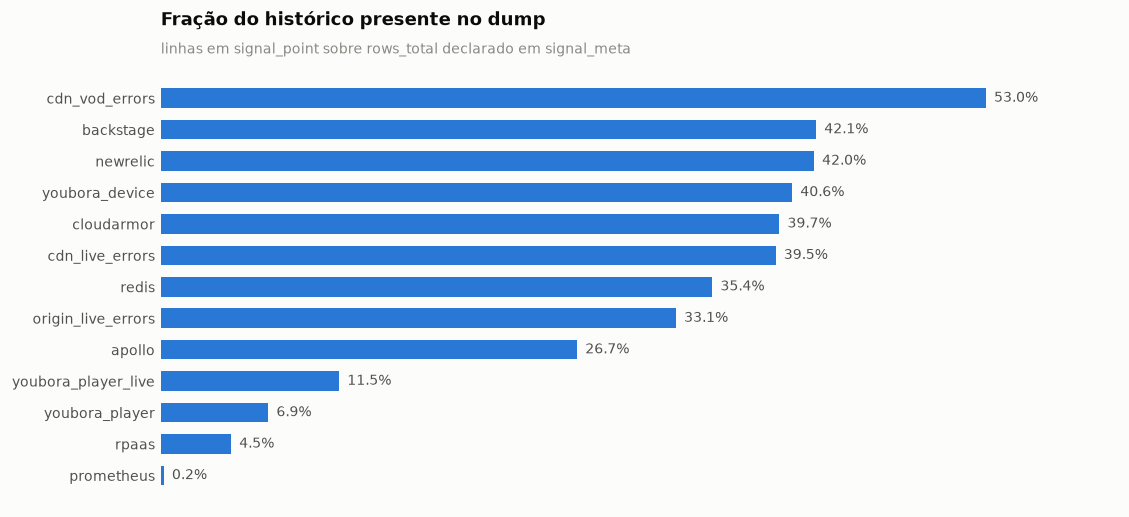

,fonte,historico,no_dump,pct
0,prometheus,1867221524,3435357,0.184
1,apollo,20647425,5522986,26.75
2,redis,8608044,3050066,35.43
3,youbora_device,3960852,1606772,40.57
4,cloudarmor,3520334,1399048,39.74
5,newrelic,3435702,1441830,41.97
6,rpaas,2069021,93246,4.507
7,cdn_live_errors,1692559,668634,39.5
8,origin_live_errors,1596241,528310,33.1
9,youbora_player_live,1569790,179790,11.45


In [70]:
# O dump é uma janela do histórico, não a base inteira. Quanto ele representa?
d = q("""
    SELECT m.source fonte, m.rows_total historico,
           count(s.ts) no_dump,
           100.0 * count(s.ts) / nullif(m.rows_total, 0) pct
    FROM signal_meta m LEFT JOIN signal_point s ON s.source = m.source
    GROUP BY 1, 2 ORDER BY historico DESC
""")
g = d.sort_values("pct", ascending=False)
f, ax = fig(9.5, 4.4)
barras_h(ax, g.fonte, g.pct.values, color=CAT[0], fmt="{:.1f}%")
titulo(ax, "Fração do histórico presente no dump",
       "linhas em signal_point sobre rows_total declarado em signal_meta")
plt.tight_layout()
plt.show()
d

O dump é um **recorte**, não a base completa. O Prometheus declara 1,87 bilhão
de linhas no histórico e entrega menos de 0,2% delas aqui. Isso não invalida a
análise — a janela é contínua e recente —, mas impede qualquer afirmação sobre
sazonalidade longa, e significa que os volumes desta análise **não** devem ser
usados para dimensionar a plataforma de produção.

---
# 7. Análise cruzada entre camadas

Até aqui cada fonte foi lida isoladamente — que é exatamente o problema que o
projeto quer resolver. Esta seção faz o oposto: coloca infraestrutura, QoE,
mudanças e incidentes na **mesma linha do tempo** e pergunta se um lado explica
o outro. É o teste de viabilidade da premissa central da solução proposta.

## 7.1. A janela realmente comum

In [71]:
CHAVE = {
    "prom_point": "epoch_ms", "signal_point": "ts", "signal_bucket": "bts",
    "rpaas_bucket": "bucket_ts_ms", "ca_point": "ts_ms",
    "service_overview": "timestamp", "operation_metrics": "start_ts",
    "live_qoe_hourly": "hour_ts", "live_active_15min": "bucket_ts",
    "player_hourly": "hour_ts", "device_hourly": "hour_ts",
    "geo_hourly": "hour_ts", "error_cat_hourly": "hour_ts",
    "live_error_attr_hourly": "hour_ts", "tsuru_event": "start_time_ms",
    "incidents": "opened_at", "incident_label": "ts_start",
}
lim = q(" UNION ALL ".join(
    f"SELECT '{t}' tabela, min({c}) a, max({c}) b FROM {t}"
    for t, c in CHAVE.items() if t in TABLES))
lim["inicio"] = pd.to_datetime(lim.a, unit="ms", utc=True)
lim["fim"] = pd.to_datetime(lim.b, unit="ms", utc=True)

# a interseção é ditada pelas fontes de telemetria e QoE, não pelos incidentes
nucleo = ["prom_point", "signal_point", "rpaas_bucket", "service_overview",
          "live_qoe_hourly", "live_active_15min", "player_hourly"]
sub = lim[lim.tabela.isin(nucleo)]
T0, T1 = sub.inicio.max(), sub.fim.min()
print(f"janela comum às camadas de telemetria e QoE:")
print(f"  {T0:%Y-%m-%d %H:%M} → {T1:%Y-%m-%d %H:%M} UTC "
      f"({(T1 - T0).days} dias, {(T1 - T0).total_seconds() / 3600:.0f} h)")
MS0, MS1 = int(T0.timestamp() * 1000), int(T1.timestamp() * 1000)

lim[["tabela", "inicio", "fim"]].sort_values("inicio").reset_index(drop=True)

janela comum às camadas de telemetria e QoE:
  2026-07-22 00:00 → 2026-08-05 23:00 UTC (14 dias, 359 h)


,tabela,inicio,fim
0,incident_label,2026-03-25 07:00:00+00:00,2026-07-30 20:18:10+00:00
1,incidents,2026-06-12 11:56:02+00:00,2026-08-05 22:19:17+00:00
2,tsuru_event,2026-07-07 03:03:40.714000+00:00,2026-08-05 19:56:18.979000+00:00
3,signal_bucket,2026-07-10 18:45:00+00:00,2026-08-05 23:45:00+00:00
4,signal_point,2026-07-12 00:00:00+00:00,2026-08-05 23:59:28+00:00
5,rpaas_bucket,2026-07-12 00:00:00+00:00,2026-08-05 23:45:00+00:00
6,operation_metrics,2026-07-12 00:00:00+00:00,2026-08-05 23:52:00+00:00
7,player_hourly,2026-07-12 00:00:00+00:00,2026-08-05 23:00:00+00:00
8,device_hourly,2026-07-12 00:00:00+00:00,2026-08-05 23:00:00+00:00
9,service_overview,2026-07-12 00:00:05+00:00,2026-08-05 23:45:29+00:00


In [72]:
# Quanto do acervo semântico sobrevive a esse recorte?
print(q(f"""
    SELECT 'rótulos (incident_label)' AS acervo,
           count(*) total,
           count(*) FILTER (WHERE ts_start BETWEEN {MS0} AND {MS1}) na_janela
    FROM incident_label
    UNION ALL
    SELECT 'chamados (incidents)', count(*),
           count(*) FILTER (WHERE opened_at BETWEEN {MS0} AND {MS1})
    FROM incidents
    UNION ALL
    SELECT 'eventos ao vivo (live_event)', count(*),
           count(*) FILTER (WHERE start_ts BETWEEN {MS0} AND {MS1})
    FROM live_event
    UNION ALL
    SELECT 'mudanças (tsuru_event)', count(*),
           count(*) FILTER (WHERE start_time_ms BETWEEN {MS0} AND {MS1})
    FROM tsuru_event
""").to_string(index=False))

                      acervo  total  na_janela
    rótulos (incident_label)     20          2
        chamados (incidents)    501        154
eventos ao vivo (live_event)     24         10
      mudanças (tsuru_event)   1903       1013


Este é o resultado mais importante da seção. O acervo rotulado, que seria a
verdade de referência para avaliar um detector, **quase não sobrevive** ao
recorte: a telemetria de alta resolução e os rótulos de incidente mal se
encontram no tempo. Um modelo supervisionado treinado neste dump teria pouquíssimos
exemplos positivos com sinal correspondente. O caminho viável com estes dados é
**detecção não supervisionada** (desvio de linha de base), usando os poucos
rótulos que sobrevivem apenas como verificação qualitativa.

## 7.2. A infraestrutura explica a experiência?

In [73]:
# Todas as camadas reamostradas para a grade horária, que é a mais grossa.
painel = q(f"""
    WITH qoe AS (
        SELECT hour_ts h, sum(sessions) sessoes, sum(errors) erros,
               100.0*sum(errors)/nullif(sum(sessions),0) qoe_erro_pct,
               avg(bufferratio_avg) buffer, avg(jointime_s_avg) jointime,
               avg(latency_ms_avg) latencia
        FROM live_qoe_hourly GROUP BY 1
    ),
    borda AS (
        SELECT (bucket_ts_ms // 3600000) * 3600000 h,
               sum(requests_total) req,
               100.0*sum(requests_5xx)/nullif(sum(requests_total),0) borda_5xx_pct,
               100.0*sum(requests_4xx)/nullif(sum(requests_total),0) borda_4xx_pct
        FROM rpaas_bucket GROUP BY 1
    ),
    apm AS (
        SELECT (timestamp // 3600000) * 3600000 h,
               avg(error_rate_pct) apm_erro_pct, avg(apdex_score) apdex,
               avg(response_time_avg_ms) apm_tempo
        FROM service_overview GROUP BY 1
    ),
    gql AS (
        SELECT (start_ts // 3600000) * 3600000 h,
               100.0*sum(error_count)/nullif(sum(request_count),0) gql_erro_pct,
               avg(p99_ms) gql_p99
        FROM operation_metrics GROUP BY 1
    )
    SELECT to_timestamp(qoe.h/1000) t, qoe.* EXCLUDE (h),
           borda.* EXCLUDE (h), apm.* EXCLUDE (h), gql.* EXCLUDE (h)
    FROM qoe
    LEFT JOIN borda USING (h) LEFT JOIN apm USING (h) LEFT JOIN gql USING (h)
    WHERE qoe.h BETWEEN {MS0} AND {MS1}
    ORDER BY t
""")
print(f"{len(painel)} horas na janela comum")
painel.head()

360 horas na janela comum


,t,sessoes,erros,qoe_erro_pct,buffer,jointime,latencia,req,borda_5xx_pct,borda_4xx_pct,apm_erro_pct,apdex,apm_tempo,gql_erro_pct,gql_p99
0,2026-07-22 00:00:00+00:00,1.309e+06,1.128e+04,0.862,0.8278,5.173,1.702e+04,1.73e+08,0.006717,4.369,0.1628,0.8787,167.1,0.3844,327.5
1,2026-07-22 01:00:00+00:00,5.916e+05,"3,488",0.5896,0.7255,5.126,1.483e+04,1.474e+08,0.006245,4.103,0.1342,0.8378,160.9,0.3921,335.3
2,2026-07-22 02:00:00+00:00,2.176e+05,"1,458",0.6701,0.8258,4.643,1.183e+04,1.206e+08,0.00637,3.251,0.1695,0.8293,192.2,0.3998,389
3,2026-07-22 03:00:00+00:00,1.061e+05,"1,582",1.491,0.8519,4.962,1.343e+04,9.717e+07,0.004138,2.539,0.2826,0.8184,200.5,0.2422,379.9
4,2026-07-22 04:00:00+00:00,5.256e+04,"1,184",2.252,0.893,5.133,1.414e+04,6.368e+07,0.0035,2.372,0.2646,0.8033,130.5,0.2828,427.1


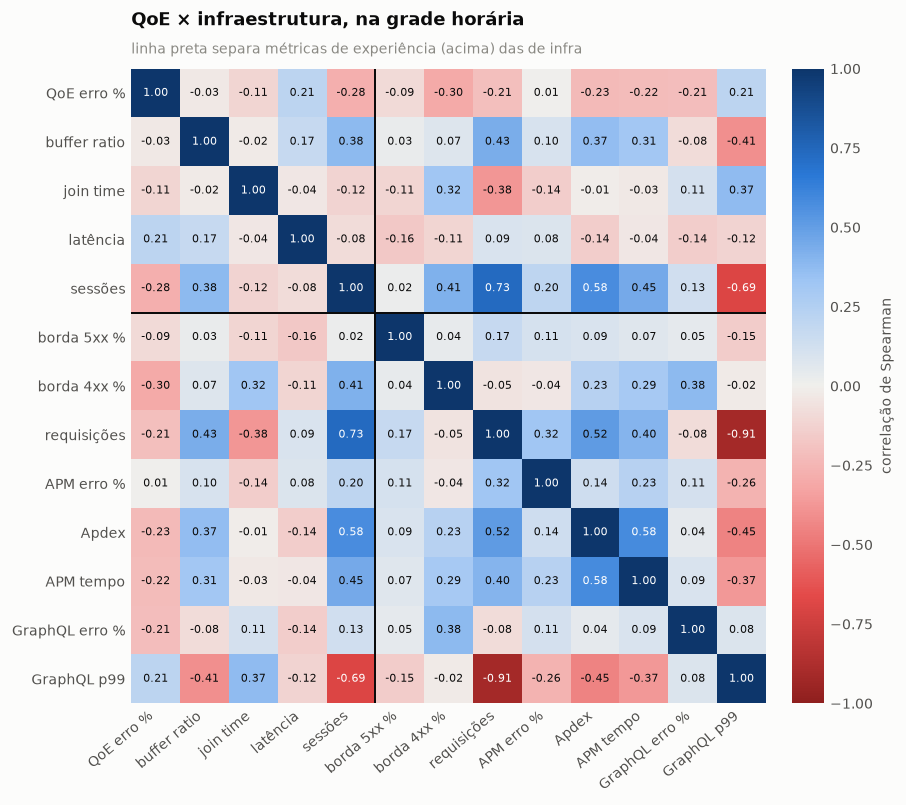

In [74]:
cols = ["qoe_erro_pct", "buffer", "jointime", "latencia", "sessoes",
        "borda_5xx_pct", "borda_4xx_pct", "req",
        "apm_erro_pct", "apdex", "apm_tempo", "gql_erro_pct", "gql_p99"]
rot = ["QoE erro %", "buffer ratio", "join time", "latência", "sessões",
       "borda 5xx %", "borda 4xx %", "requisições",
       "APM erro %", "Apdex", "APM tempo", "GraphQL erro %", "GraphQL p99"]
corr = painel[cols].corr(method="spearman")

f, ax = fig(8.4, 6.8)
im = ax.imshow(corr.values, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(rot)), rot, rotation=40, ha="right")
ax.set_yticks(range(len(rot)), rot)
sem_grade(ax)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(rot)):
    for j in range(len(rot)):
        v = corr.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.8,
                    color="#ffffff" if abs(v) > 0.55 else INK)
# separa visualmente o bloco de QoE do bloco de infraestrutura
ax.axhline(4.5, color=INK, lw=1.2)
ax.axvline(4.5, color=INK, lw=1.2)
cb = f.colorbar(im, ax=ax, fraction=0.042, pad=0.03)
cb.outline.set_visible(False)
cb.set_label("correlação de Spearman", color=INK2, fontsize=8.5)
titulo(ax, "QoE × infraestrutura, na grade horária",
       "linha preta separa métricas de experiência (acima) das de infra")
plt.tight_layout()
plt.show()

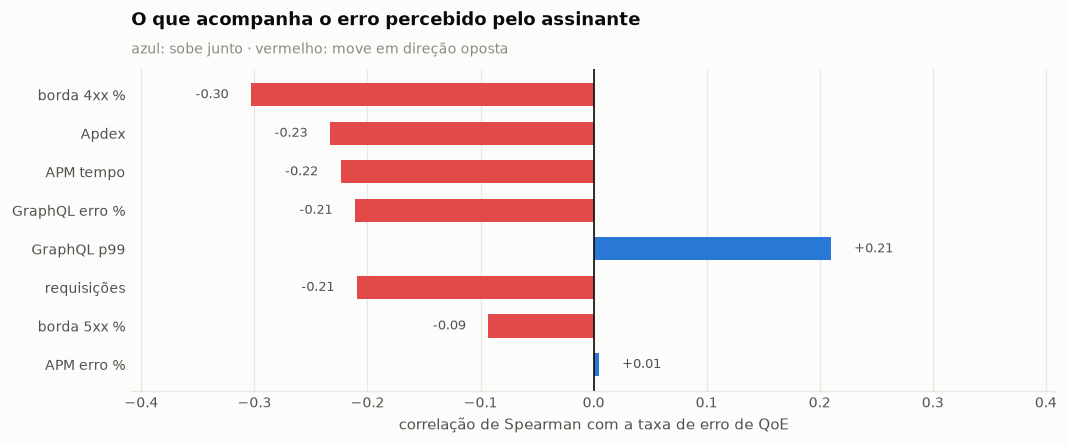

In [75]:
# Ranking explícito: o que mais se associa ao erro percebido pelo assinante?
alvo = "qoe_erro_pct"
infra = ["borda_5xx_pct", "borda_4xx_pct", "req",
         "apm_erro_pct", "apdex", "apm_tempo", "gql_erro_pct", "gql_p99"]
r = (painel[infra + [alvo]].corr(method="spearman")[alvo]
     .drop(alvo).sort_values(key=abs, ascending=False))
nomes = dict(zip(infra, ["borda 5xx %", "borda 4xx %", "requisições",
                         "APM erro %", "Apdex", "APM tempo",
                         "GraphQL erro %", "GraphQL p99"]))

f, ax = fig(9.0, 3.8)
y = np.arange(len(r))
ax.barh(y, r.values, height=0.6,
        color=[CAT[0] if v > 0 else CAT[7] for v in r.values])
ax.set_yticks(y, [nomes[i] for i in r.index])
ax.invert_yaxis()
ax.axvline(0, color=INK, lw=1)
sem_grade(ax)
ax.grid(True, axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
for yi, v in zip(y, r.values):
    ax.text(v + (0.02 if v > 0 else -0.02), yi, f"{v:+.2f}", va="center",
            ha="left" if v > 0 else "right", fontsize=8, color=INK2)
lim_x = max(abs(r.values)) * 1.35
ax.set_xlim(-lim_x, lim_x)
ax.set_xlabel("correlação de Spearman com a taxa de erro de QoE")
titulo(ax, "O que acompanha o erro percebido pelo assinante",
       "azul: sobe junto · vermelho: move em direção oposta")
plt.tight_layout()
plt.show()

As associações entre a infraestrutura e o erro percebido são **fracas** na grade
horária. Isso não é um defeito da análise — é a confirmação empírica da tese do
projeto. Se a taxa de 5xx da borda explicasse o erro do player, bastaria um
alarme de limiar na borda e não haveria problema a resolver. O que os dados
mostram é que a experiência degrada por caminhos que a métrica agregada de
infraestrutura não captura, e que **a média horária nacional dilui o recorte
onde a falha realmente acontece**.

Duas implicações práticas: (1) a correlação precisa ser feita por recorte, não
no agregado; (2) a janela de uma hora é grossa demais — um incidente de vinte
minutos desaparece nela.

## 7.3. Mudanças na plataforma versus incidentes

A hipótese "o incidente foi causado por uma mudança" é a mais comum na triagem.
Ela é testável: basta ver se um chamado tende a ser precedido por um deploy.
Mas uma proporção alta só significa alguma coisa se for **maior que a de um
instante qualquer** — por isso a comparação abaixo inclui um grupo de controle
com instantes sorteados na mesma janela.

In [76]:
d = q("""
    WITH janela AS (
        SELECT greatest(min_i, min_e) a, least(max_i, max_e) b FROM (
            SELECT min(opened_at) min_i, max(opened_at) max_i,
                   (SELECT min(start_time_ms) FROM tsuru_event) min_e,
                   (SELECT max(start_time_ms) FROM tsuru_event) max_e
            FROM incidents)
    ),
    reais AS (
        SELECT opened_at t FROM incidents, janela
        WHERE opened_at BETWEEN a AND b
    ),
    controle AS (
        SELECT a + (random() * (b - a))::bigint t FROM janela, range(20000)
    )
    SELECT 'chamados reais' grupo, count(*) n,
           100.0 * count(*) FILTER (WHERE EXISTS (
               SELECT 1 FROM tsuru_event e
               WHERE e.start_time_ms BETWEEN r.t - 6*3600000 AND r.t)) / count(*) pct
    FROM reais r
    UNION ALL
    SELECT 'instantes sorteados (controle)', count(*),
           100.0 * count(*) FILTER (WHERE EXISTS (
               SELECT 1 FROM tsuru_event e
               WHERE e.start_time_ms BETWEEN c.t - 6*3600000 AND c.t)) / count(*)
    FROM controle c
""")
print("chamados precedidos por alguma mudança em até 6 h:")
print(d.to_string(index=False))
lift = d.pct.iloc[0] - d.pct.iloc[1]
print(f"\ndiferença sobre o controle: {lift:+.1f} pontos percentuais")

print()
print("declaração explícita no próprio chamado:")
print(q("""
    SELECT u_this_incident_was_caused_by_a_change_or_deploy AS causado_por_deploy,
           count(*) chamados
    FROM incidents GROUP BY 1 ORDER BY chamados DESC
""").to_string(index=False))

chamados precedidos por alguma mudança em até 6 h:
                         grupo     n   pct
                chamados reais   276 93.48
instantes sorteados (controle) 20000 86.36

diferença sobre o controle: +7.1 pontos percentuais

declaração explícita no próprio chamado:
causado_por_deploy  chamados
             false       498
              true         3


> **A proximidade temporal com um deploy não é evidência de causa neste
> dataset.** Chamados reais e instantes sorteados ao acaso têm praticamente a
> mesma chance de serem precedidos por uma mudança em 6 horas — a diferença é de
> poucos pontos percentuais. O motivo é a densidade: as mudanças são tão
> frequentes (e concentradas em rajadas) que quase qualquer instante tem uma
> perto.
>
> Sem esse controle, a estatística de "9 em cada 10 incidentes vieram depois de
> um deploy" pareceria um achado forte, e seria falsa. Um mecanismo de atribuição
> de causa que use proximidade temporal como sinal vai gerar falso positivo em
> massa; é preciso exigir coincidência de **serviço afetado**, não só de tempo.
>
> Note também que o campo declarativo do ITSM confirma a mesma direção por outro
> caminho: apenas 3 dos 501 chamados marcam explicitamente terem sido causados
> por mudança ou deploy.

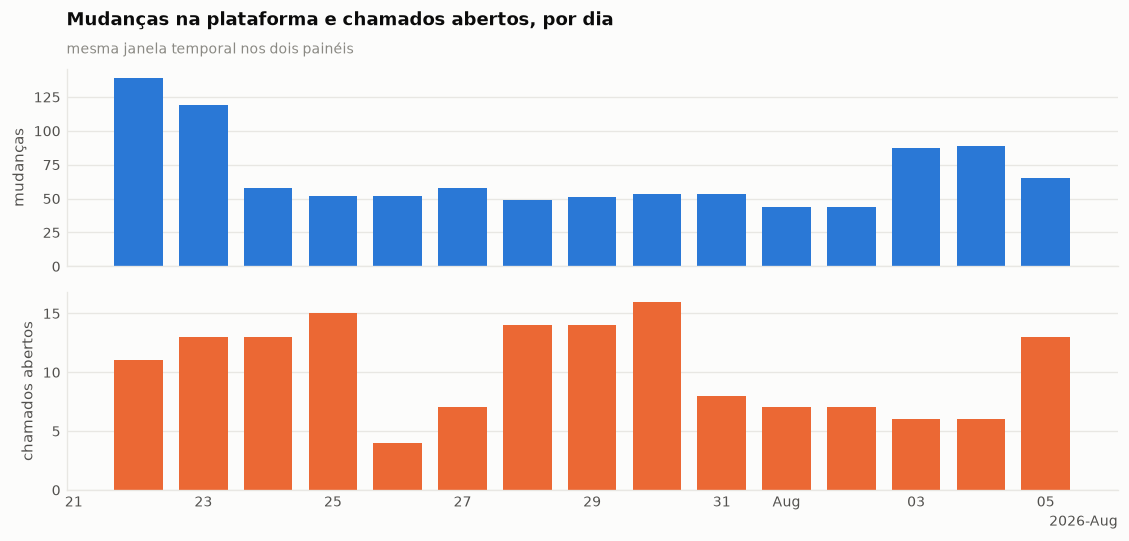

In [77]:
# Sobreposição temporal das duas séries no período comum.
mud = q(f"""
    SELECT date_trunc('day', to_timestamp(start_time_ms/1000)) d, count(*) n
    FROM tsuru_event WHERE start_time_ms BETWEEN {MS0} AND {MS1}
    GROUP BY 1 ORDER BY 1
""")
inc = q(f"""
    SELECT date_trunc('day', to_timestamp(opened_at/1000)) d, count(*) n
    FROM incidents WHERE opened_at BETWEEN {MS0} AND {MS1}
    GROUP BY 1 ORDER BY 1
""")
f, (a1, a2) = plt.subplots(2, 1, figsize=(9.5, 4.6), sharex=True)
a1.bar(mud.d, mud.n, color=CAT[0], width=0.75)
a1.set_ylabel("mudanças")
a2.bar(inc.d, inc.n, color=CAT[1], width=0.75)
a2.set_ylabel("chamados abertos")
titulo(a1, "Mudanças na plataforma e chamados abertos, por dia",
       "mesma janela temporal nos dois painéis")
plt.tight_layout()
plt.show()

## 7.4. Eventos ao vivo e carga

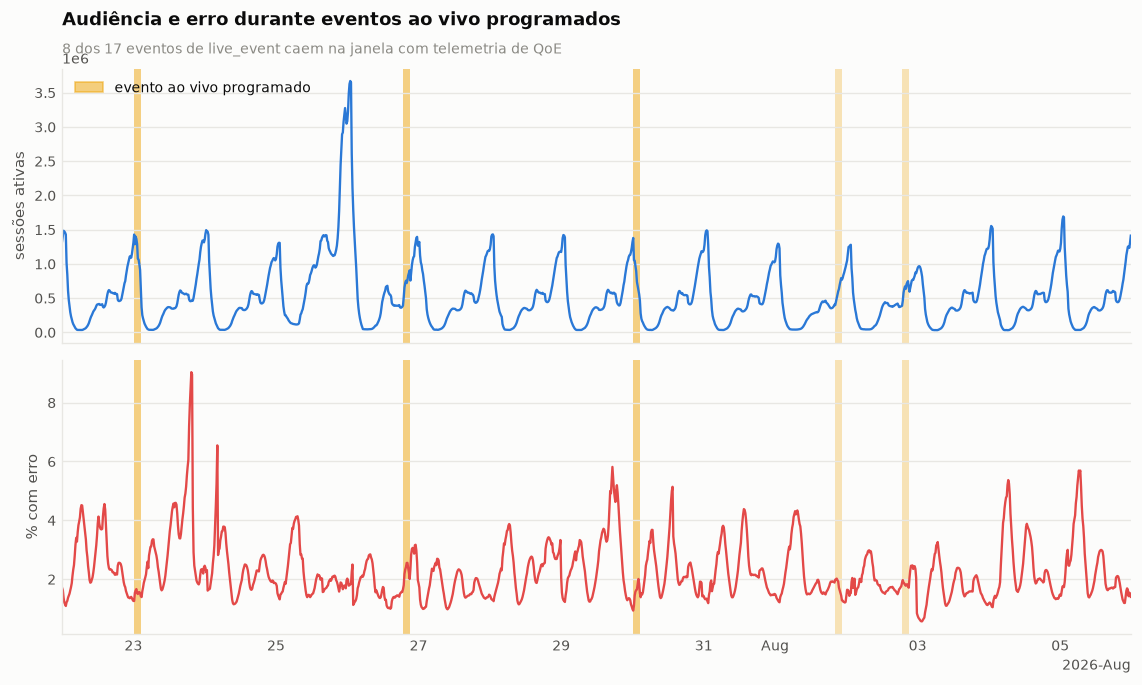

In [78]:
ev = q("""
    SELECT DISTINCT event_key, team_home, team_away, competition,
           min(start_ts) OVER (PARTITION BY event_key) ini,
           max(end_ts)   OVER (PARTITION BY event_key) fim
    FROM live_event ORDER BY ini
""")
s = q("""
    SELECT to_timestamp(bucket_ts/1000) t, sum(active_sessions) ativas,
           100.0*sum(active_with_error)/nullif(sum(active_sessions),0) pct_erro
    FROM live_active_15min GROUP BY 1 ORDER BY 1
""")

f, (a1, a2) = plt.subplots(2, 1, figsize=(9.5, 5.8), sharex=True)
for _, e in ev.iterrows():
    for ax in (a1, a2):
        ax.axvspan(pd.to_datetime(e.ini, unit="ms", utc=True),
                   pd.to_datetime(e.fim, unit="ms", utc=True),
                   color=CAT[3], alpha=0.28, lw=0, zorder=0)
a1.plot(s.t, s.ativas, color=CAT[0], lw=1.4, zorder=2)
a2.plot(s.t, s.pct_erro, color=CAT[7], lw=1.4, zorder=2)
a1.set_ylabel("sessões ativas")
a2.set_ylabel("% com erro")
# o eixo acompanha a janela da telemetria de QoE: eventos fora dela não têm
# série para comparar e só esticariam o gráfico
a1.set_xlim(s.t.min(), s.t.max())
n_dentro = ((ev.ini <= s.t.max().timestamp() * 1000)
            & (ev.fim >= s.t.min().timestamp() * 1000)).sum()
a1.legend(handles=[mpl.patches.Patch(color=CAT[3], alpha=0.5,
                                     label="evento ao vivo programado")],
          loc="upper left")
titulo(a1, "Audiência e erro durante eventos ao vivo programados",
       f"{n_dentro} dos {len(ev)} eventos de live_event caem na janela com telemetria de QoE")
plt.tight_layout()
plt.show()

In [79]:
# Dentro versus fora de evento — o pico de audiência vem acompanhado de erro?
janelas = " OR ".join(
    f"(bucket_ts BETWEEN {int(e.ini)} AND {int(e.fim)})" for _, e in ev.iterrows())
d = q(f"""
    SELECT CASE WHEN {janelas} THEN 'durante evento'
                ELSE 'fora de evento' END AS periodo,
           count(*) buckets,
           avg(active_sessions) sessoes_medias,
           max(active_sessions) sessoes_pico,
           100.0*sum(active_with_error)/nullif(sum(active_sessions),0) pct_erro,
           avg(jointime_s_avg) jointime_s, avg(bufferratio_avg) buffer,
           avg(latency_ms_p95) latencia_p95
    FROM live_active_15min GROUP BY 1
""")
d

,periodo,buckets,sessoes_medias,sessoes_pico,pct_erro,jointime_s,buffer,latencia_p95
0,durante evento,7078,"4,996",164647,1.772,6.418,0.4195,5.299e+04
1,fora de evento,203075,"3,537",383217,1.965,6.538,0.3787,5.427e+04


## 7.5. As janelas rotuladas se distinguem da linha de base?

In [80]:
# Para cada rótulo com telemetria disponível, compara a janela rotulada com a
# linha de base das 24 h anteriores.
rot = q(f"""
    SELECT id, ts_start, coalesce(ts_end, ts_start + 3600000) ts_end, provenance
    FROM incident_label
    WHERE ts_start BETWEEN {MS0} AND {MS1}
       OR coalesce(ts_end, ts_start) BETWEEN {MS0} AND {MS1}
    ORDER BY ts_start
""")
print(f"{len(rot)} de {q('SELECT count(*) n FROM incident_label').n.iloc[0]} "
      f"rótulos caem na janela com telemetria")

linhas = []
for r in rot.itertuples():
    base = q(f"""
        SELECT avg(error_rate_pct) erro, avg(apdex_score) apdex
        FROM service_overview
        WHERE timestamp BETWEEN {r.ts_start - 86400000} AND {r.ts_start}
    """).iloc[0]
    dentro = q(f"""
        SELECT avg(error_rate_pct) erro, avg(apdex_score) apdex
        FROM service_overview
        WHERE timestamp BETWEEN {r.ts_start} AND {r.ts_end}
    """).iloc[0]
    linhas.append({"rotulo": r.id, "procedencia": r.provenance,
                   "erro_base_pct": base.erro, "erro_janela_pct": dentro.erro,
                   "apdex_base": base.apdex, "apdex_janela": dentro.apdex})

if linhas:
    cmp = pd.DataFrame(linhas)
    cmp["delta_erro"] = cmp.erro_janela_pct - cmp.erro_base_pct
    display(cmp)
else:
    print("nenhum rótulo coincide com a janela de telemetria do APM — "
          "a comparação com linha de base não é possível neste dump")

2 de 20 rótulos caem na janela com telemetria


,rotulo,procedencia,erro_base_pct,erro_janela_pct,apdex_base,apdex_janela,delta_erro
0,itsm-INC0883238,itsm,3.297,0.2088,0.7944,0.7843,-3.088
1,itsm-INC0883547,itsm,0.1825,0.09315,0.7952,0.8783,-0.08935


---
# 8. Síntese

## 8.1. O que o dataset é

Uma janela contínua e recente da telemetria de produção do Globoplay, com quatro
camadas convergindo na mesma base: infraestrutura, experiência do assinante,
incidentes e o log da própria coleta. São 68,7 milhões de linhas em 33 tabelas,
sem duplicata de chave primária, sem violação de integridade referencial e com
alta continuidade nas grades temporais. **A qualidade técnica do dump é alta** —
os problemas encontrados são de *escopo*, não de *corrupção*.

## 8.2. Achados que mudam o desenho da solução

**1. O cruzamento UF × operadora não existe.** As duas dimensões de
`geo_hourly` são mutuamente exclusivas: nenhuma linha tem as duas preenchidas. O
caso de negócio sustenta que o diferencial da solução está em enxergar a
combinação de plataforma, modelo, UF e operadora — e essa combinação foi
removida na sanitização. O protótipo demonstra os recortes marginais; o
cruzamento precisa ser negociado com o parceiro ou tratado como requisito
dependente de dado de produção.

**2. Rótulos e telemetria mal se sobrepõem.** Os 20 rótulos de `incident_label`
cobrem março a julho de 2026; a telemetria de alta resolução começa em 12 de
julho. Sobra pouquíssima interseção. Não há base para treinar um classificador
supervisionado de causa provável com este dump. O caminho viável é detecção por
desvio de linha de base, com os rótulos sobreviventes servindo de verificação
qualitativa.

**3. A infraestrutura agregada não explica a experiência.** Na grade horária, as
correlações entre métricas de borda/APM/GraphQL e a taxa de erro de QoE são
fracas. Isso valida a premissa do projeto — se a relação fosse forte, um alarme
de limiar bastaria — e impõe duas exigências ao desenho: correlacionar **por
recorte**, nunca no agregado nacional, e trabalhar em granularidade mais fina
que uma hora.

**4. Uma fatia relevante do erro não tem dono.** Existe um player de
identificador vazio com volume comparável aos maiores players nomeados e taxa de
erro uma ordem de grandeza acima da média. Atribuir essas sessões é
pré-requisito para qualquer ranking de causa confiável.

**5. O custo da solução está no raciocínio, não na ingestão.** Em
`collector_run`, as etapas `llm_*` custam mais que toda a ingestão de
telemetria somada. O requisito não funcional de custo deve mirar a frequência de
invocação da camada agêntica, não o volume de dados.

**6. O dump é um recorte do histórico.** O Prometheus declara 1,87 bilhão de
linhas em `signal_meta` e entrega menos de 0,2% aqui. Os volumes desta análise
não servem para dimensionar a plataforma de produção, e não há base para
afirmações sobre sazonalidade longa.

## 8.3. O que isto habilita no projeto

| Capacidade pretendida | Viável com este dump? |
|---|---|
| Linha do tempo única correlacionando as camadas | **Sim** — a chave temporal é consistente entre fontes |
| Detecção de degradação sem erro (buffer, join time) | **Sim** — `live_qoe_hourly` e `live_active_15min` trazem as métricas |
| Recorte por player, dispositivo, sinal, CDN, UF | **Sim**, isolados |
| Recorte cruzado UF × operadora | **Não** — dimensões mutuamente exclusivas |
| Ranking supervisionado de causa provável | **Não** — rótulos insuficientes na janela com telemetria |
| Ranking não supervisionado por desvio de linha de base | **Sim** |
| Atribuição de incidente a deploy | **Parcialmente** — `tsuru_event` cobre a janela, mas o campo declarativo do ITSM é quase sempre vazio |

## 8.4. Próximos passos sugeridos

1. Levar ao parceiro a questão do cruzamento UF × operadora — é a lacuna de
   maior impacto sobre os requisitos.
2. Pedir uma extração de `incident_label` alinhada à janela de telemetria, ou
   telemetria retroativa que cubra os rótulos existentes.
3. Refazer a análise da seção 7.2 em granularidade de 15 minutos e **por
   recorte** (por sinal, por player), em vez do agregado horário.
4. Investigar a origem das sessões com player vazio.
5. Usar as três janelas `load_test` como conjunto de contraexemplos ao calibrar
   qualquer detector.

---

*Notebook gerado por `tools/build_notebook.py` a partir de `data/parquet/`,
produzido por `tools/etl_dump.py` sobre `argus_dump.sql`. Para reproduzir:*

```bash
python tools/etl_dump.py --dump argus_dump.sql --out data/parquet
python tools/build_notebook.py
jupyter nbconvert --execute --inplace notebooks/eda_argus.ipynb
```